# Urban Expansion Analysis in Four East African Cities (1975–2025)

This organized copy preserves the original computational content and saved outputs while presenting the workflow in a clearer sequence. The manuscript-relevant calculations are grouped into: (1) environment and parameters, (2) core extraction functions, (3) primary urban-expansion outputs, (4) sensitivity analyses, (5) SMOD class-transition analysis, (6) publication figures, (7) spatial diagnostics, and (8) R3.5 numerical reconciliation.

**Important reproducibility note.** Existing code cells and their saved outputs are retained. The additional R3.4 cell exports class-specific SMOD transitions without replacing the existing consolidated transition analysis. The original notebook remains unchanged at:

`/home/sandbox/20261116_urban_expansion_in_4_eastafrican_cites.ipynb`

Run the organized notebook from top to bottom in Google Colab after authenticating Earth Engine and mounting Google Drive.

## Notebook workflow and output map

- **Setup:** authentication, Drive path, GHSL assets, study-city parameters, and utilities.
- **Core analysis:** SMOD-grouped zonal statistics, rate calculations, and primary tables/figures.
- **Sensitivity analyses:** spatial extent, settlement masks, indicator definitions, projection handling, Monte Carlo input uncertainty, and correlation robustness.
- **R3.4:** consolidated SMOD transitions plus the added raw class-to-class transition export.
- **Figures and maps:** publication figures, spatial-grid diagnostics, and largest 2025 SMOD-30 patch outlines.
- **R3.5:** explicit interval-level and Table 4 reconciliation for observed-only and observed-plus-projected periods.
- **Appendix:** original unrelated/debug cells retained for traceability but excluded from the main analytical flow.

## 1. Environment, assets, and global parameters

These cells initialize Earth Engine/Drive, define GHSL asset identifiers, set epochs and city-specific study radii, and register plotting utilities.

**Cell purpose.** Load the Python, Earth Engine, data-processing, plotting, and display libraries used throughout the analysis.

The original code and saved output are retained unchanged.

In [1]:
# ==============================================================================
# 1. SETUP: IMPORTS, AUTHENTICATION, AND GLOBAL CONSTANTS
# ==============================================================================

# --- 1.0 IMPORT LIBRARIES
import ee
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
import os
import shutil
import warnings
import math
from IPython.display import display, HTML
import folium

# Suppress minor warnings for cleaner output
warnings.filterwarnings('ignore')

**Cell purpose.** Authenticate and initialize Google Earth Engine with the project used by the analysis.

The original code and saved output are retained unchanged.

In [2]:
# --- 1.1 AUTHENTICATION
try:
    ee.Authenticate()
    ee.Initialize(project='ee-tamirat-fikre-nebiyu')
    print("Earth Engine initialized successfully.")
except Exception as e:
    print(f"Error initializing Earth Engine: {e}. Attempting authentication.")
    ee.Authenticate()
    ee.Initialize(project='ee-tamirat-fikre-nebiyu')
    print("Authentication and Initialization successful.")

Earth Engine initialized successfully.


**Cell purpose.** Mount Google Drive and define the persistent export directory for analysis outputs.

The original code and saved output are retained unchanged.

In [3]:
# --- 1.2 MOUNT GOOGLE DRIVE
if os.path.exists('/content/drive'):
    try:
        drive.flush_and_unmount()
    except Exception:
        pass
    shutil.rmtree('/content/drive', ignore_errors=True)
os.makedirs('/content/drive', exist_ok=True)
drive.mount('/content/drive', force_remount=True)

BASE_EXPORT_PATH = '/content/drive/MyDrive/Urban_Expansion_Analysis/'
os.makedirs(BASE_EXPORT_PATH, exist_ok=True)
print(f"Export path: {BASE_EXPORT_PATH}")

Mounted at /content/drive
Export path: /content/drive/MyDrive/Urban_Expansion_Analysis/


**Cell purpose.** Define GHSL assets, epochs, spatial scale, city centers, radii, target SMOD classes, and plotting labels.

The original code and saved output are retained unchanged.

In [4]:
# --- 1.3 SET GLOBAL ASSETS AND PARAMETERS
BUILT_ASSET = 'JRC/GHSL/P2023A/GHS_BUILT_S/'
POP_ASSET = 'JRC/GHSL/P2023A/GHS_POP/'
SMOD_ASSET = 'JRC/GHSL/P2023A/GHS_SMOD_V2-0/'

# Use all 5-year intervals (1975 to 2025)
years = [1975, 1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2020, 2025]
scale = 100

# City-specific radii in meters
cities_data = {
    'Addis Ababa':   {'coords': [38.7578, 8.9806],  'radius_m': 40000},  # 40 km
    'Dar es Salaam': {'coords': [39.2083, -6.7924], 'radius_m': 50000},  # 50 km
    'Kampala':       {'coords': [32.5825, 0.3476],  'radius_m': 80000},  # 80 km
    'Nairobi':       {'coords': [36.8219, -1.2921], 'radius_m': 60000}   # 60 km
}

TARGET_SMOD_CLASSES = [21, 22, 23, 30]
SMOD_LABELS = {21: 'Suburban/Peri-urban', 22: 'Semi-dense Urban', 23: 'Dense Urban', 30: 'Urban Centre'}
SMOD_COLORS = {21: '#a6cee3', 22: '#1f78b4', 23: '#b2df8a', 30: '#33a02c'}

SECTORS = ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW']
NUM_SECTORS = len(SECTORS)

**Cell purpose.** Register the Earth Engine-to-Folium map-layer helper for interactive spatial inspection.

The original code and saved output are retained unchanged.

In [5]:
# --- 1.4 FOLIUM UTILITY
def add_ee_layer(self, ee_object, vis_params, name):
    try:
        if isinstance(ee_object, (ee.image.Image, ee.imagecollection.ImageCollection)):
            if isinstance(ee_object, ee.imagecollection.ImageCollection):
                ee_object = ee_object.mosaic()
            map_id_dict = ee.Image(ee_object).getMapId(vis_params)
            folium.TileLayer(
                tiles=map_id_dict['tile_fetcher'].url_format,
                attr='Google Earth Engine',
                name=name,
                overlay=True,
                control=True
            ).add_to(self)
        elif isinstance(ee_object, (ee.geometry.Geometry, ee.feature.Feature, ee.featurecollection.FeatureCollection)):
            style = vis_params if isinstance(vis_params, dict) else {'fillColor': '#00000000', 'color': 'blue', 'weight': 3}
            folium.GeoJson(
                data=ee_object.getInfo(),
                name=name,
                style_function=lambda x: style
            ).add_to(self)
    except Exception as e:
        print(f"Could not add EE layer {name}: {e}")
folium.Map.add_ee_layer = add_ee_layer

## 2. Core analytical functions

These cells define circular study regions, directional sectors, SMOD-grouped zonal statistics, rate calculations, and reusable plotting functions.

**Cell purpose.** Define study-region geometry, directional-sector geometry, and safe logarithmic growth-rate utilities.

The original code and saved output are retained unchanged.

In [6]:
# ==============================================================================
# 2. CORE UTILITY FUNCTIONS
# ==============================================================================

def define_urban_extent_geometry(center_point, city_name, buffer_m):
    """Defines the ROI as a circular buffer."""
    print(f"\n- Defining circular ROI for {city_name} with a radius of {buffer_m/1000:.0f} km...")
    circular_roi = center_point.buffer(buffer_m, maxError=1)
    roi_feature = ee.Feature(circular_roi, {'city': city_name})
    print(f"  -> ROI defined.")
    return circular_roi, roi_feature

def get_destination_point(lon, lat, distance_m, bearing_deg):
    """Calculates destination point using geodesic math."""
    R = 6378137.0
    bearing_rad = math.radians(bearing_deg)
    lat_rad = math.radians(lat)
    lon_rad = math.radians(lon)

    lat_new_rad = math.asin(math.sin(lat_rad) * math.cos(distance_m / R) +
                            math.cos(lat_rad) * math.sin(distance_m / R) * math.cos(bearing_rad))

    lon_new_rad = lon_rad + math.atan2(math.sin(bearing_rad) * math.sin(distance_m / R) * math.cos(lat_rad),
                                       math.cos(distance_m / R) - math.sin(lat_rad) * math.sin(lat_new_rad))

    return [math.degrees(lon_new_rad), math.degrees(lat_new_rad)]

def create_sector_geometries(center_coords, radius):
    """Creates 8 directional sectors using Client-side math."""
    center_lon, center_lat = center_coords
    ee_center = ee.Geometry.Point(center_coords)

    full_circle = ee_center.buffer(radius, maxError=1)
    inner_hole = ee_center.buffer(500, maxError=1)

    sectors_list = []
    angle_step = 360 / NUM_SECTORS

    for i in range(NUM_SECTORS):
        sector_name = SECTORS[i]
        center_angle = i * angle_step
        start_angle = center_angle - (angle_step / 2)
        end_angle = center_angle + (angle_step / 2)

        knife_dist = radius * 1.5
        p1 = get_destination_point(center_lon, center_lat, knife_dist, start_angle)
        p2 = get_destination_point(center_lon, center_lat, knife_dist, end_angle)

        wedge_knife = ee.Geometry.Polygon([
            center_coords, p1, p2, center_coords
        ], proj='EPSG:4326', geodesic=True)

        wedge_full = full_circle.intersection(wedge_knife, maxError=1)
        wedge_final = wedge_full.difference(inner_hole, maxError=1)

        sectors_list.append(ee.Feature(wedge_final, {'sector_name': sector_name}))

    return ee.FeatureCollection(sectors_list)


def calculate_rates_by_group(df, group_col):
    """Calculates rates, handling division by zero and log of zero."""
    if df.empty:
        print(f"WARNING: Dataframe for {group_col} is empty! Cannot calculate rates.")
        return pd.DataFrame(columns=['interval', group_col, 'LCR', 'PGR', 'LCRPGR_Ratio'])

    if group_col is None:
        df = df.sort_values(by=['year'])
        df['dt'] = df['year'].diff()

        df_calc = df.copy()
        df_calc['built_up_area_km2'] = df_calc['built_up_area_km2'].replace(0, np.nan)
        df_calc['total_population'] = df_calc['total_population'].replace(0, np.nan)

        df_calc['prev_area'] = df_calc['built_up_area_km2'].shift(1)
        df_calc['prev_pop'] = df_calc['total_population'].shift(1)

    else:
        df = df.sort_values(by=[group_col, 'year'])
        df['dt'] = df.groupby(group_col)['year'].diff()

        df_calc = df.copy()
        df_calc['built_up_area_km2'] = df_calc['built_up_area_km2'].replace(0, np.nan)
        df_calc['total_population'] = df_calc['total_population'].replace(0, np.nan)

        df_calc['prev_area'] = df_calc.groupby(group_col)['built_up_area_km2'].shift(1)
        df_calc['prev_pop'] = df_calc.groupby(group_col)['total_population'].shift(1)

    df_calc['LCR'] = (np.log(df_calc['built_up_area_km2']) - np.log(df_calc['prev_area'])) / df_calc['dt'] * 100
    df_calc['PGR'] = (np.log(df_calc['total_population']) - np.log(df_calc['prev_pop'])) / df_calc['dt'] * 100

    df_calc['LCRPGR_Ratio'] = df_calc['LCR'] / df_calc['PGR']

    df_calc.replace([np.inf, -np.inf], np.nan, inplace=True)
    df_final = df_calc.dropna(subset=['LCR', 'PGR'])

    if df_final.empty:
        if group_col:
             return pd.DataFrame(columns=['interval', group_col, 'LCR', 'PGR', 'LCRPGR_Ratio'])
        else:
             return pd.DataFrame(columns=['interval', 'LCR', 'PGR', 'LCRPGR_Ratio'])

    df_final['start_year'] = df_final['year'] - df_final['dt']
    df_final['interval'] = df_final['start_year'].astype(int).astype(str) + '-' + df_final['year'].astype(int).astype(str)

    cols = ['interval', 'LCR', 'PGR', 'LCRPGR_Ratio', 'year']
    if group_col:
        cols.insert(1, group_col)

    return df_final[cols]

**Cell purpose.** Define SMOD-grouped built-up-area/population zonal statistics and sector-level reductions.

The original code and saved output are retained unchanged.

In [7]:
# ==============================================================================
# 3. DATA EXTRACTION FUNCTIONS
# ==============================================================================

def extract_smod_data(year, roi):
    """Extracts Built Area and Population, grouped by SMOD class."""
    smod_img = ee.Image(SMOD_ASSET + str(year)).select('smod_code')
    built_img = ee.Image(BUILT_ASSET + str(year)).select('built_surface')
    pop_img = ee.Image(POP_ASSET + str(year)).select('population_count')

    # Reduce regions
    built_stats_list = built_img.addBands(smod_img).reduceRegion(
        reducer=ee.Reducer.sum().group(groupField=1, groupName='smod_code'),
        geometry=roi, scale=scale, maxPixels=1e10, tileScale=4
    ).get('groups')

    pop_stats_list = pop_img.addBands(smod_img).reduceRegion(
        reducer=ee.Reducer.sum().group(groupField=1, groupName='smod_code'),
        geometry=roi, scale=scale, maxPixels=1e10, tileScale=4
    ).get('groups')

    built_info = ee.List(built_stats_list).getInfo()
    pop_info = ee.List(pop_stats_list).getInfo()

    if not built_info: built_info = []
    if not pop_info: pop_info = []

    built_dict = {item['smod_code']: item['sum'] for item in built_info}
    pop_dict = {item['smod_code']: item['sum'] for item in pop_info}

    results = []
    for smod_class in TARGET_SMOD_CLASSES:
        results.append({
            'year': year,
            'smod_class': smod_class,
            'built_up_area_km2': built_dict.get(smod_class, 0) / 1e6,
            'total_population': pop_dict.get(smod_class, 0)
        })
    return results

def extract_sectoral_data(year, sector_fc):
    """Extracts Built Area and Population for each directional sector."""
    built_img = ee.Image(BUILT_ASSET + str(year)).select('built_surface')
    pop_img = ee.Image(POP_ASSET + str(year)).select('population_count')
    img = built_img.addBands(pop_img)

    reduced_fc = img.reduceRegions(
        collection=sector_fc,
        reducer=ee.Reducer.sum(),
        scale=scale,
        tileScale=4
    )

    def format_feature(feature):
        return feature.set({
            'year': year,
            'sector_name': feature.get('sector_name'),
            'built_up_area_km2': ee.Number(feature.get('built_surface')).divide(1e6),
            'total_population': feature.get('population_count')
        }).select(['year', 'sector_name', 'built_up_area_km2', 'total_population'])

    results_list = reduced_fc.map(format_feature).getInfo()['features']
    extracted_data = [f['properties'] for f in results_list]
    return extracted_data

**Cell purpose.** Define reusable city-specific, comparative, SMOD, and interval-level plotting functions.

The original code and saved output are retained unchanged.

In [8]:
# ==============================================================================
# 4. PLOTTING FUNCTIONS
# ==============================================================================

def generate_growth_trend_charts(city_name, df_raw, output_dir):
    """Generates bar charts for absolute Built-up Area and Population per epoch."""
    if df_raw.empty: return

    # 1. Built-up Area Chart
    plt.figure(figsize=(12, 7))
    plt.bar(df_raw['year'].astype(str), df_raw['built_up_area_km2'], color='#e74c3c', alpha=0.8)
    plt.title(f'{city_name}: Total Urban Area (sq.km)', fontsize=24, fontweight='bold')
    plt.xlabel('Year', fontsize=18)
    plt.ylabel('Area (km²)', fontsize=18)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.grid(axis='y', linestyle=':', alpha=0.8)
    for i, v in enumerate(df_raw['built_up_area_km2']):
         plt.text(i, v + (v*0.01), f"{v:,.0f}", ha='center', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, f'{city_name}_Total_Urban_Land_Area.png'))
    plt.show()
    plt.close()

    # 2. Population Chart
    plt.figure(figsize=(12, 7))
    pop_millions = df_raw['total_population'] / 1e6
    plt.bar(df_raw['year'].astype(str), pop_millions, color='#3498db', alpha=0.8)
    plt.title(f'{city_name}: Total Urban Population (Millions)', fontsize=24, fontweight='bold')
    plt.xlabel('Year', fontsize=18)
    plt.ylabel('Population (Millions)', fontsize=18)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.grid(axis='y', linestyle=':', alpha=0.6)
    for i, v in enumerate(pop_millions):
         plt.text(i, v + (v*0.01), f"{v:.2f}", ha='center', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, f'{city_name}_Total_Urban_Population.png'))
    plt.show()
    plt.close()

def generate_comparative_ratio_chart(df_all_cities, output_dir):
    """Plots aggregate LCR/PGR ratio for all cities."""
    if df_all_cities.empty: return

    plt.figure(figsize=(14, 8))
    for city in df_all_cities['city'].unique():
        subset = df_all_cities[df_all_cities['city'] == city]
        plt.plot(subset['interval'], subset['LCRPGR_Ratio'], marker='o', label=city, linewidth=3, markersize=8)

    plt.axhline(1.0, color='black', linestyle='--', linewidth=2, label='Efficiency Benchmark (1.0)')
    plt.title('Comparative LCR/PGR Ratio (SDG 11.3.1)', fontsize=24, fontweight='bold')
    plt.xlabel('Epoch', fontsize=18)
    plt.ylabel('LCR / PGR Ratio', fontsize=18)
    plt.xticks(rotation=45, fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend(title='City', loc='upper left', bbox_to_anchor=(1, 1), fontsize=14, title_fontsize=16)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, 'All_Cities_Comparative_LCRPGR_Ratio.png'))
    plt.show()
    plt.close()

def generate_smod_ratio_chart(city_name, df_smod, output_dir):
    """Plots LCR/PGR Ratio breakdown by SMOD class."""
    if df_smod.empty: return

    plt.figure(figsize=(14, 8))
    for smod in TARGET_SMOD_CLASSES:
        subset = df_smod[df_smod['smod_class'] == smod]
        if not subset.empty:
            plt.plot(subset['interval'], subset['LCRPGR_Ratio'], marker='o',
                    label=f"{SMOD_LABELS[smod]}", color=SMOD_COLORS[smod], linewidth=3, markersize=8)
    plt.axhline(1.0, color='black', linestyle='--', linewidth=2, label='Efficiency (1.0)')
    plt.title(f"{city_name}: Efficiency by Degree of Urbanization", fontsize=24, fontweight='bold')
    plt.xlabel('Epoch', fontsize=18)
    plt.ylabel('LCR / PGR Ratio', fontsize=18)
    plt.xticks(rotation=45, fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend(title='SMOD Class', fontsize=14, title_fontsize=16, loc='upper left', bbox_to_anchor=(1, 1))
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, f'{city_name}_SMOD_Ratio_Breakdown.png'))
    plt.show()
    plt.close()

def generate_all_intervals_subplot(city_name, df_sectoral, output_dir):
    """Generates subplots of ALL directional interval charts with legible text."""
    all_intervals = sorted(df_sectoral['interval'].unique())
    num_intervals = len(all_intervals)
    if num_intervals == 0: return

    cols = 2
    rows = math.ceil(num_intervals / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(18, 6 * rows))
    axes = axes.flatten()

    for i, interval in enumerate(all_intervals):
        ax = axes[i]
        df_epoch = df_sectoral[df_sectoral['interval'] == interval]
        df_plot = df_epoch.set_index('sector_name').reindex(SECTORS).reset_index()
        df_plot['LCRPGR_Ratio'] = df_plot['LCRPGR_Ratio'].fillna(1.0)

        colors = ['darkgreen' if r <= 1.0 else 'darkred' for r in df_plot['LCRPGR_Ratio']]
        bars = ax.bar(df_plot['sector_name'], df_plot['LCRPGR_Ratio'], color=colors)
        ax.axhline(1.0, color='black', linestyle='--', linewidth=1.5)

        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + 0.05, f'{height:.2f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

        ax.set_title(f'Interval: {interval}', fontsize=20, fontweight='bold')
        ax.set_ylabel('Ratio', fontsize=16)
        ax.tick_params(labelsize=14)
        ax.grid(axis='y', linestyle=':', alpha=0.6)

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.suptitle(f'{city_name}: Directional Efficiency Evolution', fontsize=26, y=1.02, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, f'{city_name}_Directional_Efficiency_All.png'), bbox_inches='tight')
    plt.show()
    plt.close()

**Cell purpose.** Define the principal manuscript chart functions for urban expansion, growth rates, efficiency, and SMOD classes.

The original code and saved output are retained unchanged.

In [9]:
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

def plot_urban_expansion_trend(df):
    """Chart 1: Line Chart - Legible Urban expansion trend."""
    df_plot = df.copy()
    df_plot['Total Urban'] = df_plot['Dense Urban'] + df_plot['Semi-dense Urban'] + df_plot['Suburban/Peri-urban'] + df_plot['Urban Centre']

    plt.figure(figsize=(14, 8))
    sns.lineplot(data=df_plot, x='Year', y='Total Urban', hue='City', marker='o', linewidth=3, markersize=10)
    plt.title('Urban Expansion Trend (1975 - 2025)', fontsize=24, fontweight='bold')
    plt.ylabel('Total Urban Area (sq km)', fontsize=18)
    plt.xlabel('Year', fontsize=18)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend(title='City', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=14, title_fontsize=16)
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_EXPORT_PATH, '1_Urban_Expansion_Trend.png'))
    plt.show()

def plot_urbanization_degree_2025(df):
    """Chart 2: Bar chart - Legible Degree of urbanization in 2025."""
    df_2025 = df[df['Year'] == 2025].melt(id_vars='City',
                                          value_vars=['Urban Centre', 'Dense Urban', 'Semi-dense Urban', 'Suburban/Peri-urban'],
                                          var_name='Degree', value_name='Area')

    plt.figure(figsize=(14, 8))
    sns.barplot(data=df_2025, x='City', y='Area', hue='Degree', palette='viridis')
    plt.title('Urban Land Area by Class (2025)', fontsize=24, fontweight='bold')
    plt.ylabel('Area (sq km)', fontsize=18)
    plt.xlabel('City', fontsize=18)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend(fontsize=12, title_fontsize=14)
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_EXPORT_PATH, '2_Urbanization_Degree_2025.png'))
    plt.show()

def plot_avg_growth_rates(df_averages):
    """Chart 3: Bar chart - Legible 50 years average LCR and PGR."""
    df_melted = df_averages.melt(id_vars='City',
                                 value_vars=['Average_LCR_1975_2025', 'Average_PGR_1975_2025'],
                                 var_name='Rate Type', value_name='Rate (%)')

    plt.figure(figsize=(12, 8))
    sns.barplot(data=df_melted, x='City', y='Rate (%)', hue='Rate Type', palette='Set1')
    plt.title('Average LCR & PGR (1975 - 2025)', fontsize=24, fontweight='bold')
    plt.ylabel('Rate (%)', fontsize=18)
    plt.xlabel('City', fontsize=18)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend(fontsize=14)
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_EXPORT_PATH, '3_Avg_Growth_Rates_LCR_PGR.png'))
    plt.show()

def plot_avg_efficiency_ratio(df_averages):
    """Chart 4: Bar chart - Legible 50 years average LCR/PGR ratio."""
    plt.figure(figsize=(12, 8))
    sns.barplot(data=df_averages, x='City', y='Average_LCRPGR_Ratio_1975_2025', palette='coolwarm')
    plt.axhline(1.0, color='black', linestyle='--', linewidth=2, label='Efficiency (1.0)')
    plt.title('Average Land Use Efficiency (1975 - 2025)', fontsize=24, fontweight='bold')
    plt.ylabel('LCR/PGR Ratio', fontsize=18)
    plt.xlabel('City', fontsize=18)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend(fontsize=14)
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_EXPORT_PATH, '4_Avg_Efficiency_Ratio.png'))
    plt.show()

def plot_efficiency_by_smod(smod_eff_table):
    """Chart 5: Legible urban land use efficiency per degree of urbanization."""
    df_plot = smod_eff_table.reset_index().melt(id_vars='city', var_name='Degree', value_name='Ratio')

    plt.figure(figsize=(14, 8))
    sns.barplot(data=df_plot, x='city', y='Ratio', hue='Degree', palette='magma')
    plt.axhline(1.0, color='black', linestyle='--', linewidth=2)
    plt.title('Efficiency by Degree of Urbanization (50-yr Avg)', fontsize=24, fontweight='bold')
    plt.ylabel('Average LCR/PGR Ratio', fontsize=18)
    plt.xlabel('City', fontsize=18)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend(fontsize=12, title_fontsize=14)
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_EXPORT_PATH, '5_Efficiency_by_SMOD.png'))
    plt.show()

## 3. Primary extraction, tables, and descriptive outputs

These cells execute the main extraction pipeline and generate the primary urban-expansion, efficiency, comparison, decadal, correlation, and summary outputs.

**Cell purpose.** Run the unified data extraction and assemble city-level raw and aggregate analytical tables.

The original code and saved output are retained unchanged.

In [10]:
# ==============================================================================
# 5. DATA ENGINE: UNIFIED EXTRACTION & PREPARATION
# ==============================================================================

all_city_smod_raw = []
all_cities_aggregate_rates = []
all_cities_smod_rates = []
city_averages = []
city_sectoral_rates = {}

print("Starting Unified Data Extraction for all cities (1975-2025)... accuracy at scale 100m.")

for city_name, data in cities_data.items():
    print(f"- Processing {city_name}...")
    center = ee.Geometry.Point(data['coords'])
    roi = center.buffer(data['radius_m'], maxError=1)

    smod_years_data = []
    for year in years:
        stats = extract_smod_data(year, roi)
        for s in stats: s['City'] = city_name
        smod_years_data.extend(stats)

    all_city_smod_raw.extend(smod_years_data)

    df_smod_raw_city = pd.DataFrame(smod_years_data)
    df_smod_rates = calculate_rates_by_group(df_smod_raw_city.copy(), group_col='smod_class')
    df_total_raw = df_smod_raw_city.groupby('year')[['built_up_area_km2', 'total_population']].sum().reset_index()
    df_total_rates = calculate_rates_by_group(df_total_raw.copy(), group_col=None)

    if not df_total_rates.empty:
        df_total_rates['city'] = city_name
        all_cities_aggregate_rates.append(df_total_rates)
        city_averages.append({
            'City': city_name,
            'Average_LCR_1975_2025': df_total_rates['LCR'].mean(),
            'Average_PGR_1975_2025': df_total_rates['PGR'].mean(),
            'Average_LCRPGR_Ratio_1975_2025': df_total_rates['LCRPGR_Ratio'].mean()
        })

    if not df_smod_rates.empty:
        df_smod_rates['city'] = city_name
        all_cities_smod_rates.append(df_smod_rates)

    sector_fc = create_sector_geometries(data['coords'], data['radius_m'])
    sectoral_years_data = []
    for year in years:
        sectoral_years_data.extend(extract_sectoral_data(year, sector_fc))
    df_sectoral_raw = pd.DataFrame(sectoral_years_data)
    city_sectoral_rates[city_name] = calculate_rates_by_group(df_sectoral_raw.copy(), group_col='sector_name')

results_df = pd.DataFrame(all_city_smod_raw).pivot_table(
    index=['City', 'year'], columns='smod_class', values='built_up_area_km2', fill_value=0
).reset_index()
results_df.rename(columns={'year': 'Year', 21: 'Suburban/Peri-urban', 22: 'Semi-dense Urban', 23: 'Dense Urban', 30: 'Urban Centre'}, inplace=True)

df_city_averages = pd.DataFrame(city_averages)
df_all_smod = pd.concat(all_cities_smod_rates, ignore_index=True)
df_all_smod['Degree of Urbanization'] = df_all_smod['smod_class'].map(SMOD_LABELS)
smod_efficiency_table = df_all_smod.groupby(['city', 'Degree of Urbanization'])['LCRPGR_Ratio'].mean().unstack()

print("Data Preparation Complete.")

Starting Unified Data Extraction for all cities (1975-2025)... accuracy at scale 100m.
- Processing Addis Ababa...
- Processing Dar es Salaam...
- Processing Kampala...
- Processing Nairobi...
Data Preparation Complete.


**Cell purpose.** Execute the first complete visualization and output-generation pass from the extracted city data.

The original code and saved output are retained unchanged.


VISUALIZING: Addis Ababa


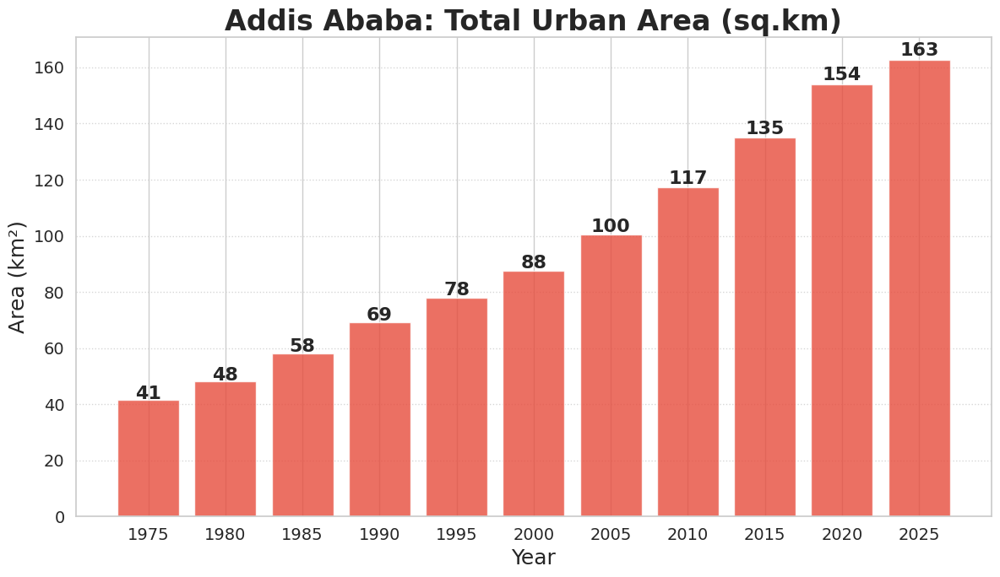

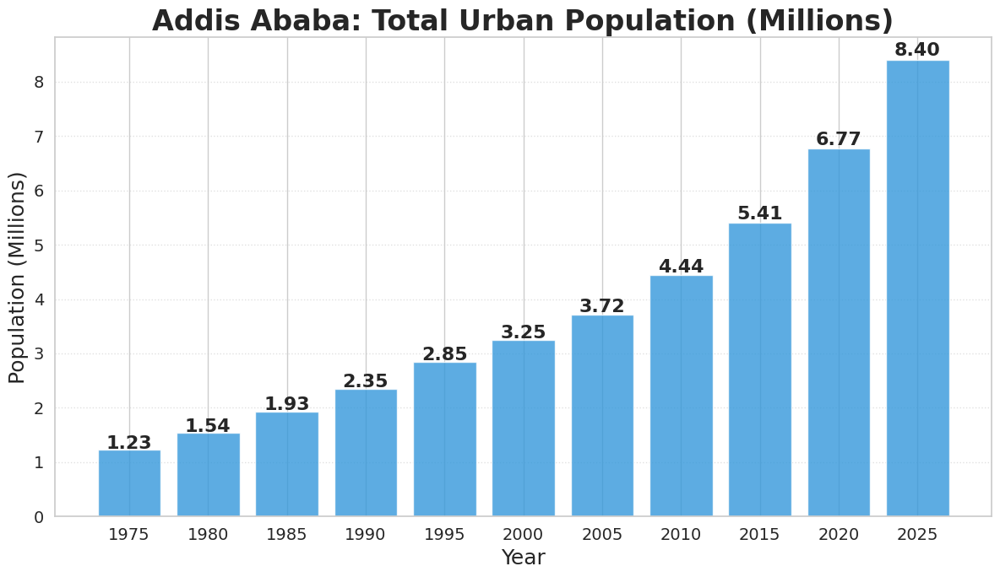

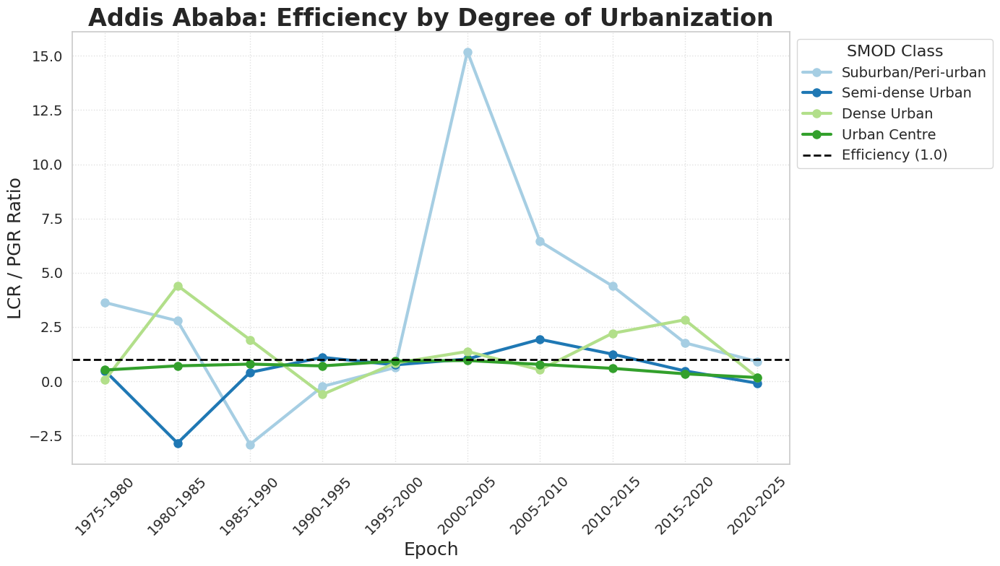

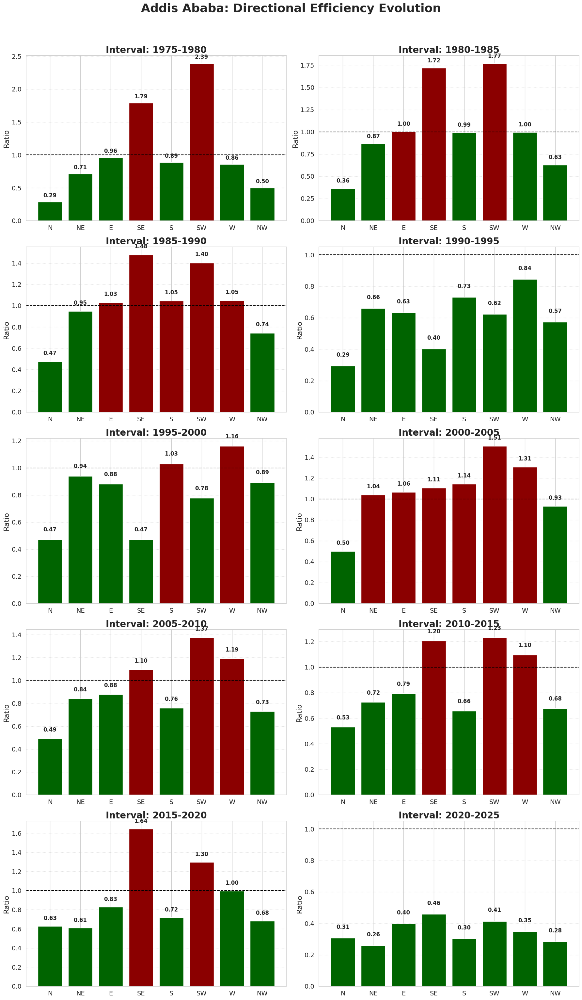


VISUALIZING: Dar es Salaam


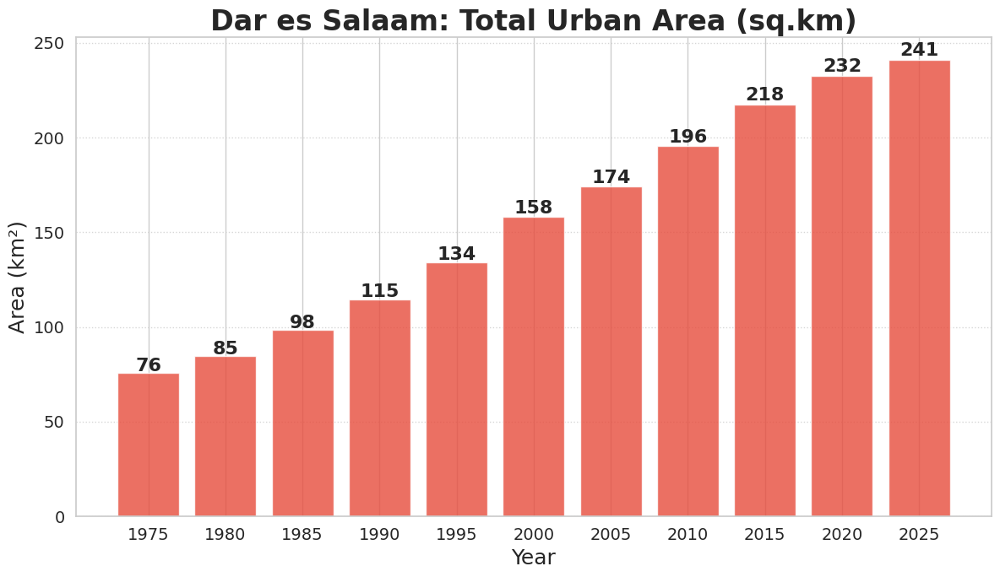

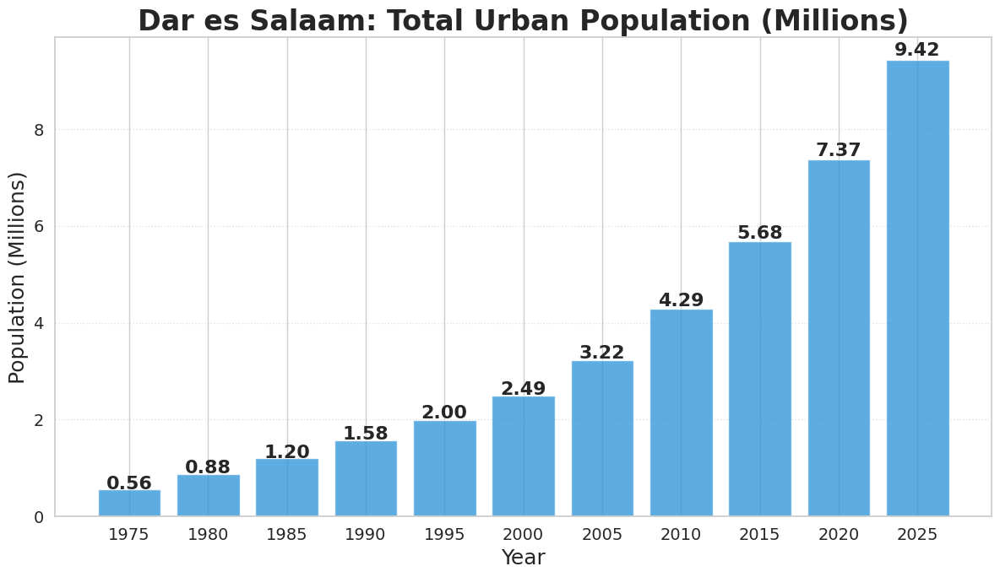

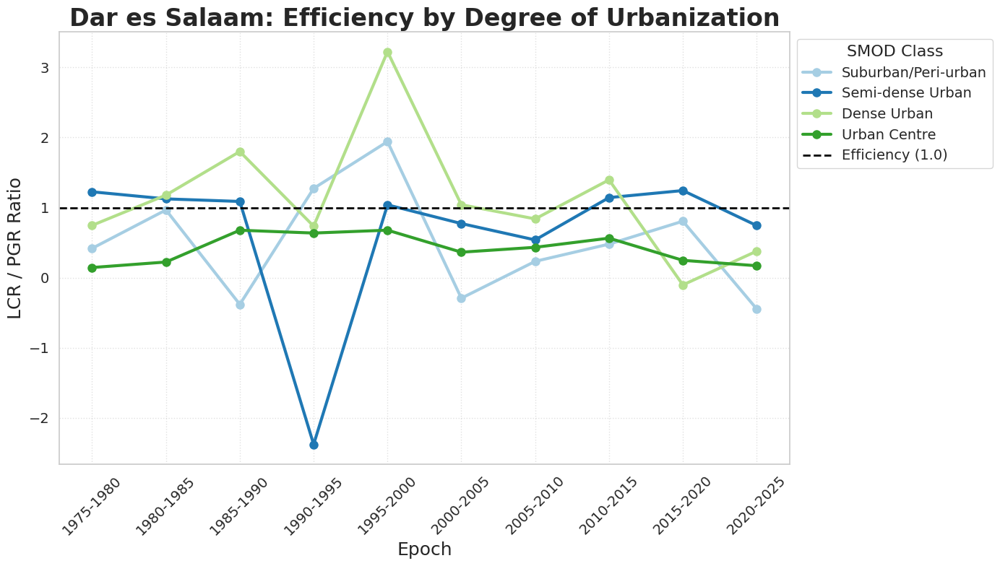

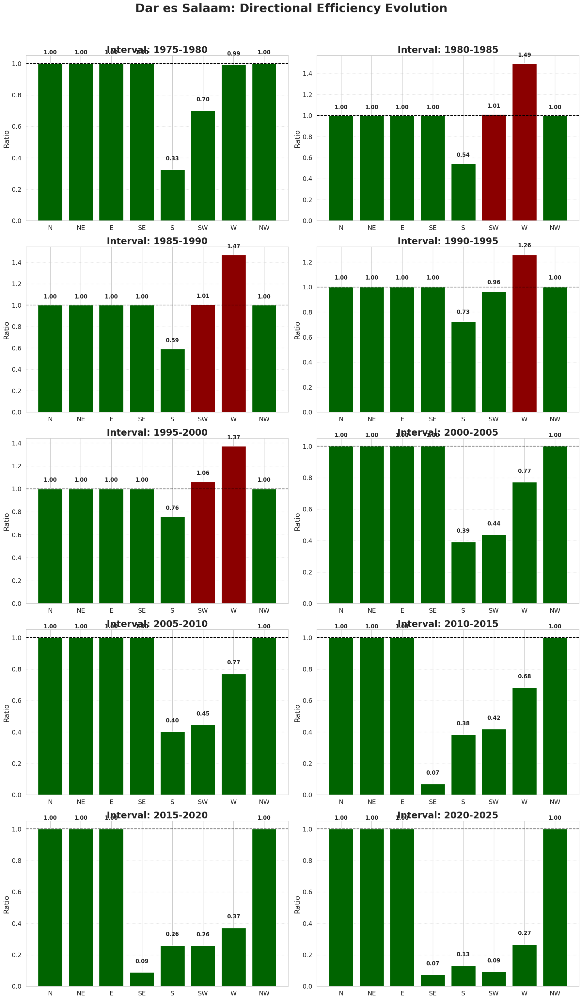


VISUALIZING: Kampala


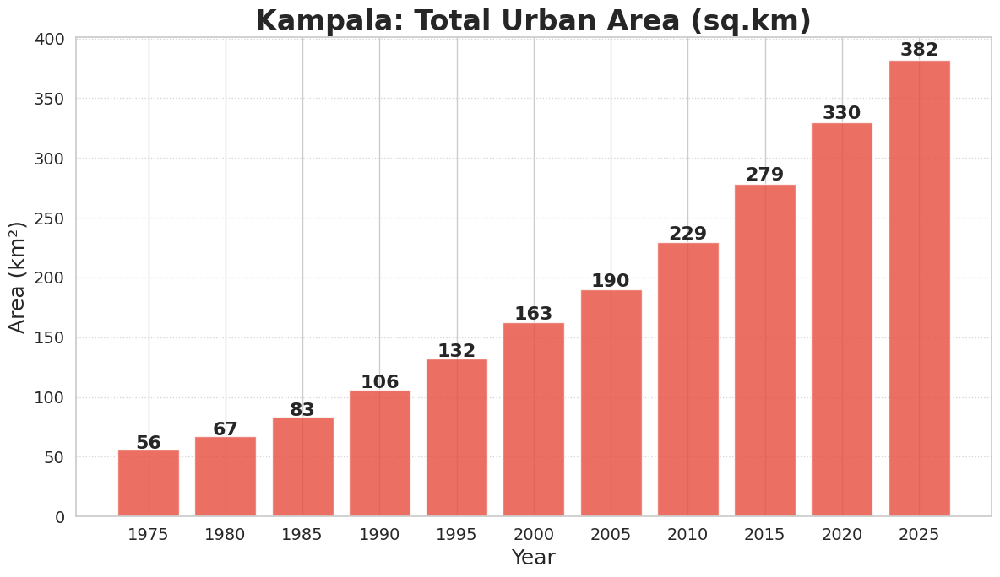

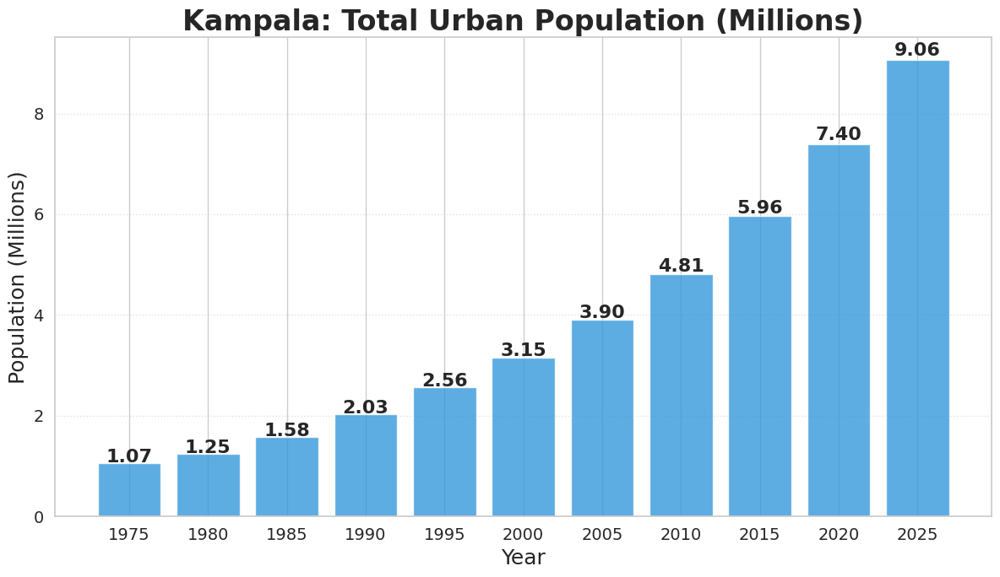

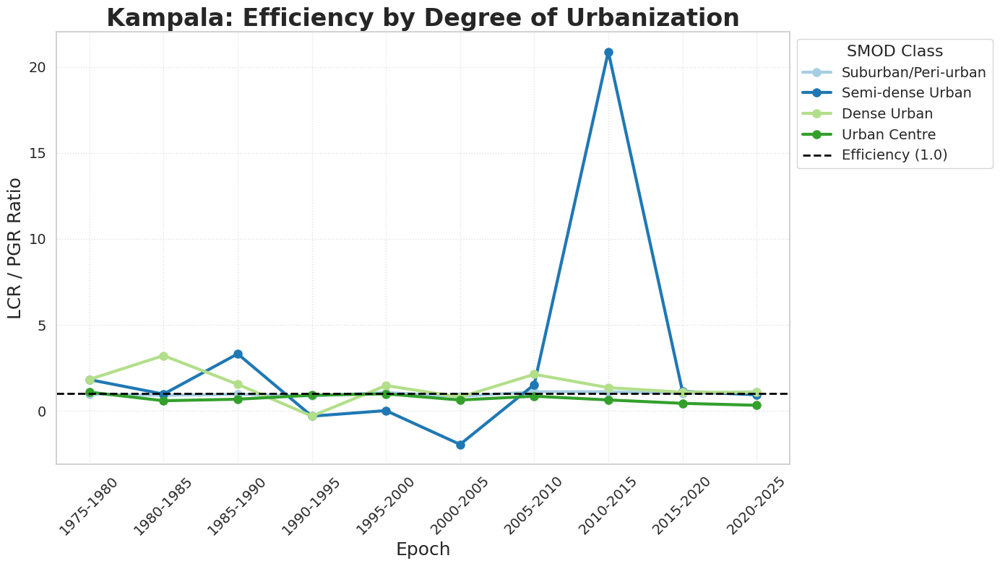

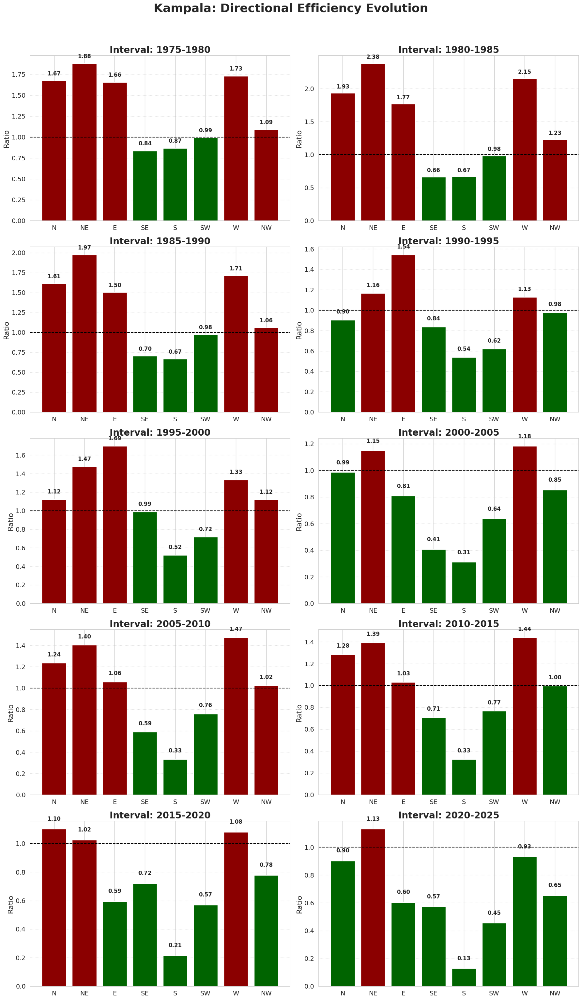


VISUALIZING: Nairobi


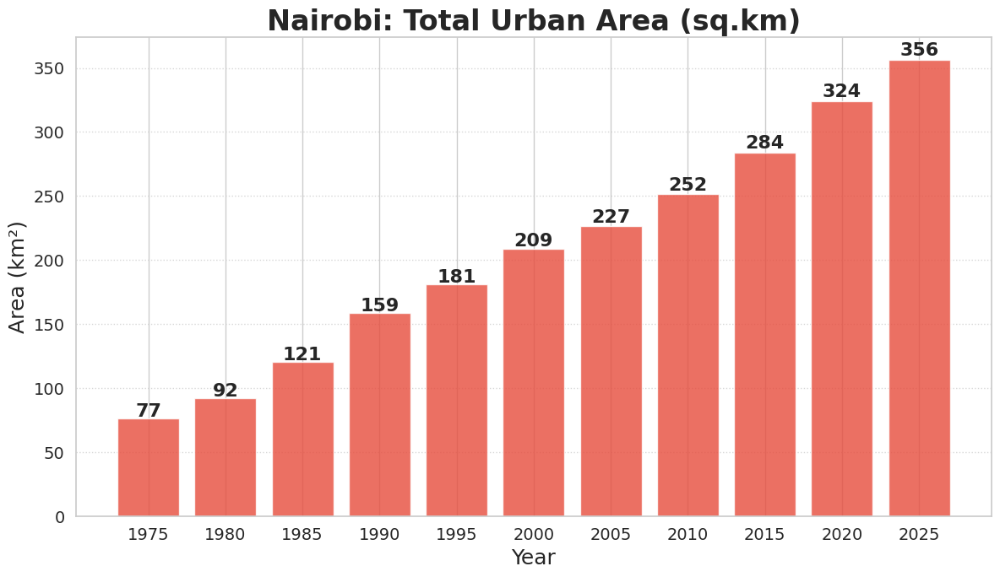

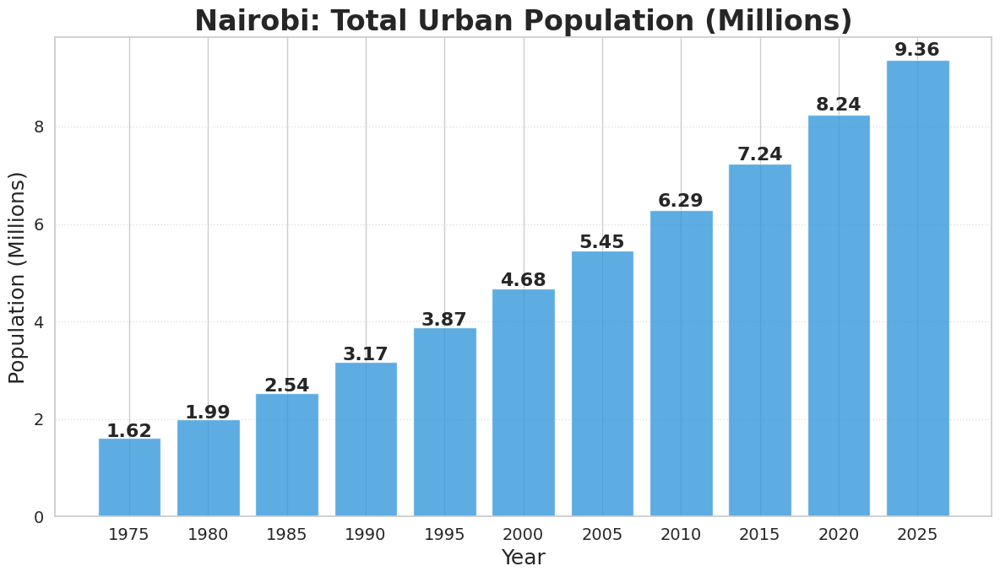

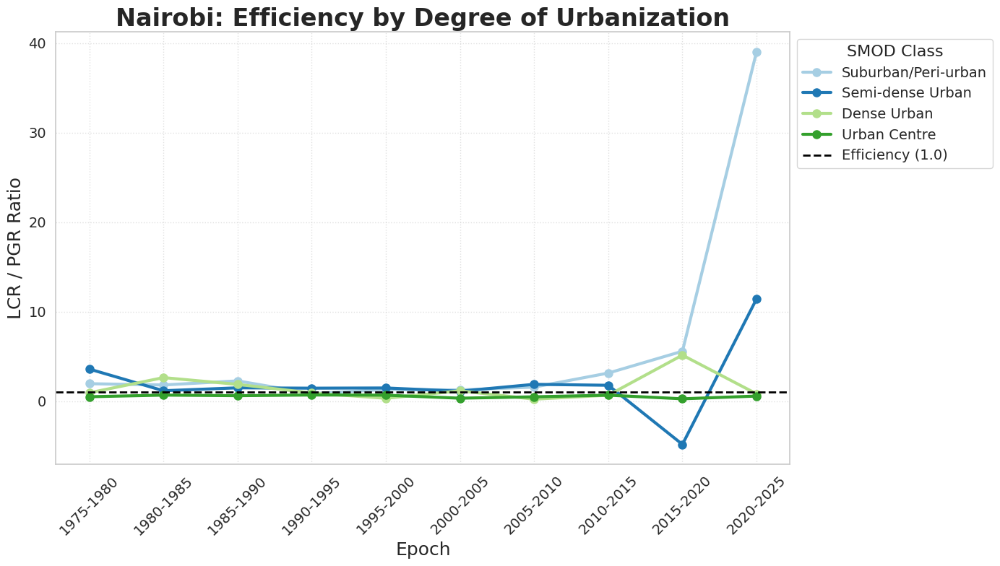

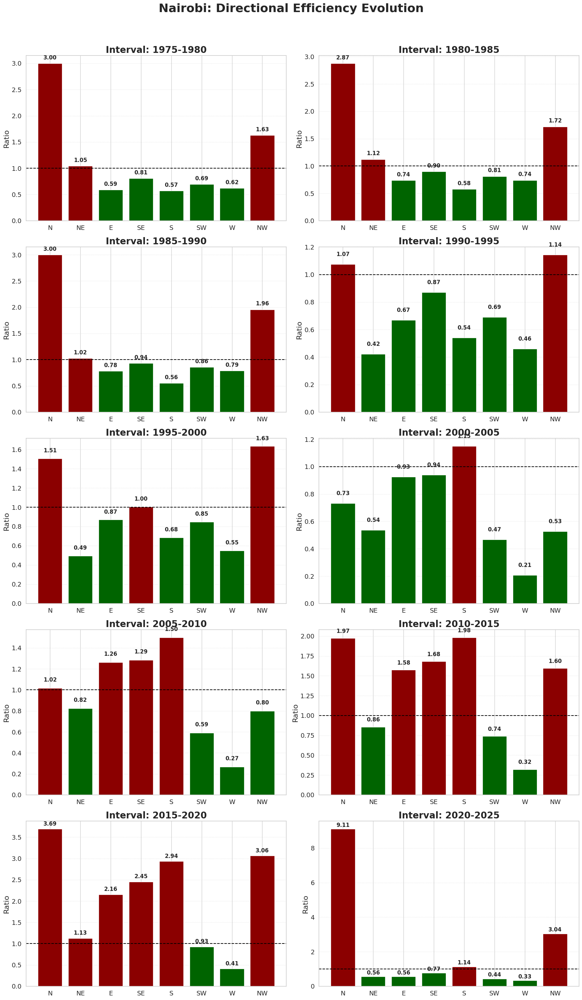

Generating Legible Comparative Plots and Exporting to Drive...


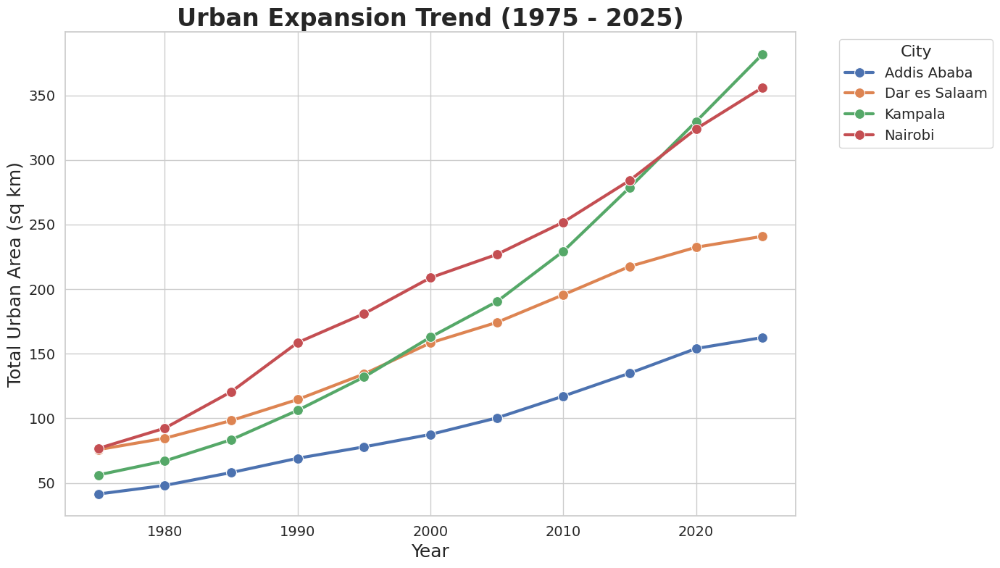

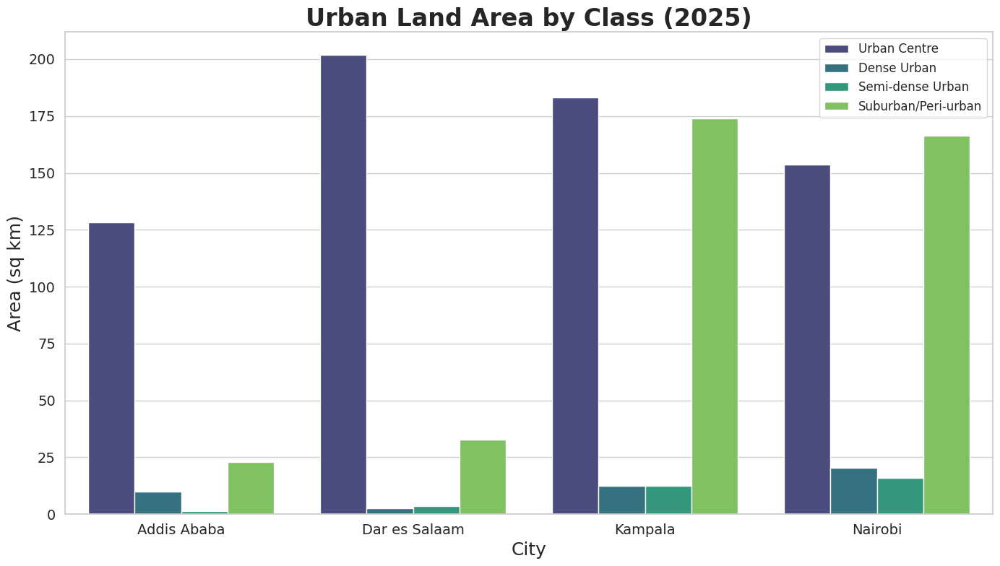

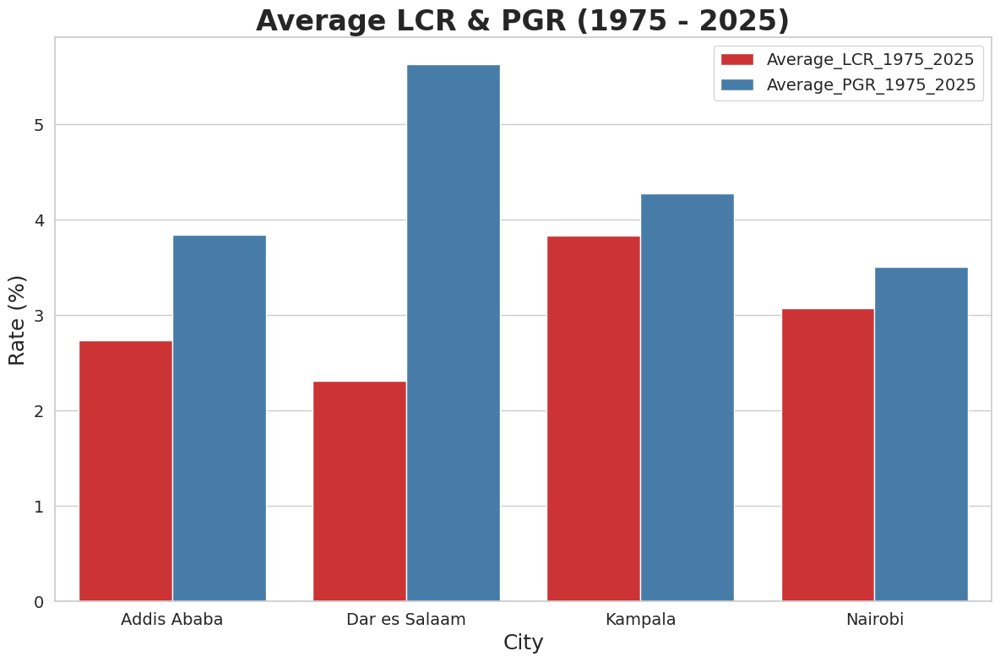

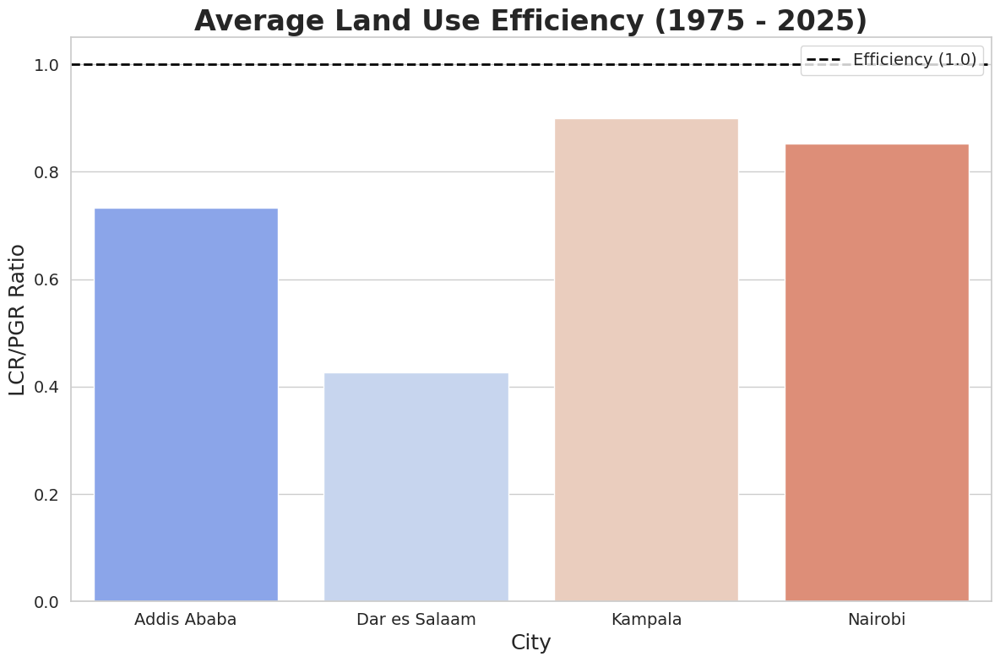

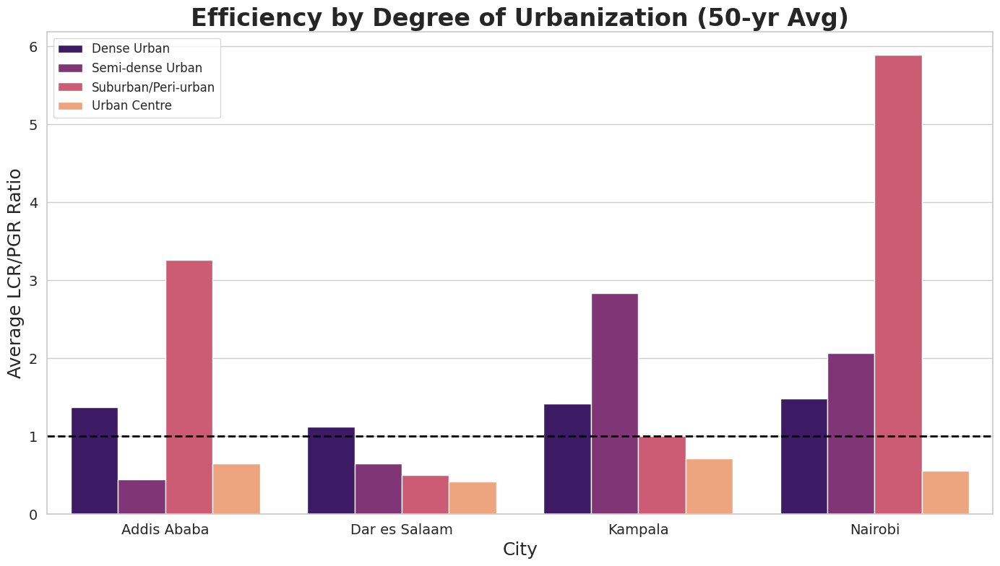


Processing legible exports for Addis Ababa...


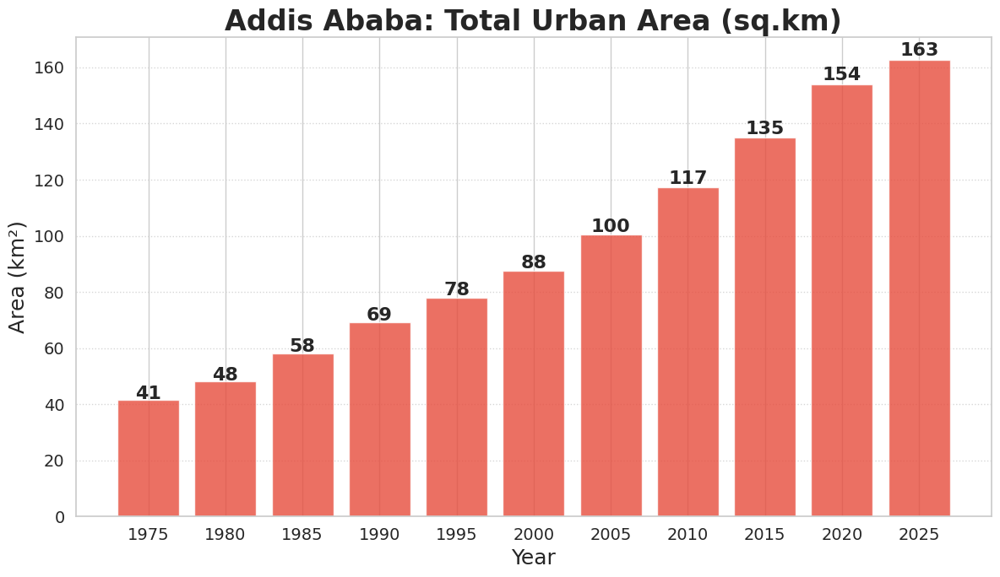

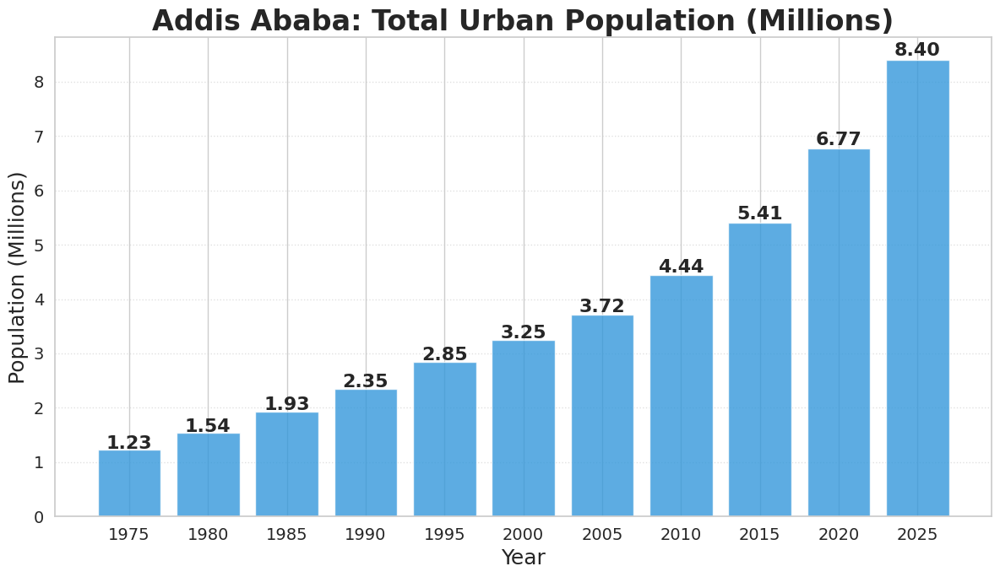

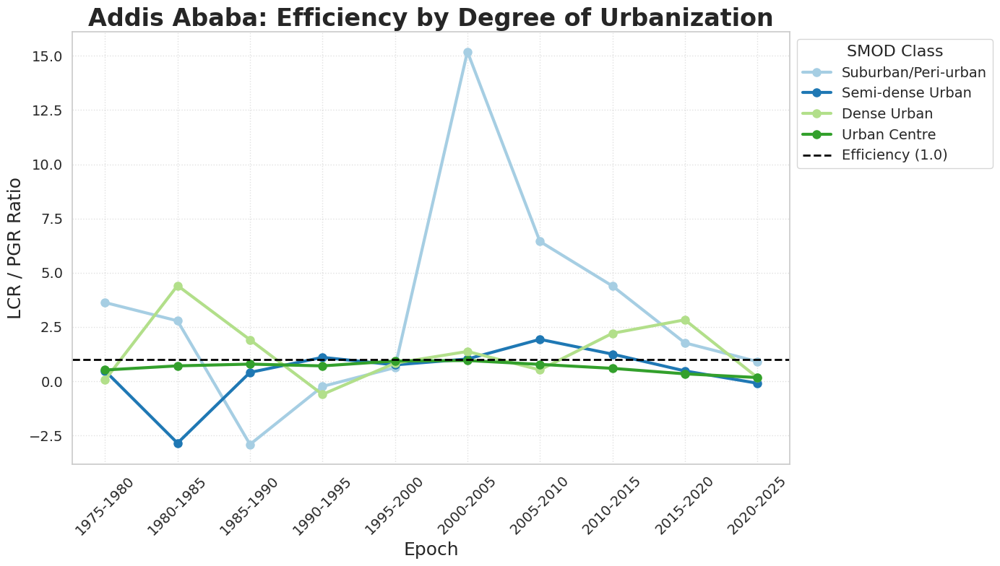


Processing legible exports for Dar es Salaam...


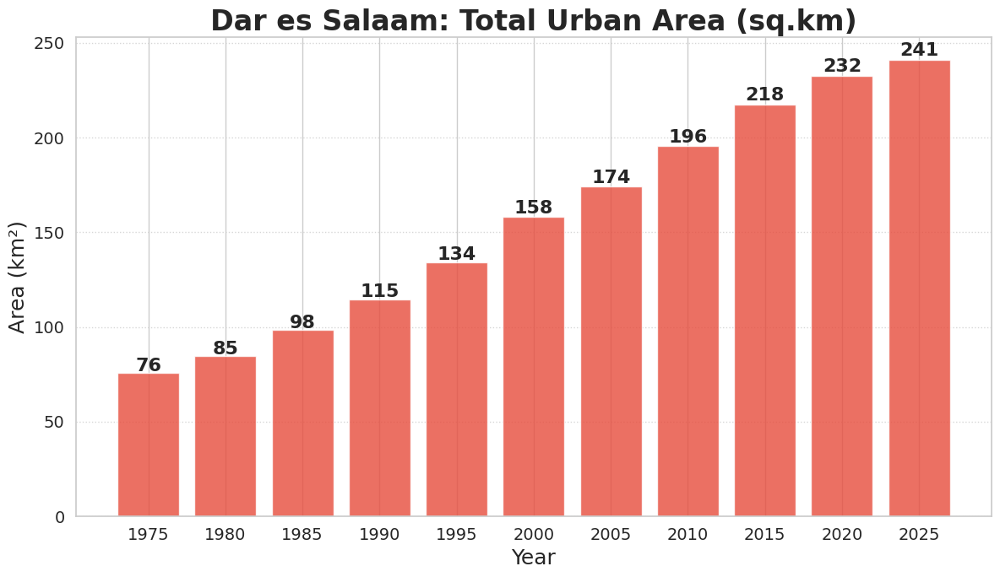

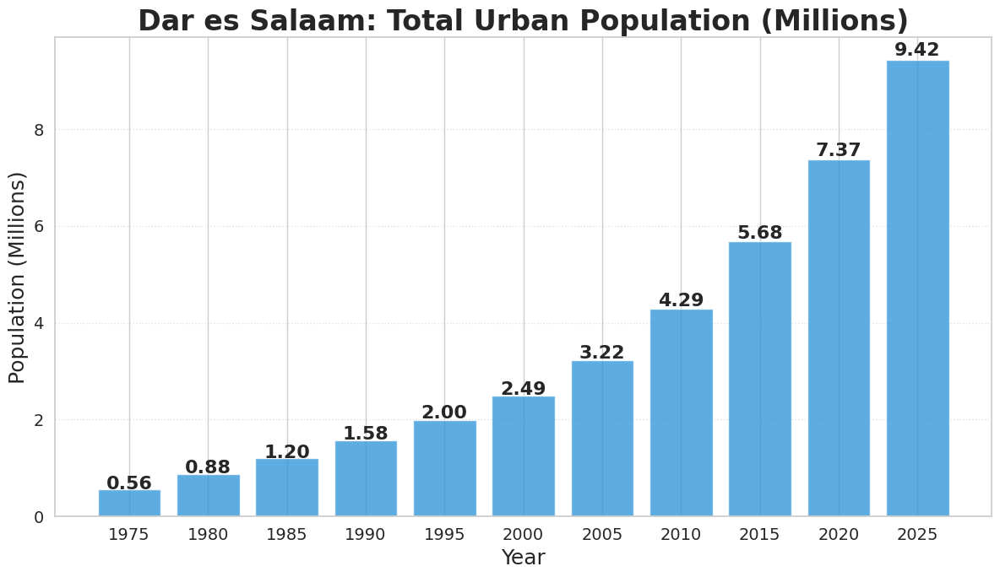

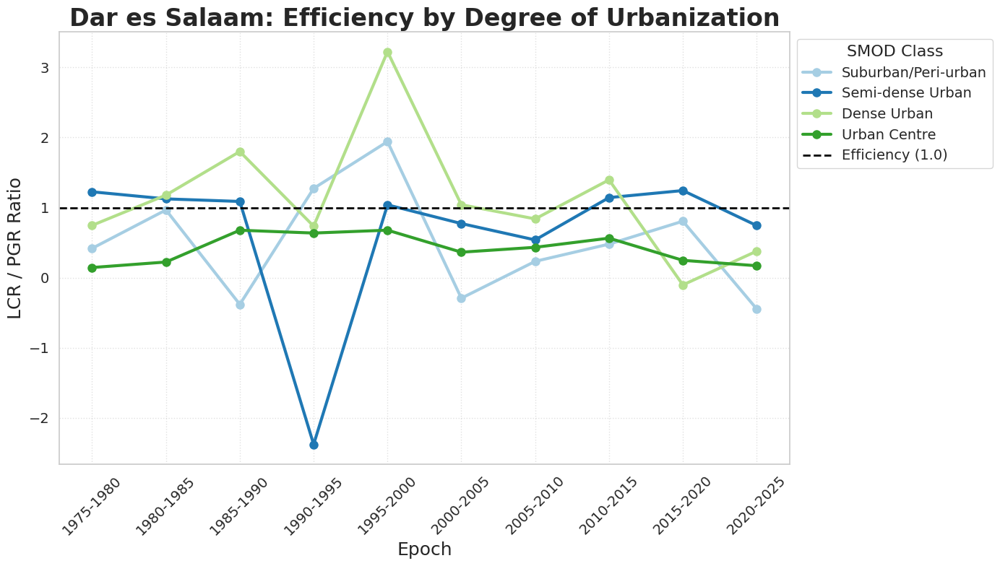


Processing legible exports for Kampala...


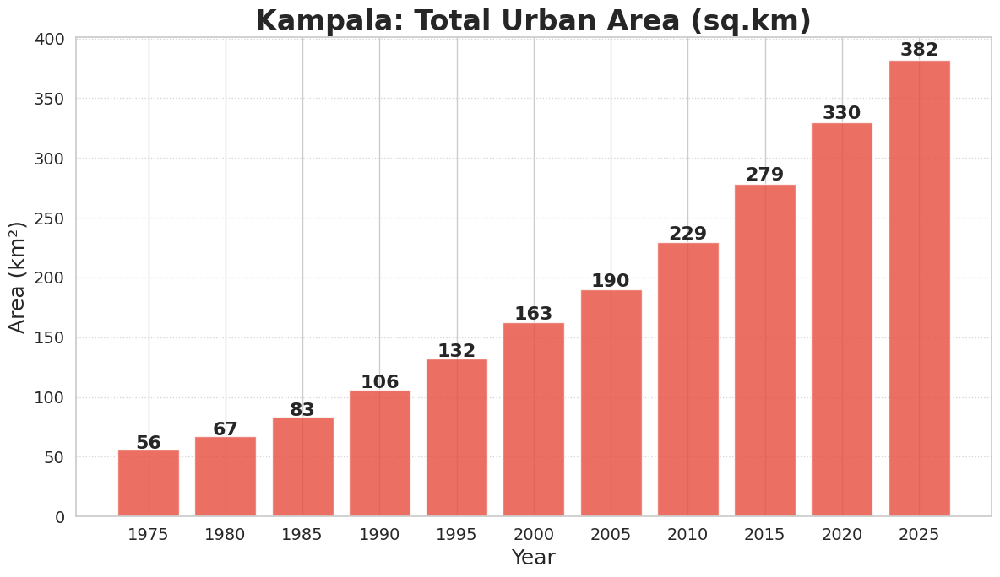

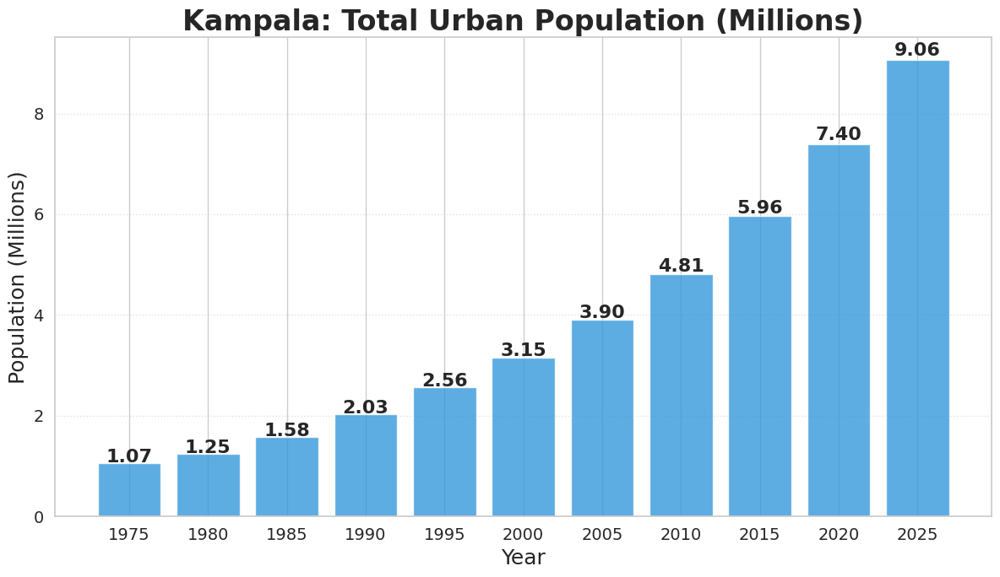

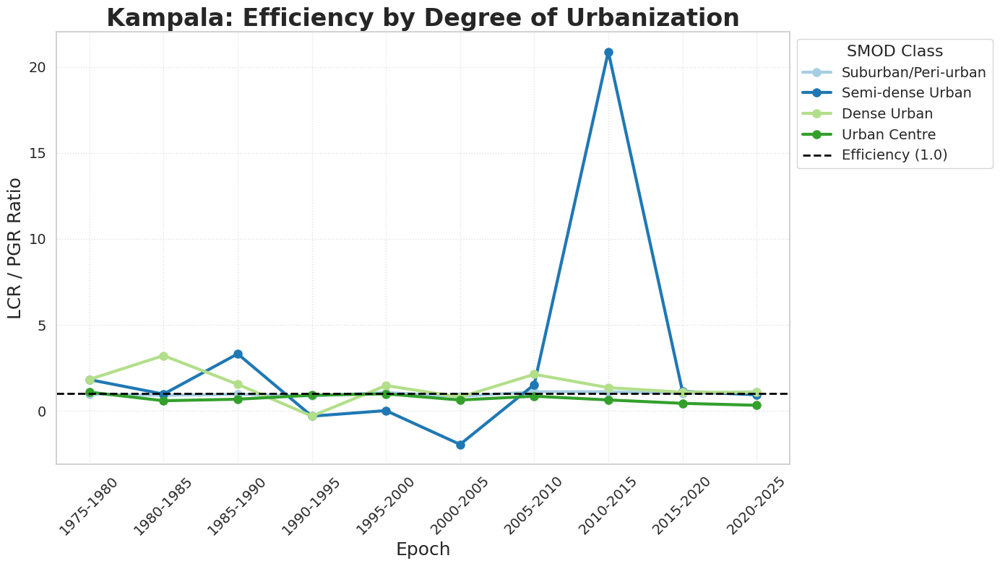


Processing legible exports for Nairobi...


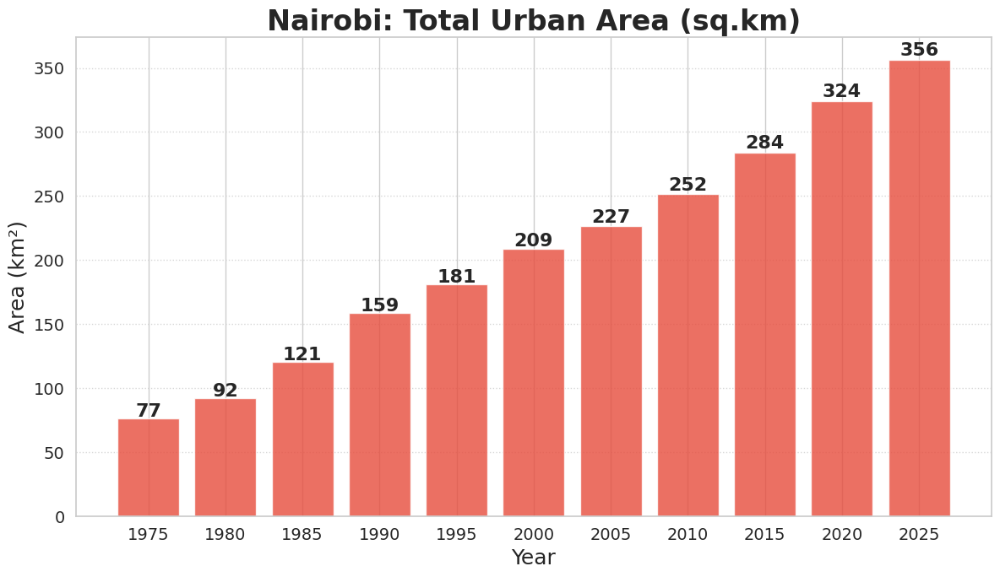

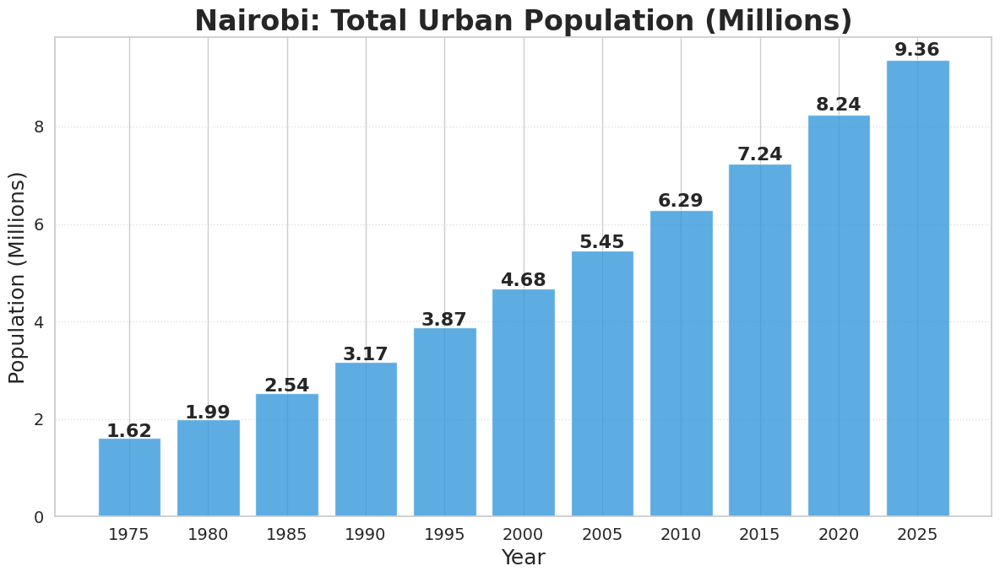

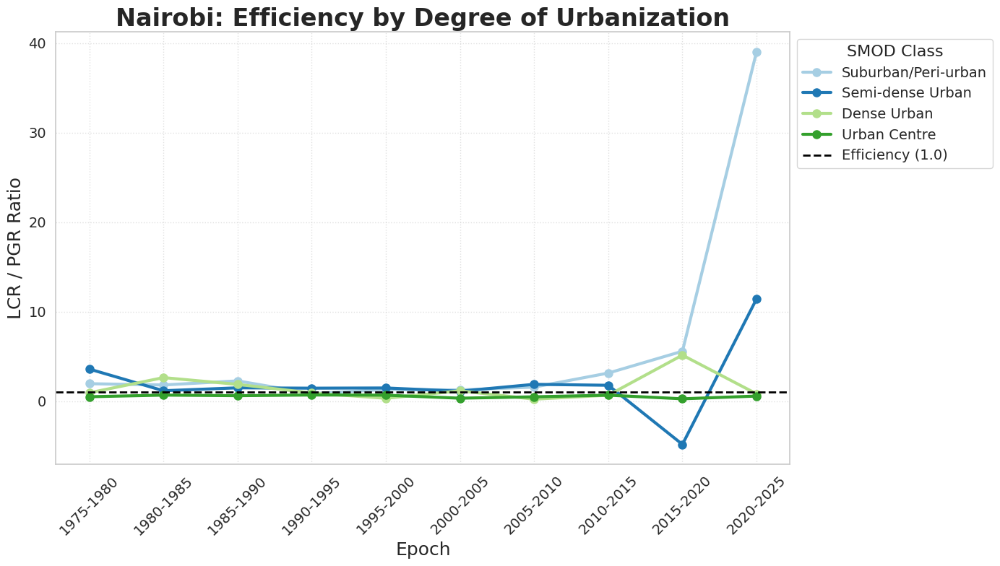

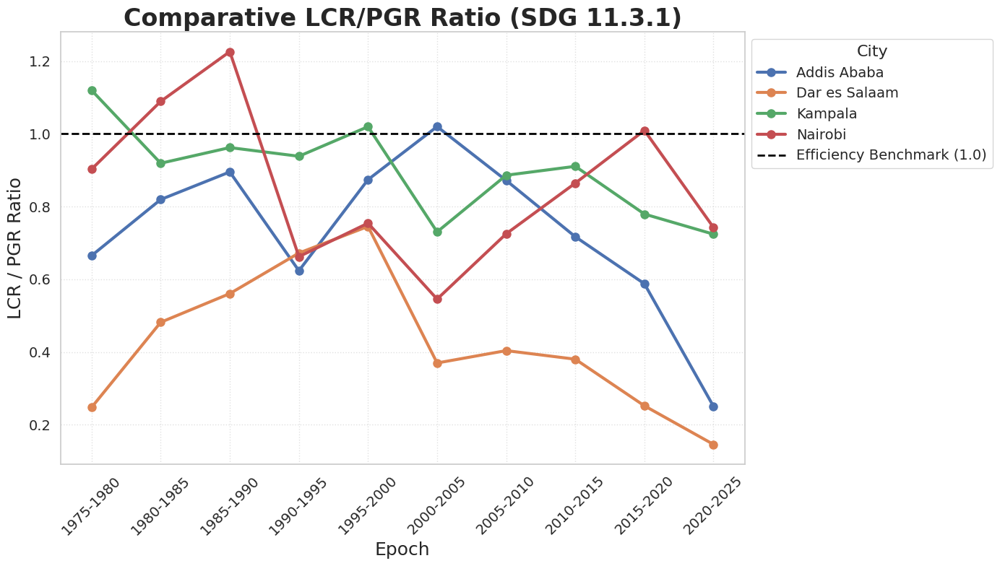


All legible analyses re-run and exports verified in Drive.


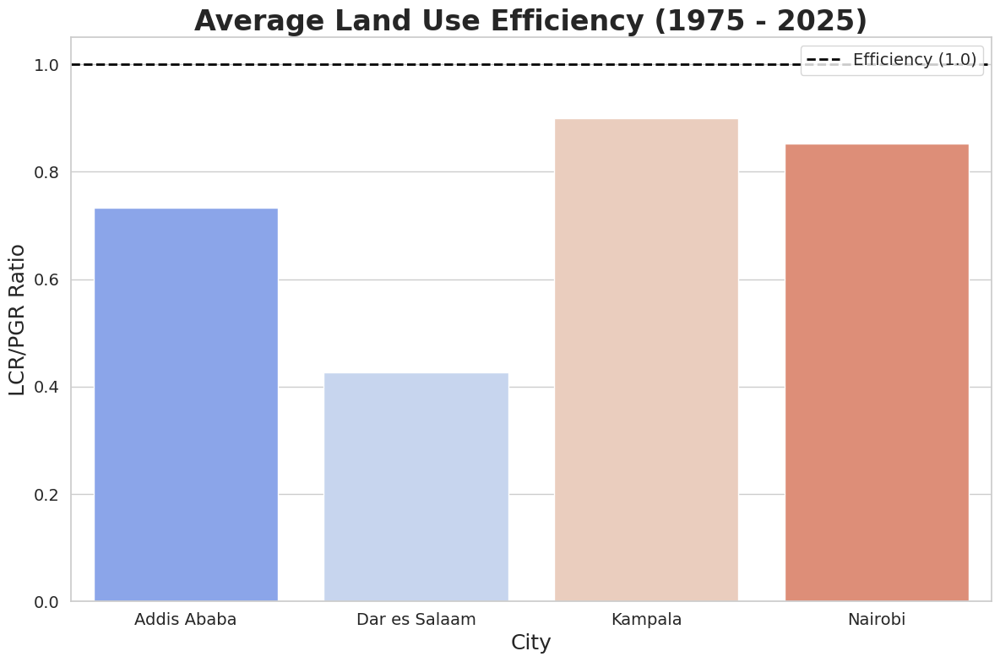

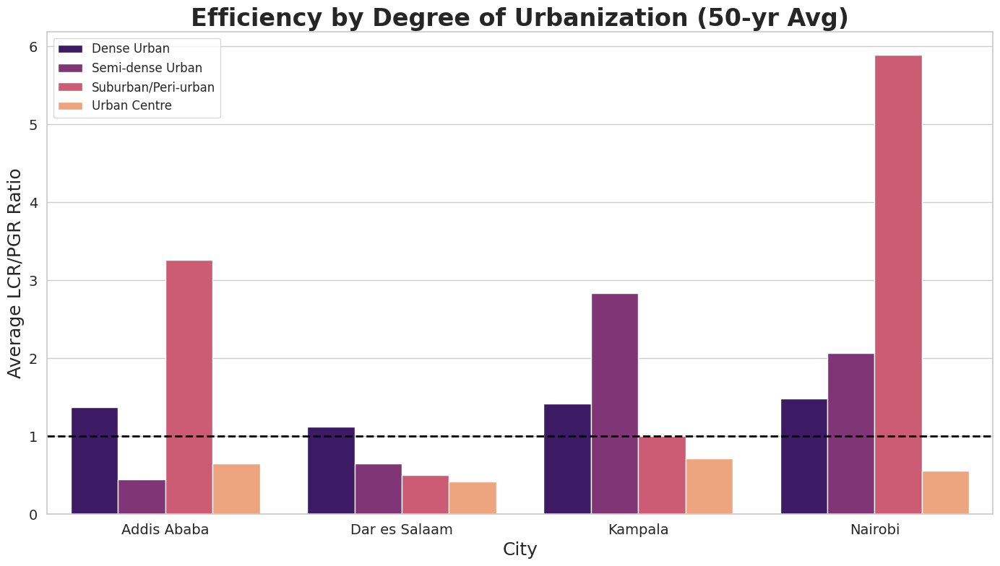


All analyses and unified plotting complete.


In [11]:
# ==============================================================================
# 6. MASTER EXECUTION: ALL PLOTS UNIFIED
# ==============================================================================

for city_name, data in cities_data.items():
    print(f"\n{'='*30}\nVISUALIZING: {city_name}\n{'='*30}")
    city_output_dir = os.path.join(BASE_EXPORT_PATH, city_name.replace(' ', '_'))
    os.makedirs(city_output_dir, exist_ok=True)

    # 1. Map
    center = ee.Geometry.Point(data['coords'])
    roi = center.buffer(data['radius_m'], maxError=1)
    smod_img_2025 = ee.Image(SMOD_ASSET + '2025').select('smod_code')
    urban30_mask = smod_img_2025.eq(30).selfMask().clip(roi)
    m = folium.Map(location=[data['coords'][1], data['coords'][0]], zoom_start=9)
    m.add_ee_layer(urban30_mask, {'palette': 'FF0000'}, 'SMOD 30 Urban Centre (2025)')
    display(m)

    # 2. City-Specific Absolute Trends
    df_city_total = pd.DataFrame(all_city_smod_raw)
    df_city_total = df_city_total[df_city_total['City'] == city_name].groupby('year')[['built_up_area_km2', 'total_population']].sum().reset_index()
    generate_growth_trend_charts(city_name, df_city_total, city_output_dir)

    # 3. SMOD Efficiency Breakdown (Line Chart per City)
    # Filter the list of DataFrames to find the one matching the current city
    df_city_smod_rates = pd.concat([df for df in all_cities_smod_rates if df['city'].iloc[0] == city_name])
    generate_smod_ratio_chart(city_name, df_city_smod_rates, city_output_dir)

    # 4. Directional Subplots
    if city_name in city_sectoral_rates:
      generate_all_intervals_subplot(city_name, city_sectoral_rates[city_name], city_output_dir)
# Re-triggering the unified execution with improved legibility and verified exports

plt.close('all')

# 2. Update stats and pivot tables
results_df = pd.DataFrame(all_city_smod_raw).pivot_table(
    index=['City', 'year'], columns='smod_class', values='built_up_area_km2', fill_value=0
).reset_index()
results_df.rename(columns={'year': 'Year', 21: 'Suburban/Peri-urban', 22: 'Semi-dense Urban', 23: 'Dense Urban', 30: 'Urban Centre'}, inplace=True)

df_city_averages = pd.DataFrame(city_averages)
df_all_smod = pd.concat(all_cities_smod_rates, ignore_index=True)
df_all_smod['Degree of Urbanization'] = df_all_smod['smod_class'].map(SMOD_LABELS)
smod_efficiency_table = df_all_smod.groupby(['city', 'Degree of Urbanization'])['LCRPGR_Ratio'].mean().unstack()

# 3. Generate Legible Comparative Plots
print("Generating Legible Comparative Plots and Exporting to Drive...")
plot_urban_expansion_trend(results_df)
plot_urbanization_degree_2025(results_df)
plot_avg_growth_rates(df_city_averages)
plot_avg_efficiency_ratio(df_city_averages)
plot_efficiency_by_smod(smod_efficiency_table)

# 4. Generate Legible City-Specific Folders
for city_name, data in cities_data.items():
    print(f"\nProcessing legible exports for {city_name}...")
    city_output_dir = os.path.join(BASE_EXPORT_PATH, city_name.replace(' ', '_'))
    os.makedirs(city_output_dir, exist_ok=True)

    # Trends
    df_city_total = pd.DataFrame(all_city_smod_raw)
    df_city_total = df_city_total[df_city_total['City'] == city_name].groupby('year')[['built_up_area_km2', 'total_population']].sum().reset_index()
    generate_growth_trend_charts(city_name, df_city_total, city_output_dir)

    # SMOD Line Chart
    df_city_smod_rates = pd.concat([df for df in all_cities_smod_rates if df['city'].iloc[0] == city_name])
    generate_smod_ratio_chart(city_name, df_city_smod_rates, city_output_dir)

    # Directional Subplots
    if city_name in city_sectoral_rates:
      pass
      #generate_all_intervals_subplot(city_name, city_sectoral_rates[city_name], city_output_dir)

# 5. Final Comparative Ratio Plot
df_all_cities_rates = pd.concat(all_cities_aggregate_rates, ignore_index=True)
generate_comparative_ratio_chart(df_all_cities_rates, BASE_EXPORT_PATH)

print("\nAll legible analyses re-run and exports verified in Drive.")
plot_avg_efficiency_ratio(df_city_averages)
plot_efficiency_by_smod(smod_efficiency_table)

print("\nAll analyses and unified plotting complete.")

**Cell purpose.** Repeat the visualization pass with improved legibility and verified export settings.

The original code and saved output are retained unchanged.

Generating Legible Comparative Plots and Exporting to Drive...


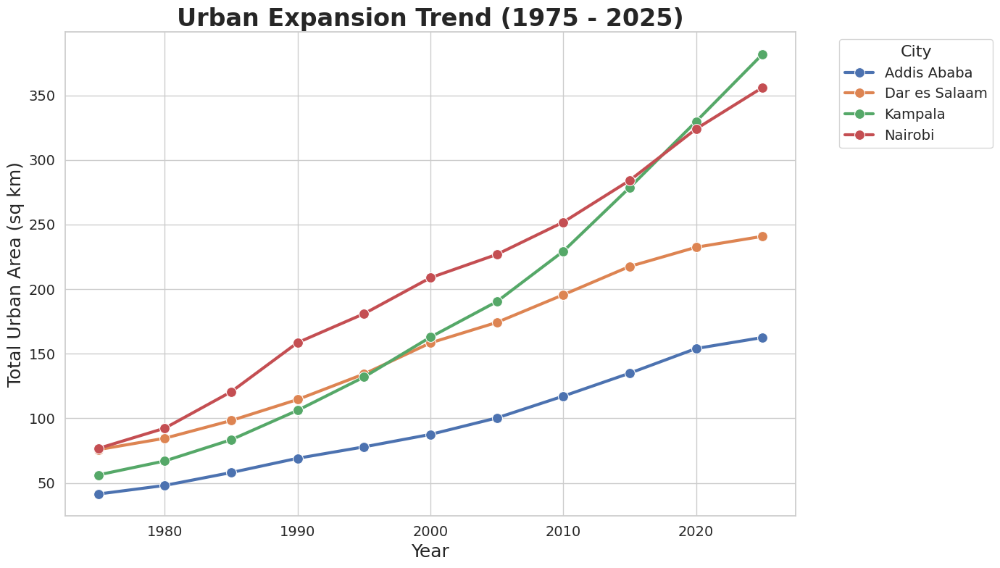

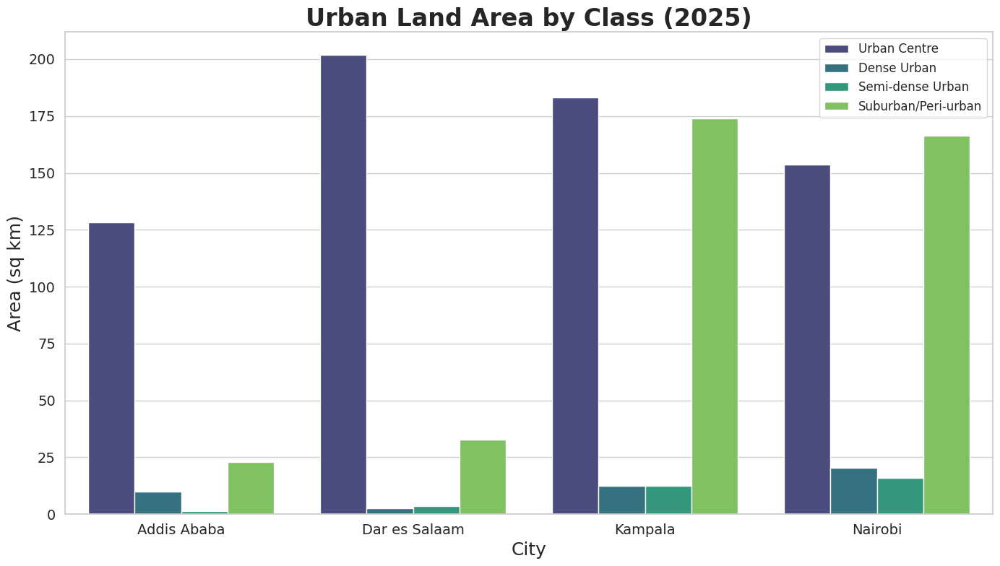

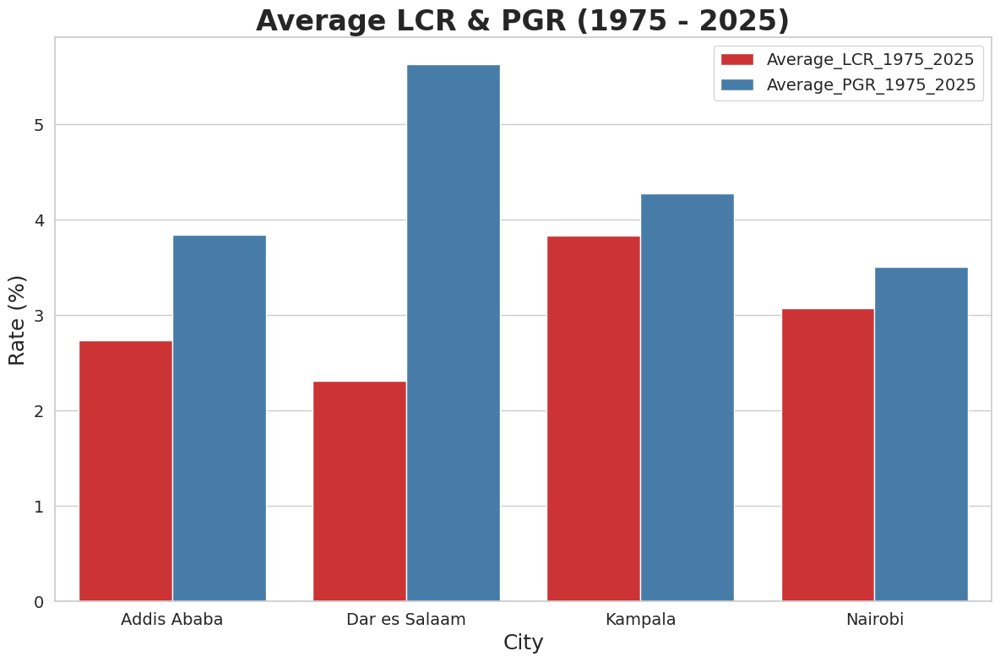

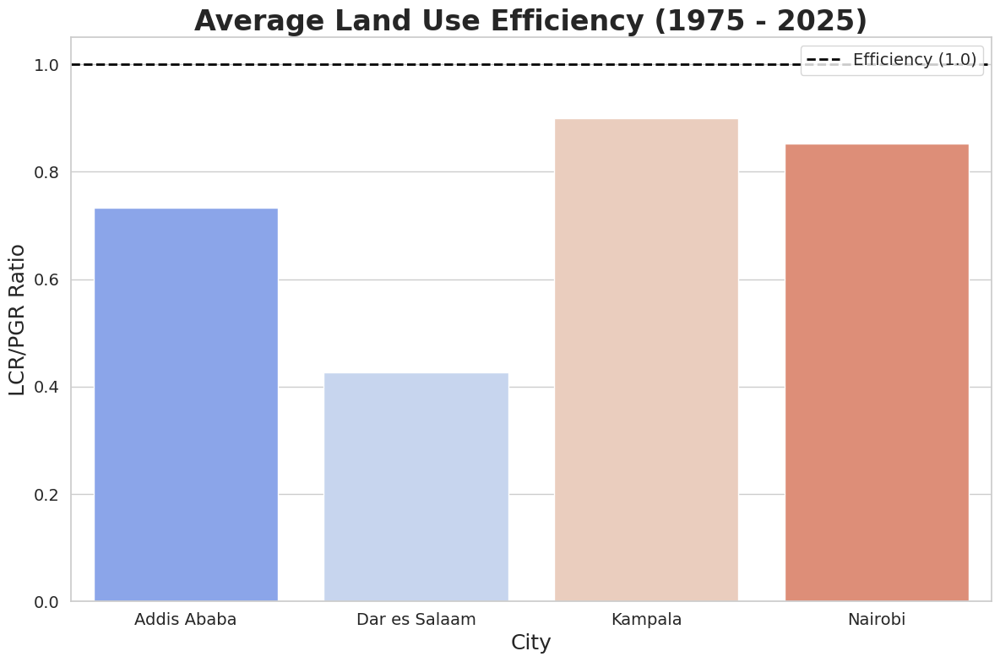

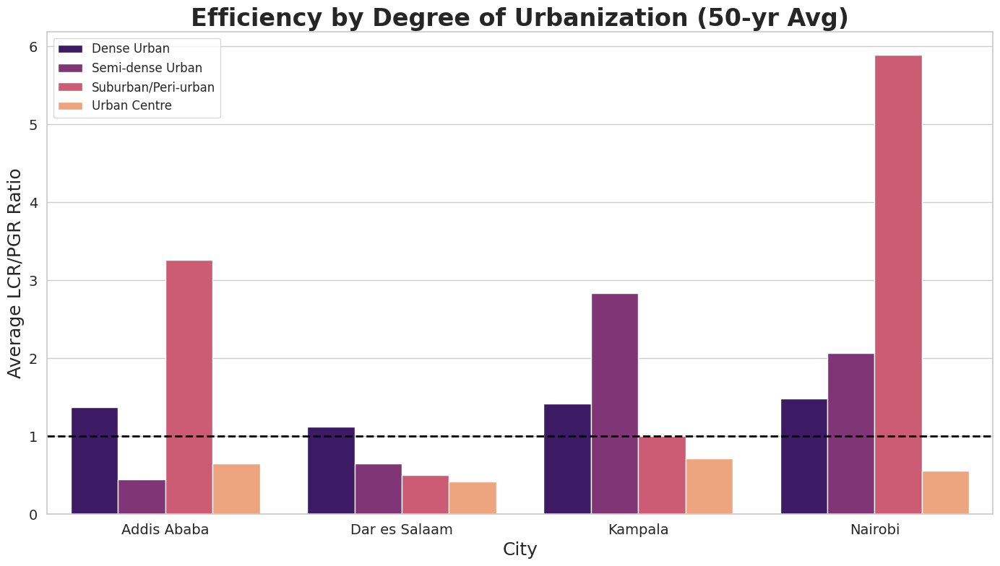


Processing legible exports for Addis Ababa...


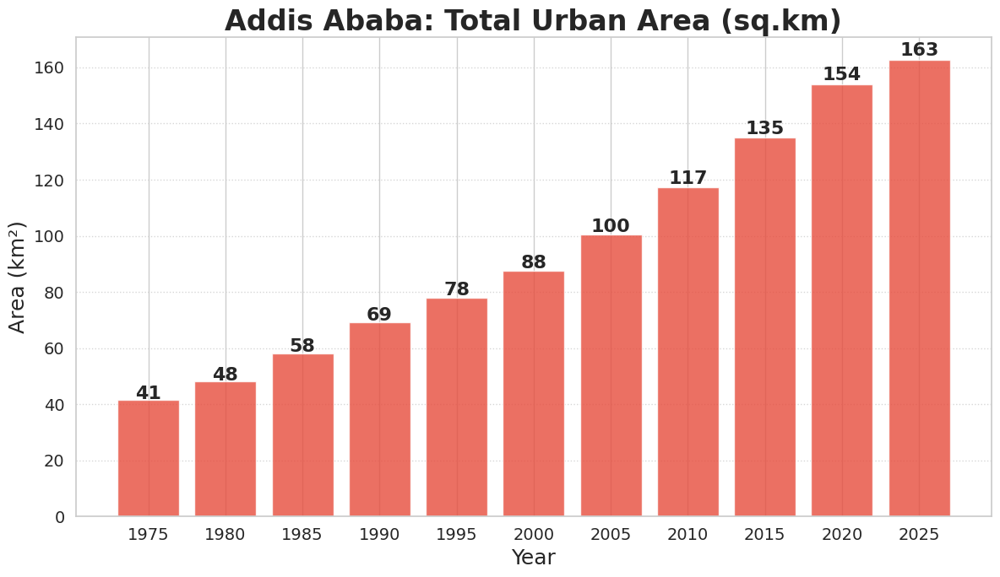

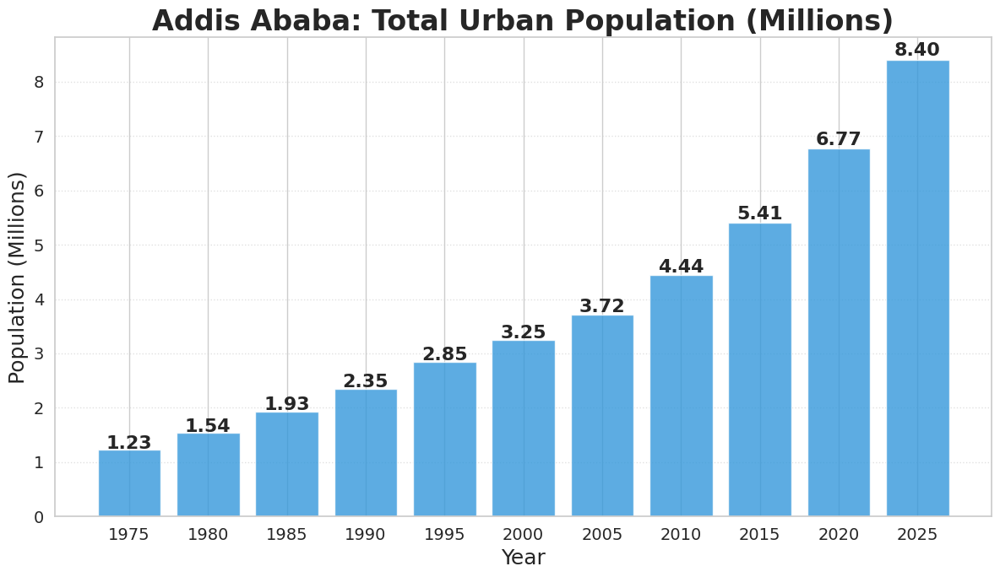

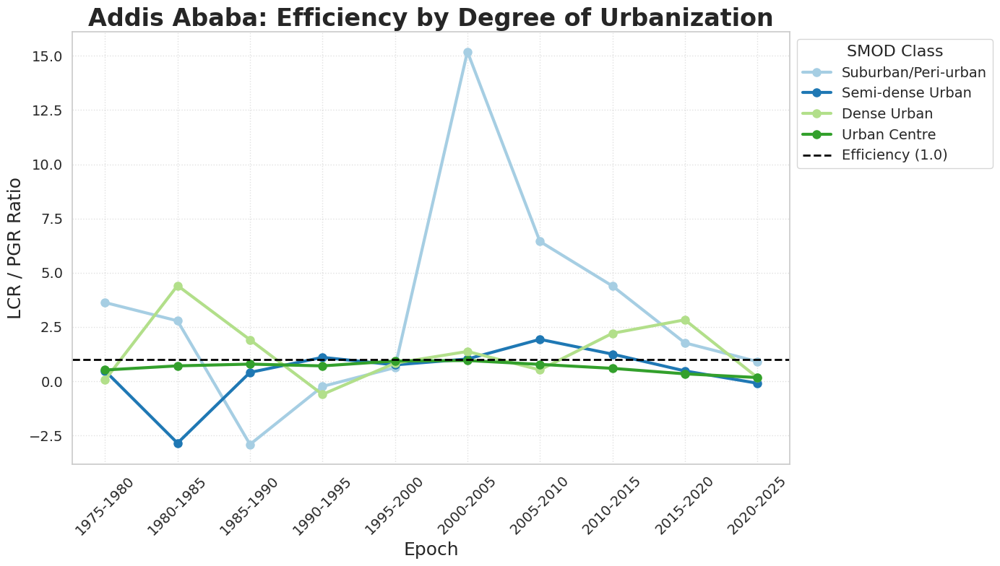

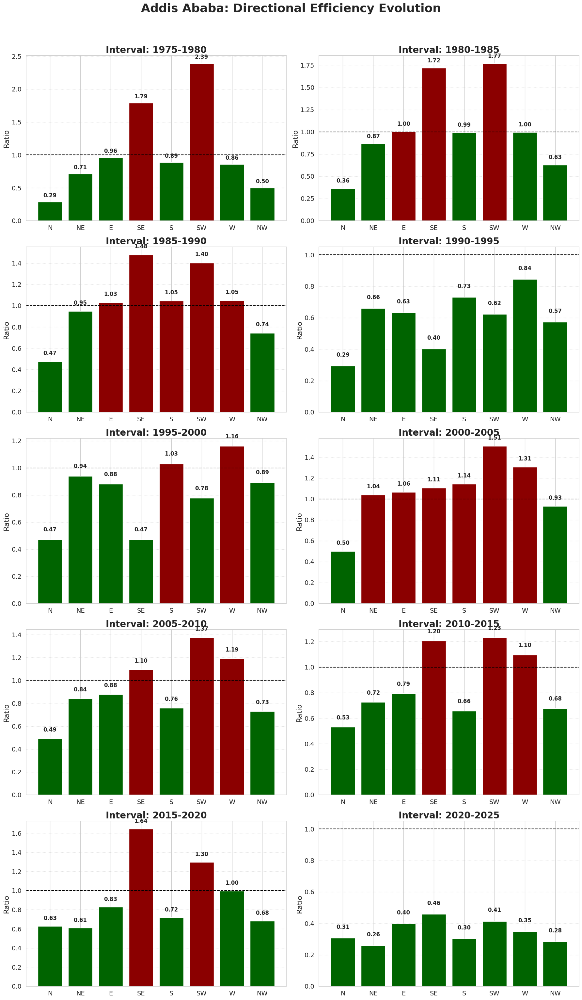


Processing legible exports for Dar es Salaam...


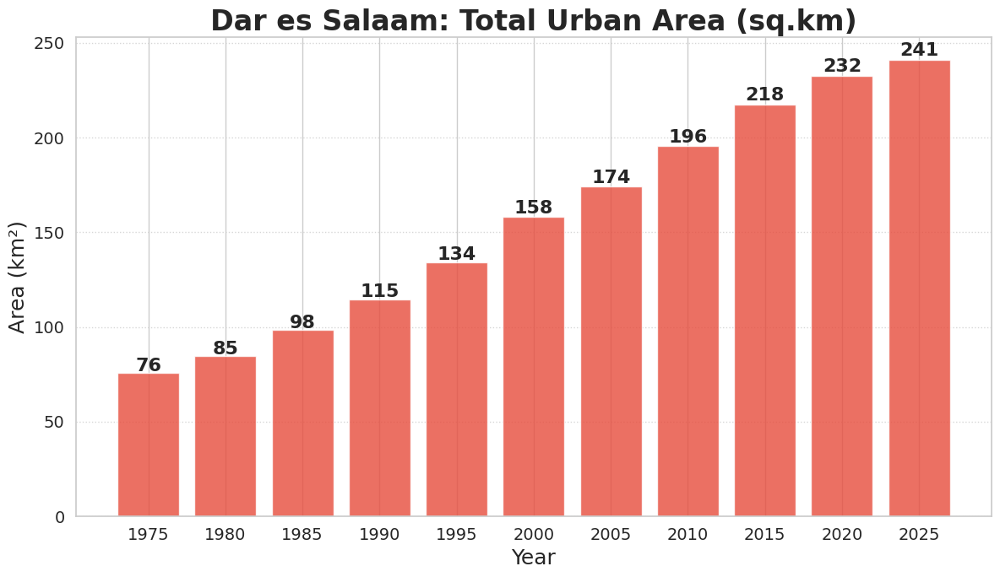

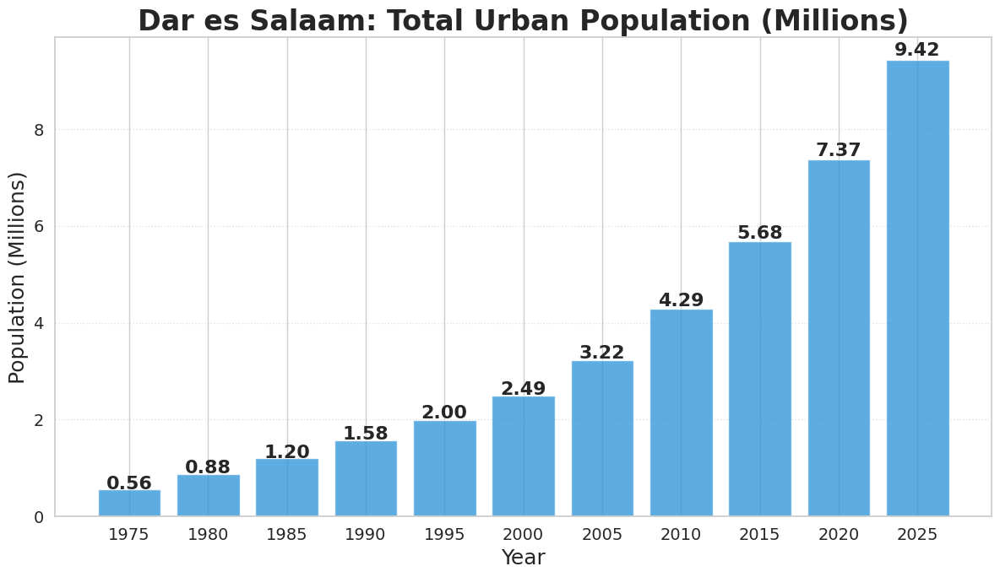

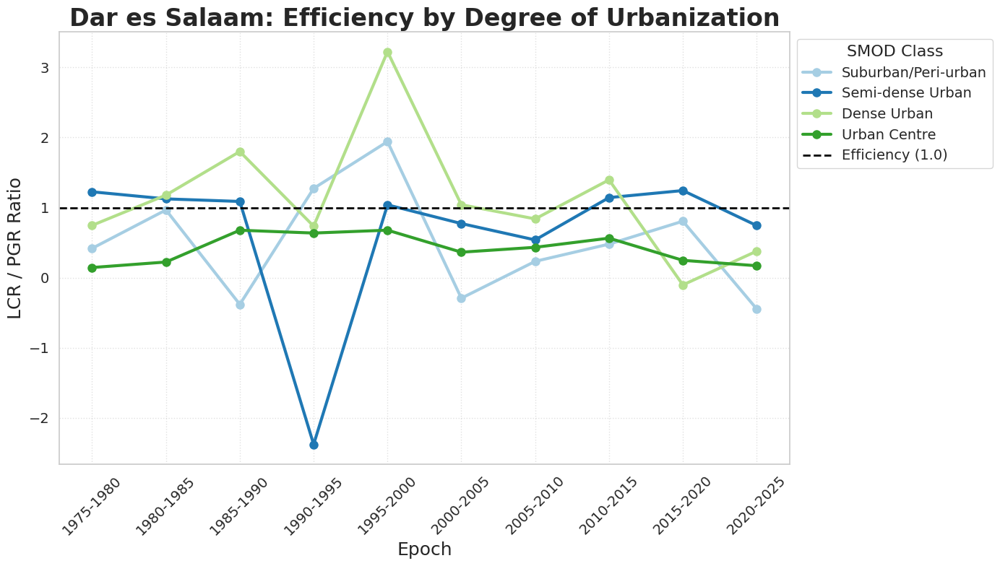

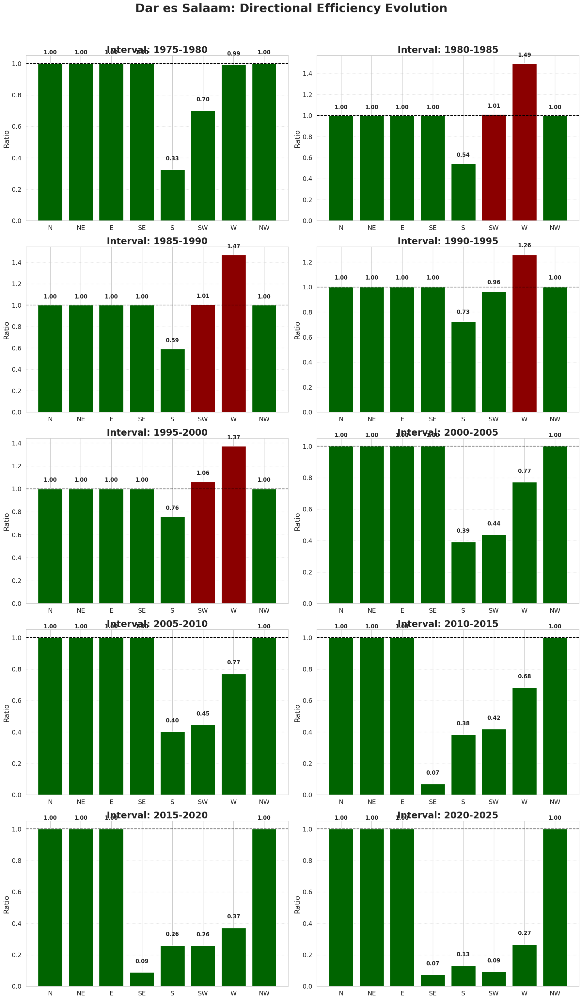


Processing legible exports for Kampala...


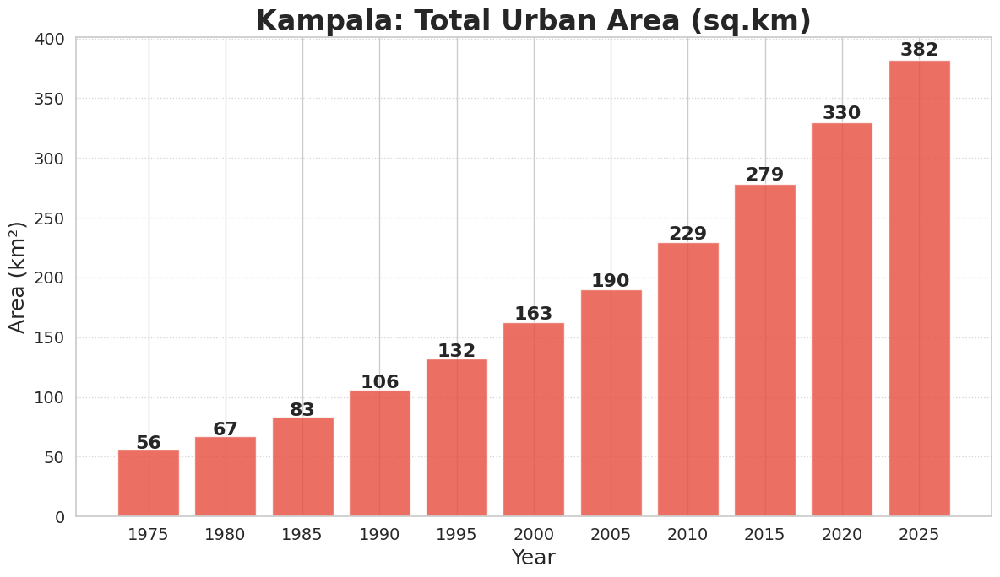

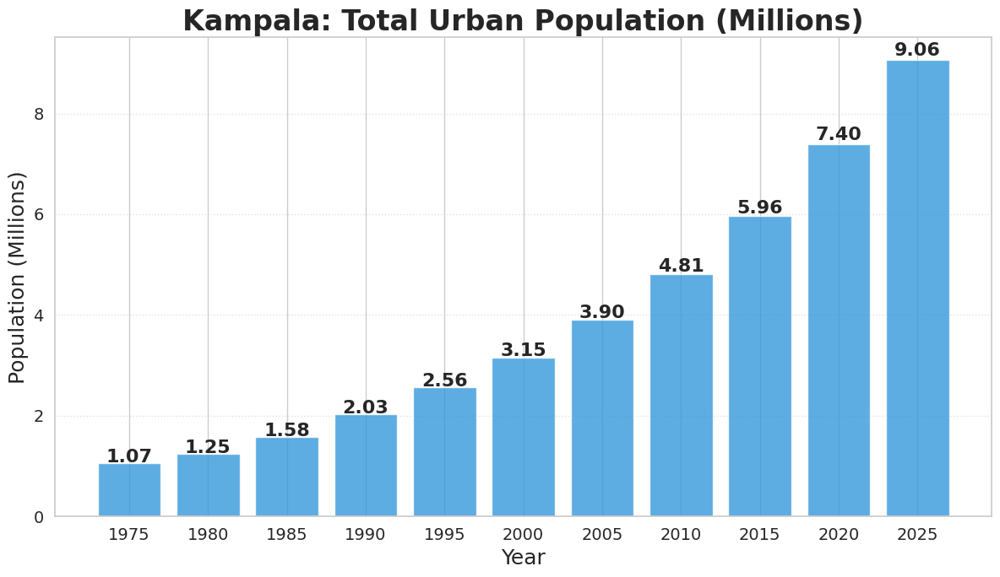

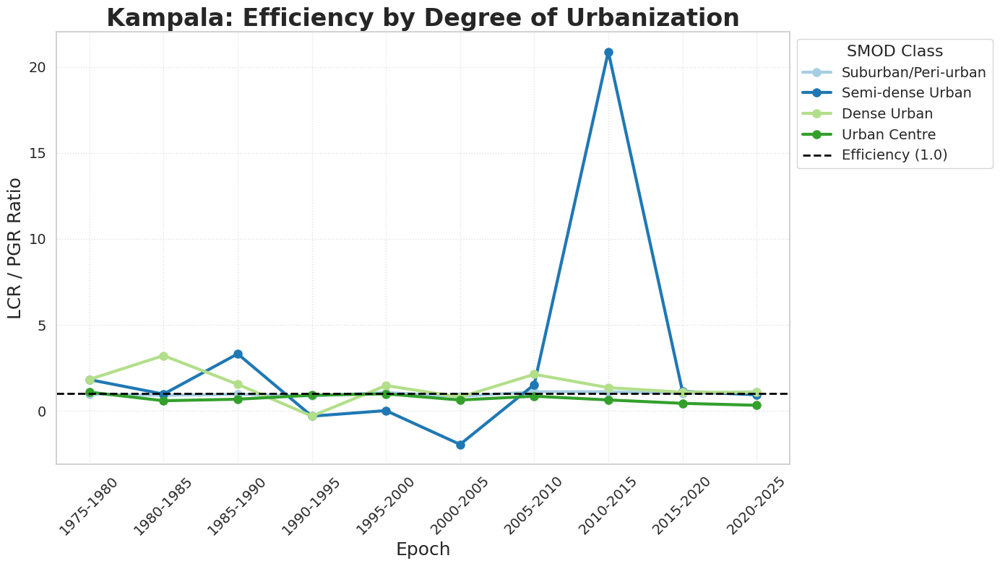

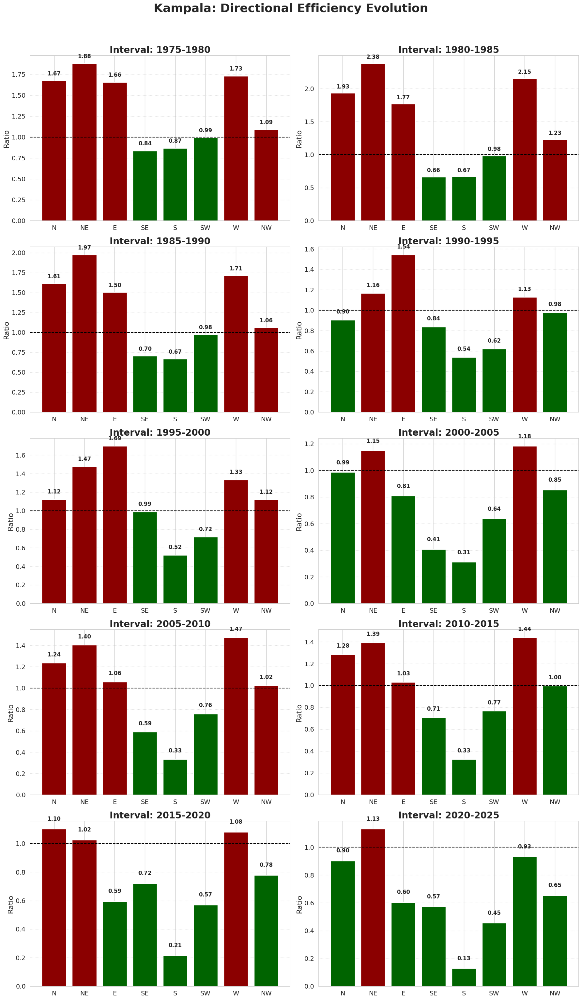


Processing legible exports for Nairobi...


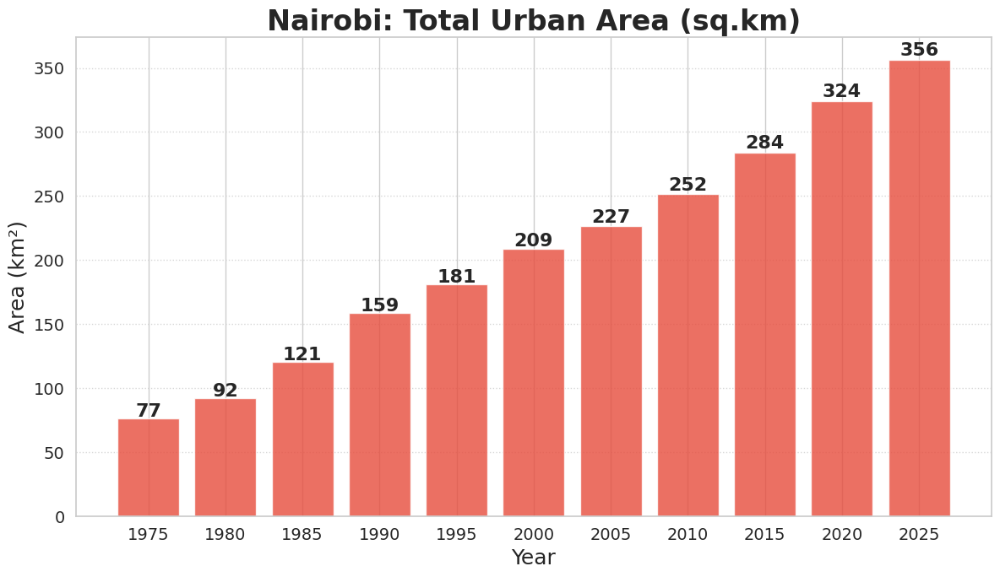

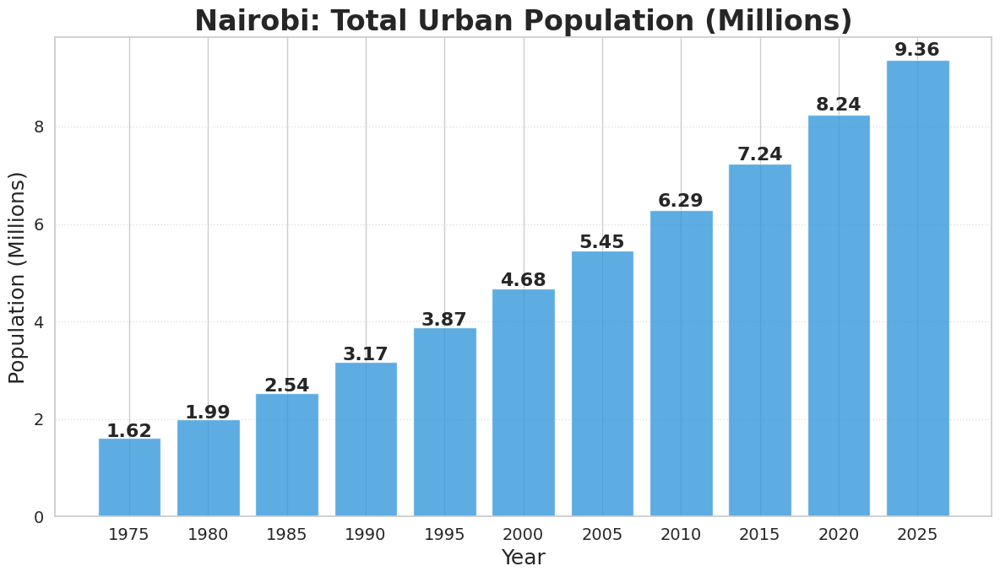

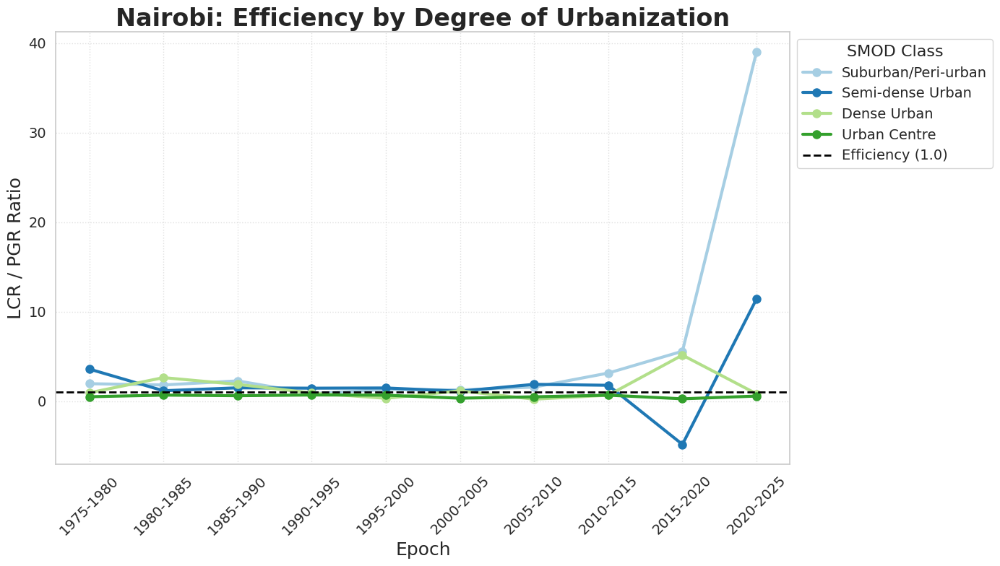

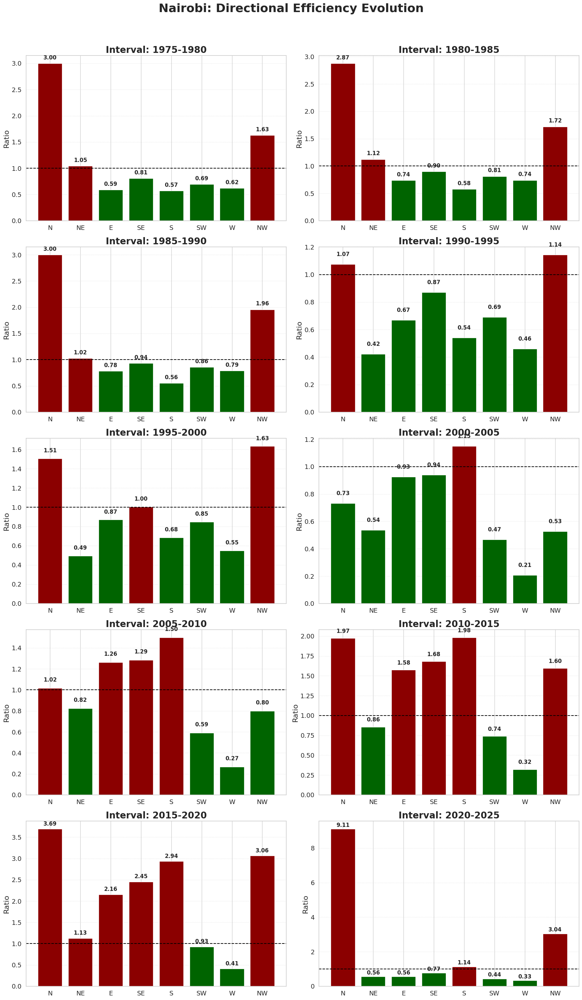

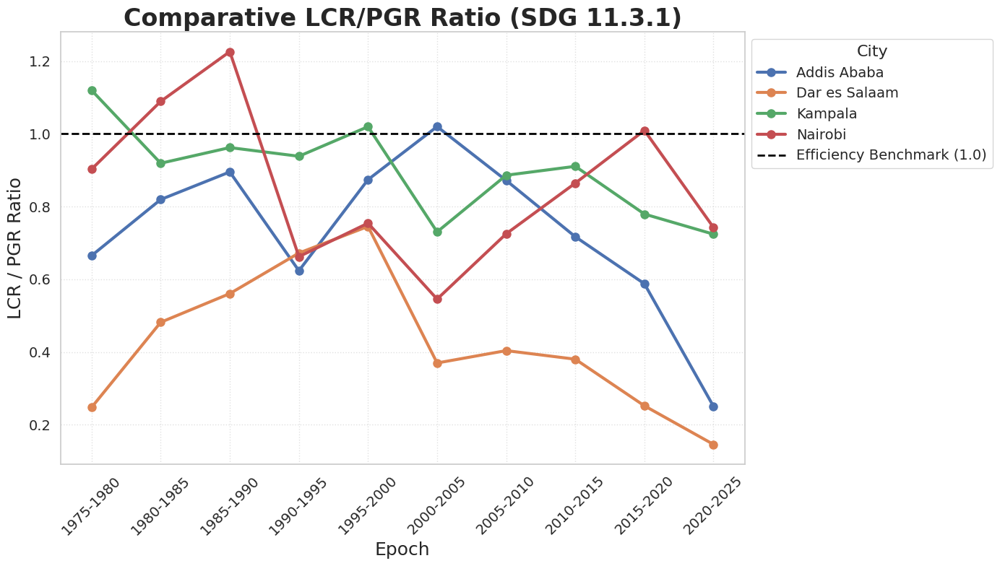


All legible analyses re-run and exports verified in Drive.


In [12]:
# Re-triggering the unified execution with improved legibility and verified exports

plt.close('all')

# 2. Update stats and pivot tables
results_df = pd.DataFrame(all_city_smod_raw).pivot_table(
    index=['City', 'year'], columns='smod_class', values='built_up_area_km2', fill_value=0
).reset_index()
results_df.rename(columns={'year': 'Year', 21: 'Suburban/Peri-urban', 22: 'Semi-dense Urban', 23: 'Dense Urban', 30: 'Urban Centre'}, inplace=True)

df_city_averages = pd.DataFrame(city_averages)
df_all_smod = pd.concat(all_cities_smod_rates, ignore_index=True)
df_all_smod['Degree of Urbanization'] = df_all_smod['smod_class'].map(SMOD_LABELS)
smod_efficiency_table = df_all_smod.groupby(['city', 'Degree of Urbanization'])['LCRPGR_Ratio'].mean().unstack()

# 3. Generate Legible Comparative Plots
print("Generating Legible Comparative Plots and Exporting to Drive...")
plot_urban_expansion_trend(results_df)
plot_urbanization_degree_2025(results_df)
plot_avg_growth_rates(df_city_averages)
plot_avg_efficiency_ratio(df_city_averages)
plot_efficiency_by_smod(smod_efficiency_table)

# 4. Generate Legible City-Specific Folders
for city_name, data in cities_data.items():
    print(f"\nProcessing legible exports for {city_name}...")
    city_output_dir = os.path.join(BASE_EXPORT_PATH, city_name.replace(' ', '_'))
    os.makedirs(city_output_dir, exist_ok=True)

    # Trends
    df_city_total = pd.DataFrame(all_city_smod_raw)
    df_city_total = df_city_total[df_city_total['City'] == city_name].groupby('year')[['built_up_area_km2', 'total_population']].sum().reset_index()
    generate_growth_trend_charts(city_name, df_city_total, city_output_dir)

    # SMOD Line Chart
    df_city_smod_rates = pd.concat([df for df in all_cities_smod_rates if df['city'].iloc[0] == city_name])
    generate_smod_ratio_chart(city_name, df_city_smod_rates, city_output_dir)

    # Directional Subplots
    if city_name in city_sectoral_rates:
        generate_all_intervals_subplot(city_name, city_sectoral_rates[city_name], city_output_dir)

# 5. Final Comparative Ratio Plot
df_all_cities_rates = pd.concat(all_cities_aggregate_rates, ignore_index=True)
generate_comparative_ratio_chart(df_all_cities_rates, BASE_EXPORT_PATH)

print("\nAll legible analyses re-run and exports verified in Drive.")

**Cell purpose.** Combine city-level aggregate rates into a comparison table and chart-ready structure.

The original code and saved output are retained unchanged.

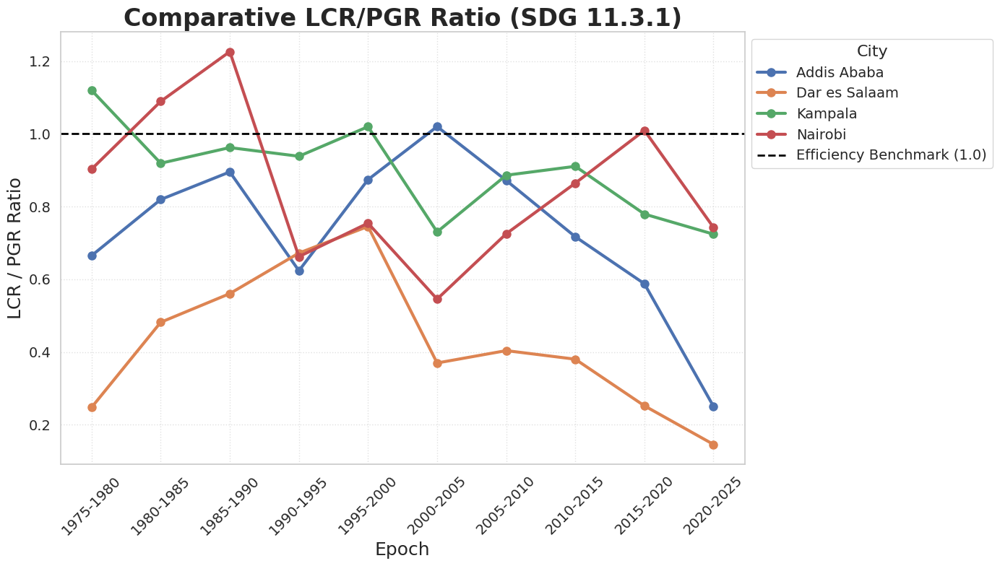

Summary of 50-year Average Efficiency (1975-2025):


,City,Average_LCRPGR_Ratio_1975_2025
1,Dar es Salaam,0.426011
0,Addis Ababa,0.732389
3,Nairobi,0.852126
2,Kampala,0.898897


In [13]:
# Combine aggregate rates for all cities into one DataFrame for comparison
df_all_cities_rates = pd.concat(all_cities_aggregate_rates, ignore_index=True)

# Generate the comparative ratio chart using the existing plotting function
generate_comparative_ratio_chart(df_all_cities_rates, BASE_EXPORT_PATH)

# Display the final summary table for quick reference
print("Summary of 50-year Average Efficiency (1975-2025):")
display(df_city_averages[['City', 'Average_LCRPGR_Ratio_1975_2025']].sort_values(by='Average_LCRPGR_Ratio_1975_2025'))

**Cell purpose.** Generate the cross-city comparative visualization from the combined rate table.

The original code and saved output are retained unchanged.

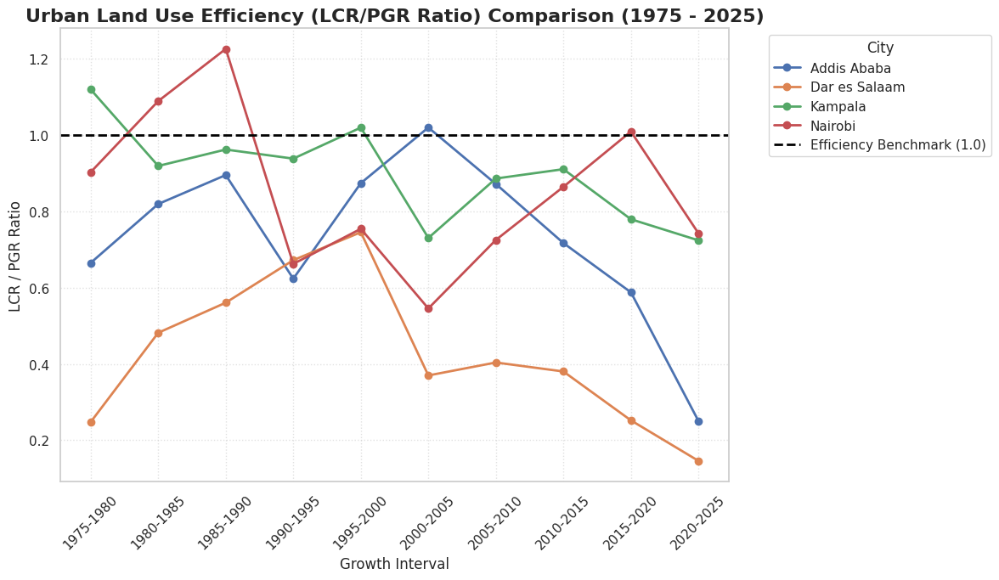

In [14]:
import matplotlib.pyplot as plt
import os

# Filter for total aggregate rates per city
df_all_cities = pd.concat(all_cities_aggregate_rates, ignore_index=True)

plt.figure(figsize=(12, 7))
for city in df_all_cities['city'].unique():
    subset = df_all_cities[df_all_cities['city'] == city]
    plt.plot(subset['interval'], subset['LCRPGR_Ratio'], marker='o', label=city, linewidth=2)

# Add the 1.0 Efficiency Benchmark
plt.axhline(1.0, color='black', linestyle='--', linewidth=2, label='Efficiency Benchmark (1.0)')

plt.title('Urban Land Use Efficiency (LCR/PGR Ratio) Comparison (1975 - 2025)', fontsize=16, fontweight='bold')
plt.xlabel('Growth Interval', fontsize=12)
plt.ylabel('LCR / PGR Ratio', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(title='City', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

# Export to Drive
plt.savefig(os.path.join(BASE_EXPORT_PATH, 'All_Cities_LCRPGR_Trend_Comparison.png'))
plt.show()

**Cell purpose.** Calculate and display decadal efficiency summaries from the interval-level results.

The original code and saved output are retained unchanged.

Decadal Average Urban Land Use Efficiency (LCR/PGR Ratio):


Decade,1980s (Incl. 75),1990s,2000s,2010s,2020s
city,,,,,
Addis Ababa,0.742214,0.759327,0.946880,0.794380,0.419142
Dar es Salaam,0.364839,0.616402,0.557612,0.392101,0.199098
Kampala,1.019316,0.950193,0.874944,0.898348,0.751683
Nairobi,0.995989,0.944059,0.649887,0.794728,0.875968


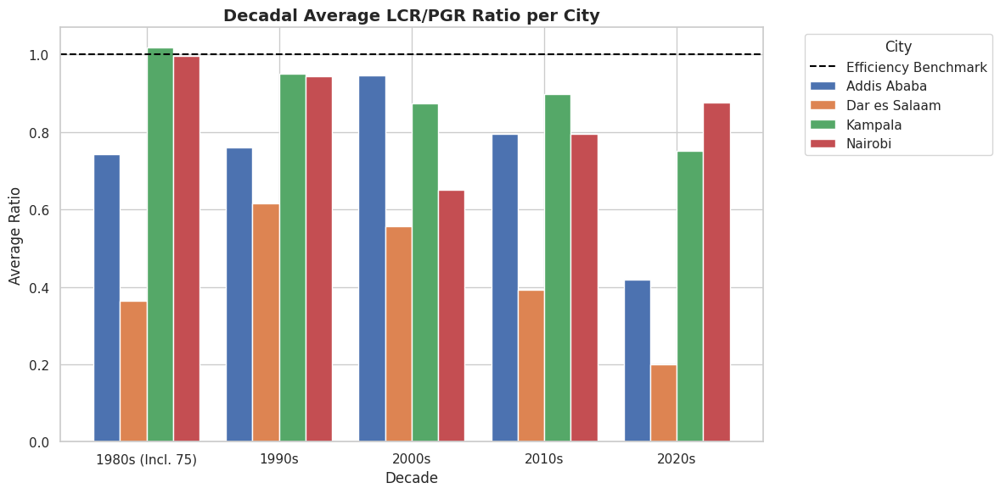

In [15]:
def get_decade(year):
    if 1975 <= year <= 1985: return '1980s (Incl. 75)'
    if 1986 <= year <= 1995: return '1990s'
    if 1996 <= year <= 2005: return '2000s'
    if 2006 <= year <= 2015: return '2010s'
    if 2016 <= year <= 2025: return '2020s'
    return 'Other'

# Create a copy for decade analysis
df_decade = df_all_cities.copy()
df_decade['Decade'] = df_decade['year'].apply(get_decade)

# Group and calculate mean
decadal_efficiency = df_decade.groupby(['city', 'Decade'])['LCRPGR_Ratio'].mean().unstack()

print("Decadal Average Urban Land Use Efficiency (LCR/PGR Ratio):")
display(decadal_efficiency)

# Quick Visualization
decadal_efficiency.T.plot(kind='bar', figsize=(12, 6), width=0.8)
plt.axhline(1.0, color='black', linestyle='--', label='Efficiency Benchmark')
plt.title('Decadal Average LCR/PGR Ratio per City', fontsize=14, fontweight='bold')
plt.ylabel('Average Ratio')
plt.legend(title='City', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()

# Export to Drive
plt.savefig(os.path.join(BASE_EXPORT_PATH, 'Decadal_Average_LCRPGR_Ratio_Bar.png'))
plt.show()

**Cell purpose.** Calculate LCR–PGR correlations and associated robustness diagnostics for the observed period.

The original code and saved output are retained unchanged.

Correlation Analysis: Land Consumption Rate (LCR) vs Population Growth Rate (PGR)


,City,Pearson Correlation (LCR vs PGR),P-Value
0,Addis Ababa,0.117,0.7481
1,Dar es Salaam,-0.032,0.9297
2,Kampala,0.608,0.0620
3,Nairobi,0.862,0.0013


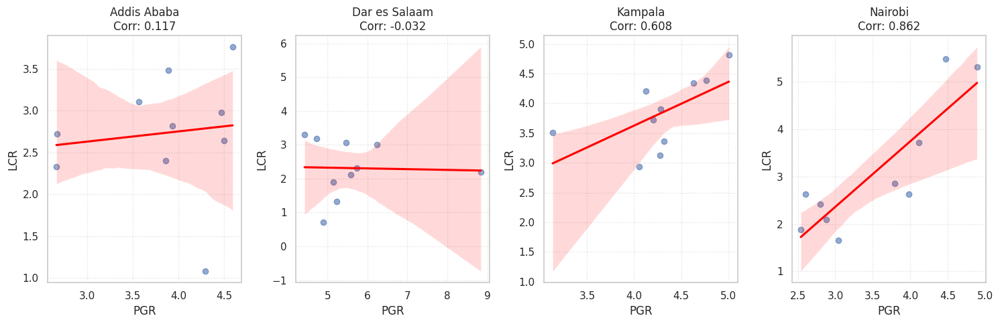

In [16]:
import scipy.stats as stats

correlation_results = []

for city in df_all_cities['city'].unique():
    subset = df_all_cities[df_all_cities['city'] == city]
    # Calculate Pearson correlation
    corr, p_value = stats.pearsonr(subset['LCR'], subset['PGR'])
    correlation_results.append({
        'City': city,
        'Pearson Correlation (LCR vs PGR)': round(corr, 3),
        'P-Value': round(p_value, 4)
    })

df_corr = pd.DataFrame(correlation_results)
print("Correlation Analysis: Land Consumption Rate (LCR) vs Population Growth Rate (PGR)")
display(df_corr)

# Visualize with scatter plots
plt.figure(figsize=(15, 5))
for i, city in enumerate(df_all_cities['city'].unique()):
    plt.subplot(1, 4, i+1)
    subset = df_all_cities[df_all_cities['city'] == city]
    sns.regplot(data=subset, x='PGR', y='LCR', scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
    plt.title(f"{city}\nCorr: {df_corr.loc[df_corr['City']==city, 'Pearson Correlation (LCR vs PGR)'].values[0]}")
    plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
# Export to Drive
plt.savefig(os.path.join(BASE_EXPORT_PATH, 'LCR_PGR_Correlation_Scatterplots.png'))
plt.show()

Summary Report: Urban Expansion Analysis (1975-2025)
1. Addis Ababa, Ethiopia
Efficiency Profile: Averaged a 50-year LCR/PGR ratio of 0.73, indicating consistent densification.
Growth Dynamics: Urban expansion was strongest in the 2000s, but the 2020-2025 period shows a significant shift toward very high efficiency (0.42 ratio), suggesting a recent policy or physical shift toward vertical/infill growth.
Land Class: Dominant growth in 'Urban Centre' and 'Dense Urban' categories.
2. Dar es Salaam, Tanzania
Efficiency Profile: The most efficient city in the study with a long-term ratio of 0.43.
Growth Dynamics: Population growth has vastly outpaced land consumption in every decade. It represents a model of high-density, population-led urbanization.
Correlation: Shows a very low correlation (-0.03) between LCR and PGR, meaning land expansion is not strictly tied to population surges, but rather steady densification.
3. Kampala, Uganda
Efficiency Profile: Closest to the efficiency benchmark with a ratio of 0.90.
Growth Dynamics: Experienced periods of 'sprawl' (ratio > 1.0) in the early 1980s, but has since stabilized. It maintains the highest average Land Consumption Rate (3.83%) among the four cities.
Directional Trends: Shows significant expansion pressure across multiple sectors, requiring careful land-use management to maintain its current efficiency level.
4. Nairobi, Kenya
Efficiency Profile: Highly coupled growth with an average ratio of 0.85.
Growth Dynamics: Exhibits the strongest correlation (0.86) between population growth and land expansion. When the population grows, the city footprint expands predictably.
Urbanization Degree: Has a diverse mix of 'Suburban' and 'Urban Centre' growth. Recent epochs (2015-2020) touched the 1.0 benchmark, indicating a brief period where land consumption matched population growth exactly.

**Cell purpose.** Display the final summary metrics table used to inspect the report-level outputs.

The original code and saved output are retained unchanged.

In [17]:
# Display the summary metrics table for the report
summary_report_df = df_city_averages[['City', 'Average_LCR_1975_2025', 'Average_PGR_1975_2025', 'Average_LCRPGR_Ratio_1975_2025']].copy()
summary_report_df.columns = ['City', 'Avg LCR (%)', 'Avg PGR (%)', 'Avg Efficiency (Ratio)']
display(HTML('<h3>Key Metrics Summary (1975-2025)</h3>'))
display(summary_report_df.sort_values(by='Avg Efficiency (Ratio)'))

,City,Avg LCR (%),Avg PGR (%),Avg Efficiency (Ratio)
1,Dar es Salaam,2.311504,5.629235,0.426011
0,Addis Ababa,2.732593,3.844284,0.732389
3,Nairobi,3.069127,3.510304,0.852126
2,Kampala,3.830298,4.279483,0.898897


## 4. Sensitivity-analysis configuration and scenarios

These cells evaluate spatial extents, settlement masks, baseline verification, ranking stability, interval-level rates, and sensitivity visualizations.

### Sensitivity analysis - Setup and Configuration

**Cell purpose.** Define sensitivity-analysis paths, thresholds, class masks, and baseline configuration values.

The original code and saved output are retained unchanged.

In [18]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configure sensitivity parameters
SENS_CONFIG = {
    'output_dir': os.path.join(BASE_EXPORT_PATH, 'Sensitivity/'),
    'obs_end': 2020,
    'dpi': 300
}

os.makedirs(SENS_CONFIG['output_dir'], exist_ok=True)
print(f"Sensitivity output directory verified: {SENS_CONFIG['output_dir']}")

Sensitivity output directory verified: /content/drive/MyDrive/Urban_Expansion_Analysis/Sensitivity/


### Sensitivity analysis - Calculations and Export

**Cell purpose.** Separate observed and projected periods and export the corresponding sensitivity summaries.

The original code and saved output are retained unchanged.

In [19]:
# Separate data into observed (<= 2020) and projected (2025) periods
df_all_cities_rates['year'] = df_all_cities_rates['year'].astype(int)

df_observed = df_all_cities_rates[df_all_cities_rates['year'] <= SENS_CONFIG['obs_end']]
df_projected = df_all_cities_rates[df_all_cities_rates['year'] == 2025]

# Save data tables to CSV
obs_csv_path = os.path.join(SENS_CONFIG['output_dir'], 'observed_rates.csv')
proj_csv_path = os.path.join(SENS_CONFIG['output_dir'], 'projected_rates.csv')

df_observed.to_csv(obs_csv_path, index=False)
df_projected.to_csv(proj_csv_path, index=False)

# Calculate mean LCR, PGR, and LCRPGR_Ratio for observed and projected epochs
summary_obs = df_observed.groupby('city')[['LCR', 'PGR', 'LCRPGR_Ratio']].mean().reset_index()
summary_proj = df_projected.groupby('city')[['LCR', 'PGR', 'LCRPGR_Ratio']].mean().reset_index()

summary_obs.to_csv(os.path.join(SENS_CONFIG['output_dir'], 'observed_summary_means.csv'), index=False)
summary_proj.to_csv(os.path.join(SENS_CONFIG['output_dir'], 'projected_summary_means.csv'), index=False)

print("Observed metrics summary:")
display(summary_obs)
print("\nProjected (2025) metrics summary:")
display(summary_proj)

Observed metrics summary:


,city,LCR,PGR,LCRPGR_Ratio
0,Addis Ababa,2.916605,3.794051,0.785925
1,Dar es Salaam,2.488815,5.710154,0.457119
2,Kampala,3.929796,4.304599,0.918326
3,Nairobi,3.200607,3.618148,0.864303



Projected (2025) metrics summary:


,city,LCR,PGR,LCRPGR_Ratio
0,Addis Ababa,1.076486,4.296383,0.250556
1,Dar es Salaam,0.715709,4.900963,0.146034
2,Kampala,2.934823,4.053445,0.724032
3,Nairobi,1.885811,2.539709,0.742530


### Sensitivity analysis - Visualization

**Cell purpose.** Plot observed-versus-projected efficiency comparisons for the sensitivity analysis.

The original code and saved output are retained unchanged.

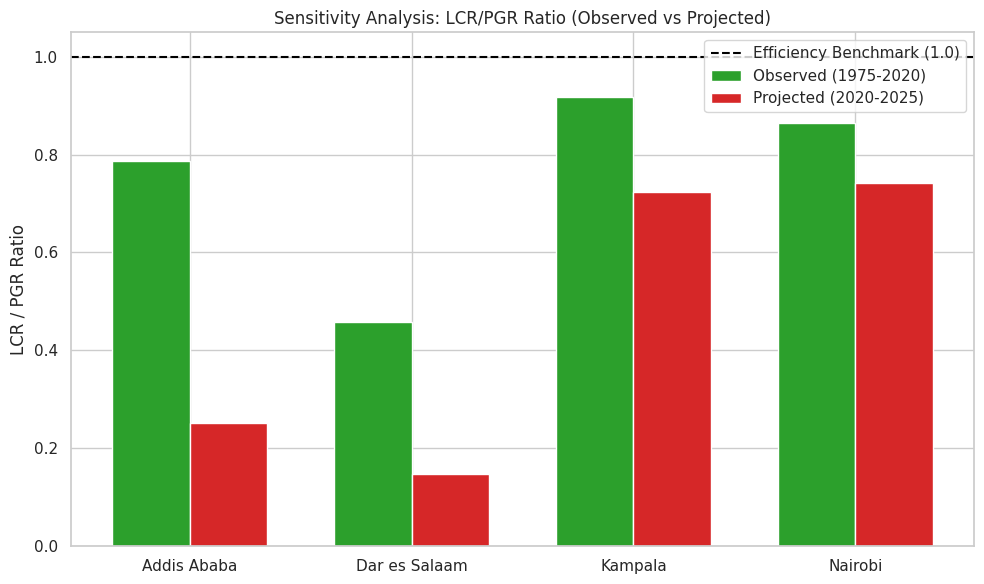

In [20]:
# Plot comparison of Observed vs Projected LCR/PGR Ratio
cities = summary_obs['city'].unique()
x = np.arange(len(cities))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

rects1 = ax.bar(x - width/2, summary_obs['LCRPGR_Ratio'], width, label=f'Observed (1975-{SENS_CONFIG["obs_end"]})', color='#2ca02c')
rects2 = ax.bar(x + width/2, summary_proj['LCRPGR_Ratio'], width, label='Projected (2020-2025)', color='#d62728')

ax.set_ylabel('LCR / PGR Ratio')
ax.set_title('Sensitivity Analysis: LCR/PGR Ratio (Observed vs Projected)')
ax.set_xticks(x)
ax.set_xticklabels(cities)
ax.axhline(1.0, color='black', linestyle='--', linewidth=1.5, label='Efficiency Benchmark (1.0)')
ax.legend()

plt.tight_layout()
save_path = os.path.join(SENS_CONFIG['output_dir'], 'observed_vs_projected_comparison.png')
plt.savefig(save_path, dpi=SENS_CONFIG['dpi'])
plt.show()

### Sensitivity analysis - Setup and Configuration Dictionary

**Cell purpose.** Initialize the sensitivity-configuration dictionary used by the scenario calculations.

The original code and saved output are retained unchanged.

In [21]:
import os
import pandas as pd
import numpy as np
import ee

SENS_CONFIG = {
    'output_dir': os.path.join(BASE_EXPORT_PATH, 'Sensitivity/'),
    'COMMON_RADIUS_M': 40000,
    'ADMIN_BOUNDARIES': {city: None for city in cities_data.keys()},
    'FOOTPRINT_CLASSES': [23, 30],
    'FOOTPRINT_YEAR': 2020,
    'FIXED_MASK_YEARS': [2020, 1975],
    'OBS_END': 2020,
    'RANK_TOL': 0.05,
    'PGR_MIN': 0.1,
    'N_MC': 1000,
    'BOOT': 5000,
    'SEED': 42
}

os.makedirs(SENS_CONFIG['output_dir'], exist_ok=True)
print(f"Sensitivity configuration initialized. Output directory: {SENS_CONFIG['output_dir']}")

Sensitivity configuration initialized. Output directory: /content/drive/MyDrive/Urban_Expansion_Analysis/Sensitivity/


### Sensitivity analysis - Extraction Functions and Scenario Runner

**Cell purpose.** Define reusable total-extraction and scenario-running functions for alternative masks and extents.

The original code and saved output are retained unchanged.

In [22]:
def extract_totals(year, roi, smod_year=None, mask_classes=None, footprint_img=None):
    """Extracts total built area and population using a single getInfo call."""
    s_year = smod_year if smod_year is not None else year
    classes = mask_classes if mask_classes is not None else TARGET_SMOD_CLASSES

    built_img = ee.Image(BUILT_ASSET + str(year)).select('built_surface')
    pop_img = ee.Image(POP_ASSET + str(year)).select('population_count')

    if footprint_img is not None:
        # Mask by provided footprint
        masked_built = built_img.updateMask(footprint_img)
        masked_pop = pop_img.updateMask(footprint_img)
    else:
        smod_img = ee.Image(SMOD_ASSET + str(s_year)).select('smod_code')
        class_mask = smod_img.remap(classes, [1] * len(classes), 0).eq(1)
        masked_built = built_img.updateMask(class_mask)
        masked_pop = pop_img.updateMask(class_mask)

    # Run reductions
    built_sum = masked_built.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=roi,
        scale=scale,
        maxPixels=1e10,
        tileScale=4
    )

    pop_sum = masked_pop.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=roi,
        scale=scale,
        maxPixels=1e10,
        tileScale=4
    )

    # Evaluate together with a single getInfo call
    combined_stats = ee.List([built_sum.get('built_surface'), pop_sum.get('population_count')]).getInfo()

    built_val = (combined_stats[0] if combined_stats[0] is not None else 0) / 1e6
    pop_val = combined_stats[1] if combined_stats[1] is not None else 0

    return built_val, pop_val

def run_scenario(label, roi_by_city, smod_year=None, mask_classes=None, footprint_by_city=None):
    """Runs or loads a scenario using caching."""
    cache_path = os.path.join(SENS_CONFIG['output_dir'], f"scenario_{label}.csv")
    if os.path.exists(cache_path):
        print(f"Loading scenario '{label}' from cache...")
        return pd.read_csv(cache_path)

    print(f"Running scenario '{label}' via Earth Engine...")
    results = []
    for city_name, roi in roi_by_city.items():
        print(f"  - Processing {city_name}...")
        footprint_img = footprint_by_city.get(city_name) if footprint_by_city is not None else None
        for year in years:
            built_area, pop = extract_totals(
                year=year,
                roi=roi,
                smod_year=smod_year,
                mask_classes=mask_classes,
                footprint_img=footprint_img
            )
            results.append({
                'scenario': label,
                'city': city_name,
                'year': year,
                'built_up_area_km2': built_area,
                'total_population': pop
            })

    df = pd.DataFrame(results)
    df.to_csv(cache_path, index=False)
    return df

### Sensitivity analysis - Baseline Verification

**Cell purpose.** Construct baseline regions, extract baseline totals, and verify consistency with the primary analysis.

The original code and saved output are retained unchanged.

In [23]:
# 1. Construct original ROIs
baseline_rois = {}
for city_name, data in cities_data.items():
    center = ee.Geometry.Point(data['coords'])
    baseline_rois[city_name] = center.buffer(data['radius_m'], maxError=1)

# 2. Run Baseline Scenario
df_baseline = run_scenario('baseline', baseline_rois, smod_year=None, mask_classes=TARGET_SMOD_CLASSES)

# 3. Sum up original raw records to compare
df_raw_smod = pd.DataFrame(all_city_smod_raw)
df_raw_totals = df_raw_smod.groupby(['City', 'year'])[['built_up_area_km2', 'total_population']].sum().reset_index()

# Sort both for exact comparison
df_baseline_sorted = df_baseline.sort_values(by=['city', 'year']).reset_index(drop=True)
df_raw_sorted = df_raw_totals.sort_values(by=['City', 'year']).reset_index(drop=True)

# Compare area and population arrays
area_diff = np.abs(df_baseline_sorted['built_up_area_km2'] - df_raw_sorted['built_up_area_km2'])
pop_diff = np.abs(df_baseline_sorted['total_population'] - df_raw_sorted['total_population'])

# Avoid zero division
rel_area_diff = np.where(df_raw_sorted['built_up_area_km2'] > 0, area_diff / df_raw_sorted['built_up_area_km2'], 0)
rel_pop_diff = np.where(df_raw_sorted['total_population'] > 0, pop_diff / df_raw_sorted['total_population'], 0)

max_rel_diff = max(rel_area_diff.max(), rel_pop_diff.max())

print(f"Maximum relative discrepancy: {max_rel_diff:.4e}")
if max_rel_diff <= 1e-6:
    print("VERIFICATION STATUS: PASS")
else:
    print("VERIFICATION STATUS: FAIL")

Loading scenario 'baseline' from cache...
Maximum relative discrepancy: 5.9700e-16
VERIFICATION STATUS: PASS


### Sensitivity Analysis 1: Spatial Extents and City Boundaries
In this section, we test the sensitivity of our findings to alternative boundary definitions. We compare:
1. **original**: The baseline city-specific radius buffers.
2. **common**: A standardized circular buffer with a radius of $40\text{ km}$ ($40,000\text{ m}$).
3. **admin**: Administrative boundaries (skipped/marked NaN here as they are initialized to `None`).
4. **footprint**: A fixed spatial mask using the SMOD classes `[23, 30]` from the year `2020`, locked for all years to isolate changes purely occurring within high-density footprints.

**Cell purpose.** Run alternative spatial-extent, common-extent, footprint, and legacy scenario calculations.

The original code and saved output are retained unchanged.

In [24]:
import scipy.stats as stats
import seaborn as sns

# 1. Prepare alternative ROIs and Footprint Masks
common_rois = {}
for city_name, data in cities_data.items():
    center = ee.Geometry.Point(data['coords'])
    common_rois[city_name] = center.buffer(SENS_CONFIG['COMMON_RADIUS_M'], maxError=1)

footprint_masks = {}
for city_name, data in cities_data.items():
    center = ee.Geometry.Point(data['coords'])
    roi_orig = center.buffer(data['radius_m'], maxError=1)

    smod_img = ee.Image(SMOD_ASSET + str(SENS_CONFIG['FOOTPRINT_YEAR'])).select('smod_code')
    classes = SENS_CONFIG['FOOTPRINT_CLASSES']
    class_mask = smod_img.remap(classes, [1] * len(classes), 0).eq(1)
    footprint_masks[city_name] = class_mask.clip(roi_orig)

# 2. Run scenarios
print("Extracting original scenario...")
df_sens_orig = run_scenario('original', baseline_rois, smod_year=None, mask_classes=TARGET_SMOD_CLASSES)

print("Extracting common scenario...")
df_sens_comm = run_scenario('common', common_rois, smod_year=None, mask_classes=TARGET_SMOD_CLASSES)

print("Extracting footprint scenario...")
df_sens_foot = run_scenario('footprint', baseline_rois, footprint_by_city=footprint_masks)

# Combine scenario datasets
df_sens_orig['extent'] = 'original'
df_sens_comm['extent'] = 'common'
df_sens_foot['extent'] = 'footprint'

all_scenarios = [df_sens_orig, df_sens_comm, df_sens_foot]

# Handle admin scenario placeholder
admin_results = []
for city_name in cities_data.keys():
    for year in years:
        admin_results.append({
            'scenario': 'admin',
            'city': city_name,
            'year': year,
            'built_up_area_km2': np.nan,
            'total_population': np.nan,
            'extent': 'admin'
        })
df_sens_admin = pd.DataFrame(admin_results)
all_scenarios.append(df_sens_admin)

df_all_extents = pd.concat(all_scenarios, ignore_index=True)
print("Boundary extraction complete.")

Extracting original scenario...
Loading scenario 'original' from cache...
Extracting common scenario...
Loading scenario 'common' from cache...
Extracting footprint scenario...
Loading scenario 'footprint' from cache...
Boundary extraction complete.


**Cell purpose.** Calculate interval-level LCR, PGR, and efficiency values for the extent scenarios.

The original code and saved output are retained unchanged.

In [25]:
# 3. Process growth rates and ratios per interval
processed_intervals = []

for (extent, city), group in df_all_extents.groupby(['extent', 'city']):
    if group['built_up_area_km2'].isna().all():
        # Create empty placeholder rows representing intervals for 'admin' as a DataFrame
        intervals_list = [f"{years[i]}-{years[i+1]}" for i in range(len(years)-1)]
        admin_rows = []
        for val in intervals_list:
            admin_rows.append({
                'extent': extent,
                'city': city,
                'interval': val,
                'LCR': np.nan,
                'PGR': np.nan,
                'LCRPGR_Ratio': np.nan,
                'year': int(val.split('-')[1])
            })
        processed_intervals.append(pd.DataFrame(admin_rows))
    else:
        rates = calculate_rates_by_group(group.copy(), group_col=None)
        if not rates.empty:
            rates['extent'] = extent
            rates['city'] = city
            processed_intervals.append(rates)

df_extent_intervals = pd.concat(processed_intervals, ignore_index=True)
df_extent_intervals['year'] = df_extent_intervals['year'].astype(int)

# Filter for observed epochs only (<= 2020)
df_obs_intervals = df_extent_intervals[df_extent_intervals['year'] <= SENS_CONFIG['OBS_END']]

# Save interval-level table to CSV
interval_save_path = os.path.join(SENS_CONFIG['output_dir'], 'sensitivity_extents_intervals.csv')
df_extent_intervals.to_csv(interval_save_path, index=False)
print(f"Saved interval table to {interval_save_path}")

Saved interval table to /content/drive/MyDrive/Urban_Expansion_Analysis/Sensitivity/sensitivity_extents_intervals.csv


**Cell purpose.** Compile extent-sensitivity summaries, rank changes, and correlation comparisons.

The original code and saved output are retained unchanged.

In [26]:
# 4. Build spatial boundary summary table
summary_records = []

for (extent, city), group in df_all_extents.groupby(['extent', 'city']):
    if group['built_up_area_km2'].isna().all() or extent == 'admin':
        summary_records.append({
            'extent': extent,
            'city': city,
            'mean_LCRPGR_Ratio': np.nan,
            'mean_LCR': np.nan,
            'mean_PGR': np.nan,
            'cumulative_LCR': np.nan,
            'cumulative_PGR': np.nan
        })
        continue

    # Slice interval rates up to OBS_END
    sub_rates = df_obs_intervals[(df_obs_intervals['extent'] == extent) & (df_obs_intervals['city'] == city)]

    mean_ratio = sub_rates['LCRPGR_Ratio'].mean()
    mean_lcr = sub_rates['LCR'].mean()
    mean_pgr = sub_rates['PGR'].mean()

    # Calculate cumulative metrics (1975 to 2020)
    g_sorted = group[group['year'] <= SENS_CONFIG['OBS_END']].sort_values('year')
    a_start, a_end = g_sorted['built_up_area_km2'].iloc[0], g_sorted['built_up_area_km2'].iloc[-1]
    p_start, p_end = g_sorted['total_population'].iloc[0], g_sorted['total_population'].iloc[-1]

    dt_cum = SENS_CONFIG['OBS_END'] - 1975
    cum_lcr = (np.log(a_end) - np.log(a_start)) / dt_cum * 100 if a_start > 0 else np.nan
    cum_pgr = (np.log(p_end) - np.log(p_start)) / dt_cum * 100 if p_start > 0 else np.nan

    summary_records.append({
        'extent': extent,
        'city': city,
        'mean_LCRPGR_Ratio': mean_ratio,
        'mean_LCR': mean_lcr,
        'mean_PGR': mean_pgr,
        'cumulative_LCR': cum_lcr,
        'cumulative_PGR': cum_pgr
    })

df_sens_summary = pd.DataFrame(summary_records)

# 5. Compute Rankings within each extent (1 = most efficient, lowest ratio)
for extent in df_sens_summary['extent'].unique():
    subset = df_sens_summary[df_sens_summary['extent'] == extent]
    if subset['mean_LCRPGR_Ratio'].isna().all():
        df_sens_summary.loc[df_sens_summary['extent'] == extent, 'rank'] = np.nan
    else:
        df_sens_summary.loc[df_sens_summary['extent'] == extent, 'rank'] = subset['mean_LCRPGR_Ratio'].rank(method='min')

# Extract Rankings for correlation metrics
orig_ranks = df_sens_summary[df_sens_summary['extent'] == 'original'].set_index('city')['rank']

correlation_records = []
for ext in ['original', 'common', 'footprint', 'admin']:
    sub = df_sens_summary[df_sens_summary['extent'] == ext].set_index('city')

    if ext == 'admin' or sub['mean_LCRPGR_Ratio'].isna().all():
        correlation_records.append({
            'extent': ext,
            'spearman_rho': np.nan,
            'kendall_tau': np.nan,
            'robust': 'NaN'
        })
        continue

    # Evaluate ranking correlation
    rho, _ = stats.spearmanr(orig_ranks, sub['rank'])
    tau, _ = stats.kendalltau(orig_ranks, sub['rank'])

    # Check robustness conditions
    is_identical = orig_ranks.equals(sub['rank'])
    is_robust = is_identical

    if not is_identical:
        # Check if swaps occurred only between cities within the RANK_TOL threshold
        swaps_tolerated = True
        for city_a in orig_ranks.index:
            for city_b in orig_ranks.index:
                orig_rank_diff = orig_ranks[city_a] - orig_ranks[city_b]
                new_rank_diff = sub.loc[city_a, 'rank'] - sub.loc[city_b, 'rank']
                # If the order swapped
                if np.sign(orig_rank_diff) != np.sign(new_rank_diff) and orig_rank_diff != 0:
                    val_a = df_sens_summary[(df_sens_summary['extent'] == 'original') & (df_sens_summary['city'] == city_a)]['mean_LCRPGR_Ratio'].values[0]
                    val_b = df_sens_summary[(df_sens_summary['extent'] == 'original') & (df_sens_summary['city'] == city_b)]['mean_LCRPGR_Ratio'].values[0]
                    if abs(val_a - val_b) >= SENS_CONFIG['RANK_TOL']:
                        swaps_tolerated = False
                        break
            if not swaps_tolerated:
                break
        is_robust = swaps_tolerated

    correlation_records.append({
        'extent': ext,
        'spearman_rho': round(rho, 4) if not np.isnan(rho) else 1.0,
        'kendall_tau': round(tau, 4) if not np.isnan(tau) else 1.0,
        'robust': 'YES' if is_robust else 'NO'
    })

df_corr_summary = pd.DataFrame(correlation_records)

# Save summary and correlation tables
summary_save_path = os.path.join(SENS_CONFIG['output_dir'], 'sensitivity_extents_summary.csv')
df_sens_summary.to_csv(summary_save_path, index=False)
df_corr_summary.to_csv(os.path.join(SENS_CONFIG['output_dir'], 'sensitivity_extents_correlations.csv'), index=False)

print("Summary evaluation records:")
display(df_sens_summary)
print("Ranking correlation robustness summary:")
display(df_corr_summary)

Summary evaluation records:


,extent,city,mean_LCRPGR_Ratio,mean_LCR,mean_PGR,cumulative_LCR,cumulative_PGR,rank
0,admin,Addis Ababa,NaN,NaN,NaN,NaN,NaN,NaN
1,admin,Dar es Salaam,NaN,NaN,NaN,NaN,NaN,NaN
2,admin,Kampala,NaN,NaN,NaN,NaN,NaN,NaN
3,admin,Nairobi,NaN,NaN,NaN,NaN,NaN,NaN
4,common,Addis Ababa,0.785925,2.916605,3.794051,2.916605,3.794051,3.0
5,common,Dar es Salaam,0.453900,2.468600,5.701967,2.468600,5.701967,1.0
6,common,Kampala,0.798750,3.444231,4.347882,3.444231,4.347882,4.0
7,common,Nairobi,0.694602,2.716740,3.762872,2.716740,3.762872,2.0
8,footprint,Addis Ababa,0.716235,2.573111,3.700979,2.573111,3.700979,4.0
9,footprint,Dar es Salaam,0.373262,1.917691,5.381920,1.917691,5.381920,1.0


Ranking correlation robustness summary:


,extent,spearman_rho,kendall_tau,robust
0,original,1.0,1.0000,YES
1,common,0.8,0.6667,NO
2,footprint,0.4,0.3333,NO
3,admin,NaN,NaN,NaN


**Cell purpose.** Visualize mean efficiency-ratio differences across spatial-extent scenarios.

The original code and saved output are retained unchanged.

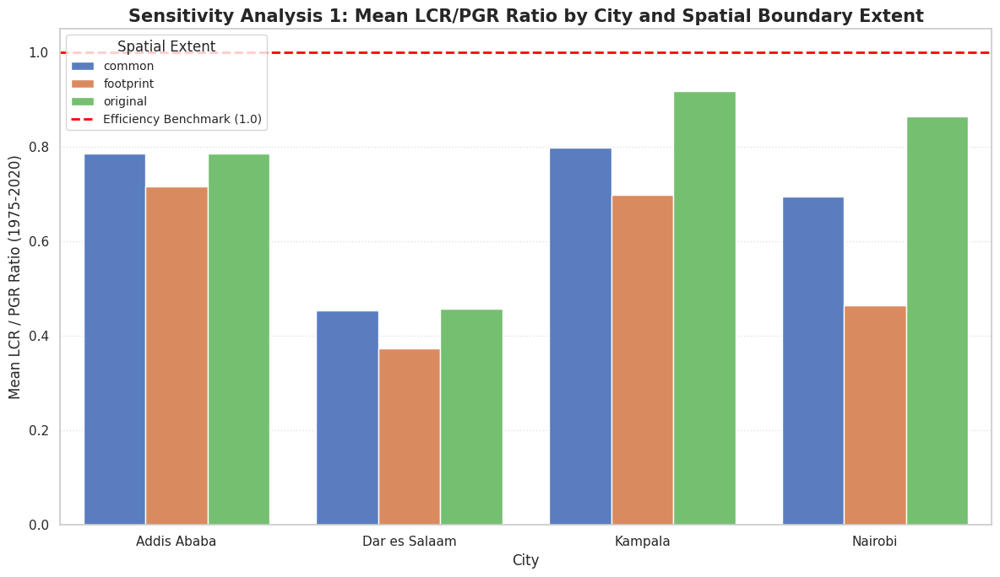

In [27]:
# 6. Grouped Bar Chart of mean LCRPGR_Ratio by City and Extent
plt.figure(figsize=(12, 7))

# Filter out admin rows representing NaN values for visual consistency
plot_data = df_sens_summary[df_sens_summary['extent'] != 'admin']

sns.barplot(
    data=plot_data,
    x='city',
    y='mean_LCRPGR_Ratio',
    hue='extent',
    palette='muted'
)

plt.axhline(1.0, color='red', linestyle='--', linewidth=2, label='Efficiency Benchmark (1.0)')
plt.title('Sensitivity Analysis 1: Mean LCR/PGR Ratio by City and Spatial Boundary Extent', fontsize=15, fontweight='bold')
plt.xlabel('City', fontsize=12)
plt.ylabel('Mean LCR / PGR Ratio (1975-2020)', fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(title='Spatial Extent', fontsize=10, loc='upper left')
plt.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
save_img_path = os.path.join(SENS_CONFIG['output_dir'], 'sensitivity_extents_ratios.png')
plt.savefig(save_img_path, dpi=300)
plt.show()
plt.close()

### Sensitivity Analysis 2: SMOD Classification Mask and Class Transitions
In this section, we test the sensitivity of LCRPGR ratios to the choice of the spatial mask. We compare:
1. **time_varying**: Baseline classification masks where the SMOD layer updates dynamically each year.
2. **fixed_2020**: The SMOD 2020 classification map serves as the spatial mask for all epochs.
3. **fixed_1975**: The SMOD 1975 classification map serves as the spatial mask for all epochs.

We also construct decadal / 5-year SMOD class-transition tables mapping urban transformations across epochs.

**Cell purpose.** Define and run alternative settlement-mask scenarios, including fixed-year and time-varying masks.

The original code and saved output are retained unchanged.

In [28]:
import os
import pandas as pd
import numpy as np
import ee

# 1. Run scenarios for fixed masks
print("Extracting fixed 2020 scenario...")
df_sens_f2020 = run_scenario('fixed_2020', baseline_rois, smod_year=2020, mask_classes=TARGET_SMOD_CLASSES)

print("Extracting fixed 1975 scenario...")
df_sens_f1975 = run_scenario('fixed_1975', baseline_rois, smod_year=1975, mask_classes=TARGET_SMOD_CLASSES)

# Baseline is equivalent to the original from boundary sensitivity
df_sens_tv = df_sens_orig.copy()
df_sens_tv['scenario'] = 'time_varying'

df_sens_f2020['scenario'] = 'fixed_2020'
df_sens_f1975['scenario'] = 'fixed_1975'

df_mask_sens = pd.concat([df_sens_tv, df_sens_f2020, df_sens_f1975], ignore_index=True)
print("Extraction of mask scenarios complete.")

Extracting fixed 2020 scenario...
Loading scenario 'fixed_2020' from cache...
Extracting fixed 1975 scenario...
Loading scenario 'fixed_1975' from cache...
Extraction of mask scenarios complete.


**Cell purpose.** Calculate interval-level rates and ratios for the settlement-mask scenarios.

The original code and saved output are retained unchanged.

In [29]:
# 2. Process growth rates and ratios per scenario
processed_mask_intervals = []
for (scenario, city), group in df_mask_sens.groupby(['scenario', 'city']):
    rates = calculate_rates_by_group(group.copy(), group_col=None)
    if not rates.empty:
        rates['scenario'] = scenario
        rates['city'] = city
        processed_mask_intervals.append(rates)

df_mask_intervals = pd.concat(processed_mask_intervals, ignore_index=True)
df_mask_intervals['year'] = df_mask_intervals['year'].astype(int)

# Pivot to calculate differences against 'time_varying' baseline
df_pivot_intervals = df_mask_intervals.pivot_table(
    index=['city', 'interval', 'year'],
    columns='scenario',
    values=['LCRPGR_Ratio', 'LCR', 'PGR']
).reset_index()

# Flatten multi-index columns
df_pivot_intervals.columns = [
    '_'.join(col).strip('_') if isinstance(col, tuple) else col
    for col in df_pivot_intervals.columns
]

# Calculate differences
df_pivot_intervals['diff_ratio_f2020_minus_tv'] = df_pivot_intervals['LCRPGR_Ratio_fixed_2020'] - df_pivot_intervals['LCRPGR_Ratio_time_varying']
df_pivot_intervals['diff_ratio_f1975_minus_tv'] = df_pivot_intervals['LCRPGR_Ratio_fixed_1975'] - df_pivot_intervals['LCRPGR_Ratio_time_varying']

# Save mask intervals table to CSV
mask_save_path = os.path.join(SENS_CONFIG['output_dir'], 'sensitivity_masks_intervals.csv')
df_pivot_intervals.to_csv(mask_save_path, index=False)
print(f"Saved mask sensitivity table to {mask_save_path}")

Saved mask sensitivity table to /content/drive/MyDrive/Urban_Expansion_Analysis/Sensitivity/sensitivity_masks_intervals.csv


**Cell purpose.** Compile settlement-mask summaries, ranking changes, and correlation comparisons.

The original code and saved output are retained unchanged.

In [30]:
# 3. Compile scenario summaries and analyze rankings
mask_summary_records = []
for (scenario, city), group in df_mask_sens.groupby(['scenario', 'city']):
    # Slice interval rates
    sub_rates = df_mask_intervals[(df_mask_intervals['scenario'] == scenario) & (df_mask_intervals['city'] == city)]

    # Split into observed and projected
    obs_rates = sub_rates[sub_rates['year'] <= SENS_CONFIG['OBS_END']]
    proj_rates = sub_rates[sub_rates['year'] == 2025]

    mask_summary_records.append({
        'scenario': scenario,
        'city': city,
        'mean_LCRPGR_Ratio_observed': obs_rates['LCRPGR_Ratio'].mean(),
        'mean_LCRPGR_Ratio_projected_2025': proj_rates['LCRPGR_Ratio'].mean() if not proj_rates.empty else np.nan
    })

df_mask_summary = pd.DataFrame(mask_summary_records)

# Compute Rankings within each scenario
for scenario in df_mask_summary['scenario'].unique():
    subset = df_mask_summary[df_mask_summary['scenario'] == scenario]
    df_mask_summary.loc[df_mask_summary['scenario'] == scenario, 'rank_observed'] = subset['mean_LCRPGR_Ratio_observed'].rank(method='min')

# Compute correlations with baseline
tv_ranks = df_mask_summary[df_mask_summary['scenario'] == 'time_varying'].set_index('city')['rank_observed']

mask_corr_records = []
for sc in ['time_varying', 'fixed_2020', 'fixed_1975']:
    sub = df_mask_summary[df_mask_summary['scenario'] == sc].set_index('city')
    rho, _ = stats.spearmanr(tv_ranks, sub['rank_observed'])
    tau, _ = stats.kendalltau(tv_ranks, sub['rank_observed'])

    is_robust = tv_ranks.equals(sub['rank_observed'])

    mask_corr_records.append({
        'scenario': sc,
        'spearman_rho': round(rho, 4) if not np.isnan(rho) else 1.0,
        'kendall_tau': round(tau, 4) if not np.isnan(tau) else 1.0,
        'robust': 'YES' if is_robust else 'NO'
    })

df_mask_corr = pd.DataFrame(mask_corr_records)

# Save summary reports
df_mask_summary.to_csv(os.path.join(SENS_CONFIG['output_dir'], 'sensitivity_masks_summary.csv'), index=False)
df_mask_corr.to_csv(os.path.join(SENS_CONFIG['output_dir'], 'sensitivity_masks_correlations.csv'), index=False)

print("Mask Sensitivity Rankings Summary:")
display(df_mask_summary)
display(df_mask_corr)

Mask Sensitivity Rankings Summary:


,scenario,city,mean_LCRPGR_Ratio_observed,mean_LCRPGR_Ratio_projected_2025,rank_observed
0,fixed_1975,Addis Ababa,0.611554,0.055619,3.0
1,fixed_1975,Dar es Salaam,0.220242,0.023544,1.0
2,fixed_1975,Kampala,0.620469,0.101186,4.0
3,fixed_1975,Nairobi,0.551313,0.336155,2.0
4,fixed_2020,Addis Ababa,0.781068,0.152221,2.0
5,fixed_2020,Dar es Salaam,0.428682,0.073543,1.0
6,fixed_2020,Kampala,0.949823,0.488742,4.0
7,fixed_2020,Nairobi,0.867459,0.652366,3.0
8,time_varying,Addis Ababa,0.785925,0.250556,2.0
9,time_varying,Dar es Salaam,0.457119,0.146034,1.0


,scenario,spearman_rho,kendall_tau,robust
0,time_varying,1.0,1.0000,YES
1,fixed_2020,1.0,1.0000,YES
2,fixed_1975,0.8,0.6667,NO


## 5. R3.4 SMOD resolution and class-transition analysis

These cells preserve the existing consolidated transition analysis and add a class-specific transition export for the original SMOD codes.

**Cell purpose.** Calculate consolidated three-group SMOD transitions using the existing notebook logic.

The original code and saved output are retained unchanged.

In [31]:
# 4. GHS-SMOD Class Transitions (Rural/Water -> Peri-urban/Semi-dense -> Dense/Centre)
# Class mappings:
# Group 1 (Water/Rural): 10, 11, 12, 13
# Group 2 (Peri-urban/Semi-dense): 21, 22
# Group 3 (Dense/Centre): 23, 30

def get_consolidated_group(smod_code):
    # Reclassification logic mapping GHS-SMOD codes to consolidated index {1, 2, 3}
    # 10 to 13 -> 1
    # 21, 22 -> 2
    # 23, 30 -> 3
    # All others default to 0
    remap_from = ee.List([10, 11, 12, 13, 21, 22, 23, 30])
    remap_to = ee.List([1, 1, 1, 1, 2, 2, 3, 3])
    return smod_code.remap(remap_from, remap_to, 0)

transition_records = []

for city_name, data in cities_data.items():
    print(f"Processing SMOD Transitions for {city_name}...")
    center = ee.Geometry.Point(data['coords'])
    roi = center.buffer(data['radius_m'], maxError=1)

    for i in range(len(years) - 1):
        t1, t2 = years[i], years[i+1]
        interval_label = f"{t1}-{t2}"

        smod_t1 = ee.Image(SMOD_ASSET + str(t1)).select('smod_code')
        smod_t2 = ee.Image(SMOD_ASSET + str(t2)).select('smod_code')

        group_t1 = get_consolidated_group(smod_t1)
        group_t2 = get_consolidated_group(smod_t2)

        # Code representation for combinations: class_t1 * 100 + class_t2
        transition_img = group_t1.multiply(100).add(group_t2).rename('smod_code').clip(roi)

        # Reduce using a grouping frequency reducer at scale 1000m
        stats = transition_img.reduceRegion(
            reducer=ee.Reducer.frequencyHistogram(),
            geometry=roi,
            scale=1000,
            maxPixels=1e10
        ).get('smod_code')

        info = ee.Dictionary(stats).getInfo() if stats is not None else {}

        # Unpack values into structured records (Area in km2)
        # Pixel count * 1,000,000 m2 / 1,000,000 = pixel count km2 at 1000m resolution scale
        for combo_str, count in info.items():
            combo_val = int(float(combo_str))
            g1 = combo_val // 100
            g2 = combo_val % 100

            if g1 in [1, 2, 3] and g2 in [1, 2, 3]:
                transition_records.append({
                    'city': city_name,
                    'interval': interval_label,
                    'from_group': g1,
                    'to_group': g2,
                    'area_km2': count
                })

df_transitions = pd.DataFrame(transition_records)

group_labels = {
    1: 'Water/Rural (10-13)',
    2: 'Peri-urban/Semi-dense (21-22)',
    3: 'Dense/Centre (23-30)'
}

df_transitions['from_label'] = df_transitions['from_group'].map(group_labels)
df_transitions['to_label'] = df_transitions['to_group'].map(group_labels)

transitions_save_path = os.path.join(SENS_CONFIG['output_dir'], 'smod_class_transitions.csv')
df_transitions.to_csv(transitions_save_path, index=False)
print(f"Saved transition matrices to {transitions_save_path}")

# Preview Addis Ababa transition summary
display(df_transitions[df_transitions['city'] == 'Addis Ababa'].head(10))

Processing SMOD Transitions for Addis Ababa...
Processing SMOD Transitions for Dar es Salaam...
Processing SMOD Transitions for Kampala...
Processing SMOD Transitions for Nairobi...
Saved transition matrices to /content/drive/MyDrive/Urban_Expansion_Analysis/Sensitivity/smod_class_transitions.csv


,city,interval,from_group,to_group,area_km2,from_label,to_label
0,Addis Ababa,1975-1980,1,1,4581.298039,Water/Rural (10-13),Water/Rural (10-13)
1,Addis Ababa,1975-1980,1,2,75.278431,Water/Rural (10-13),Peri-urban/Semi-dense (21-22)
2,Addis Ababa,1975-1980,1,3,7.000000,Water/Rural (10-13),Dense/Centre (23-30)
3,Addis Ababa,1975-1980,2,1,1.000000,Peri-urban/Semi-dense (21-22),Water/Rural (10-13)
4,Addis Ababa,1975-1980,2,2,121.031373,Peri-urban/Semi-dense (21-22),Peri-urban/Semi-dense (21-22)
5,Addis Ababa,1975-1980,2,3,51.000000,Peri-urban/Semi-dense (21-22),Dense/Centre (23-30)
6,Addis Ababa,1975-1980,3,3,207.164706,Dense/Centre (23-30),Dense/Centre (23-30)
7,Addis Ababa,1980-1985,1,1,4505.274510,Water/Rural (10-13),Water/Rural (10-13)
8,Addis Ababa,1980-1985,1,2,70.023529,Water/Rural (10-13),Peri-urban/Semi-dense (21-22)
9,Addis Ababa,1980-1985,1,3,7.000000,Water/Rural (10-13),Dense/Centre (23-30)


### R3.4 addition — class-specific SMOD transition counts

The next cell retains the original 1-km SMOD categorical-resolution logic but does not collapse classes into three groups. It exports observed class-to-class transition counts for the raw GHS-SMOD codes, including the focal urban classes 21, 22, 23, and 30. Because the transition histogram is computed at the 1-km SMOD scale, the exported cell count is also reported as approximate transitioned area in km². The existing consolidated transition table remains unchanged.

In [32]:
# R3.4 addition: raw GHS-SMOD class-to-class transition counts
# This cell complements, but does not replace, the consolidated transition analysis above.
# It should be run after Earth Engine authentication and after SENS_CONFIG is defined.

SMOD_TRANSITION_CLASSES = [10, 11, 12, 13, 21, 22, 23, 30]
SMOD_TRANSITION_LABELS = {
    10: 'Water',
    11: 'Open spaces',
    12: 'Discontinuous very low density',
    13: 'Discontinuous low density',
    21: 'Suburban/Peri-urban',
    22: 'Semi-dense Urban',
    23: 'Dense Urban',
    30: 'Urban Centre'
}
TARGET_TRANSITION_CLASSES = [21, 22, 23, 30]

raw_transition_records = []
transition_scale = 1000  # categorical SMOD resolution used for transition counting

for city_name, data in cities_data.items():
    print(f'Processing raw SMOD class transitions for {city_name}...')
    center = ee.Geometry.Point(data['coords'])
    roi = center.buffer(data['radius_m'], maxError=1)

    for t1, t2 in zip(years[:-1], years[1:]):
        interval_label = f'{t1}-{t2}'
        smod_t1 = ee.Image(SMOD_ASSET + str(t1)).select('smod_code')
        smod_t2 = ee.Image(SMOD_ASSET + str(t2)).select('smod_code')

        # Encode the raw pair as from_code * 100 + to_code.
        transition_img = (
            smod_t1.multiply(100)
            .add(smod_t2)
            .rename('raw_transition_code')
            .clip(roi)
        )

        histogram_obj = transition_img.reduceRegion(
            reducer=ee.Reducer.frequencyHistogram(),
            geometry=roi,
            scale=transition_scale,
            maxPixels=1e10,
            tileScale=4
        ).get('raw_transition_code')

        histogram = ee.Dictionary(histogram_obj).getInfo() if histogram_obj is not None else {}
        observed_pairs = set()

        for combo_str, count in histogram.items():
            combo = int(float(combo_str))
            from_code = combo // 100
            to_code = combo % 100
            if from_code not in SMOD_TRANSITION_CLASSES or to_code not in SMOD_TRANSITION_CLASSES:
                continue

            count = int(round(float(count)))
            observed_pairs.add((from_code, to_code))
            raw_transition_records.append({
                'city': city_name,
                'interval': interval_label,
                'start_year': t1,
                'end_year': t2,
                'from_smod_class': from_code,
                'to_smod_class': to_code,
                'from_class_label': SMOD_TRANSITION_LABELS[from_code],
                'to_class_label': SMOD_TRANSITION_LABELS[to_code],
                'transition_cell_count': count,
                'transition_area_km2': count,
                'sampling_scale_m': transition_scale
            })

        # Add zero-count rows for all focal urban-class pairs so every interval
        # has a complete 4 x 4 focal-class matrix in the supplementary export.
        for from_code in TARGET_TRANSITION_CLASSES:
            for to_code in TARGET_TRANSITION_CLASSES:
                if (from_code, to_code) not in observed_pairs:
                    raw_transition_records.append({
                        'city': city_name,
                        'interval': interval_label,
                        'start_year': t1,
                        'end_year': t2,
                        'from_smod_class': from_code,
                        'to_smod_class': to_code,
                        'from_class_label': SMOD_TRANSITION_LABELS[from_code],
                        'to_class_label': SMOD_TRANSITION_LABELS[to_code],
                        'transition_cell_count': 0,
                        'transition_area_km2': 0,
                        'sampling_scale_m': transition_scale
                    })

df_smod_class_transitions = pd.DataFrame(raw_transition_records)
transition_output_dir = SENS_CONFIG.get('output_dir', BASE_EXPORT_PATH)
os.makedirs(transition_output_dir, exist_ok=True)

raw_transition_path = os.path.join(
    transition_output_dir,
    'r3_4_smod_class_transition_counts.csv'
)
df_smod_class_transitions.to_csv(raw_transition_path, index=False)

transition_matrix = (
    df_smod_class_transitions
    .pivot_table(
        index=['city', 'interval', 'start_year', 'end_year', 'from_smod_class', 'from_class_label'],
        columns=['to_smod_class'],
        values='transition_cell_count',
        aggfunc='sum',
        fill_value=0
    )
    .reset_index()
)
transition_matrix.columns = [
    f'to_smod_class_{col}' if isinstance(col, int) else str(col)
    for col in transition_matrix.columns
]
transition_matrix_path = os.path.join(
    transition_output_dir,
    'r3_4_smod_class_transition_counts_matrix.csv'
)
transition_matrix.to_csv(transition_matrix_path, index=False)

print(f'Saved raw transition table to {raw_transition_path}')
print(f'Saved transition matrix to {transition_matrix_path}')
display(df_smod_class_transitions.head(20))

Processing raw SMOD class transitions for Addis Ababa...
Processing raw SMOD class transitions for Dar es Salaam...
Processing raw SMOD class transitions for Kampala...
Processing raw SMOD class transitions for Nairobi...
Saved raw transition table to /content/drive/MyDrive/Urban_Expansion_Analysis/Sensitivity/r3_4_smod_class_transition_counts.csv
Saved transition matrix to /content/drive/MyDrive/Urban_Expansion_Analysis/Sensitivity/r3_4_smod_class_transition_counts_matrix.csv


,city,interval,start_year,end_year,from_smod_class,to_smod_class,from_class_label,to_class_label,transition_cell_count,transition_area_km2,sampling_scale_m
0,Addis Ababa,1975-1980,1975,1980,10,10,Water,Water,4,4,1000
1,Addis Ababa,1975-1980,1975,1980,10,11,Water,Open spaces,1,1,1000
2,Addis Ababa,1975-1980,1975,1980,11,11,Open spaces,Open spaces,4084,4084,1000
3,Addis Ababa,1975-1980,1975,1980,11,12,Open spaces,Discontinuous very low density,106,106,1000
4,Addis Ababa,1975-1980,1975,1980,11,13,Open spaces,Discontinuous low density,1,1,1000
5,Addis Ababa,1975-1980,1975,1980,11,21,Open spaces,Suburban/Peri-urban,5,5,1000
6,Addis Ababa,1975-1980,1975,1980,11,30,Open spaces,Urban Centre,2,2,1000
7,Addis Ababa,1975-1980,1975,1980,12,11,Discontinuous very low density,Open spaces,65,65,1000
8,Addis Ababa,1975-1980,1975,1980,12,12,Discontinuous very low density,Discontinuous very low density,298,298,1000
9,Addis Ababa,1975-1980,1975,1980,12,13,Discontinuous very low density,Discontinuous low density,8,8,1000


## 6. Indicator, projection, uncertainty, and correlation robustness

These cells compare indicator definitions and projected periods, quantify Monte Carlo input uncertainty, and assess correlation robustness under alternative formulations.

### Sensitivity Analysis 3: Indicator Statistic and Projection
In this section, we examine the stability of our land use efficiency metrics under different statistical formulations and the addition of the 2025 projection.

We compute:
1. **Mean of Ratios**: $\frac{1}{N}\sum \left(\frac{LCR_i}{PGR_i}\right)$
2. **Ratio of Means**: $\frac{\bar{LCR}}{\bar{PGR}}$

Additionally, we flag unstable epochs where population growth is near-zero or negative ($|PGR| < 0.1\%$ or $PGR < 0$) and analyze the metric performance when those periods are excluded. Finally, we compare the observed metrics alongside the metrics including the 2025 projection.

**Cell purpose.** Compare mean-of-ratios, ratio-of-means, PGR threshold handling, and observed/projected periods.

The original code and saved output are retained unchanged.

In [33]:
import os
import pandas as pd
import numpy as np
from IPython.display import display

# Retrieve global configuration values
pgr_min = SENS_CONFIG.get('PGR_MIN', 0.1)
obs_end = SENS_CONFIG.get('OBS_END', 2020)
output_dir = SENS_CONFIG.get('output_dir', BASE_EXPORT_PATH)

# We will compute metrics using the baseline totals (original radii, time-varying mask)
# Let's extract rates for each city including the projection year (2025)
baseline_rates_list = []
for city_name, group in df_baseline.groupby('city'):
    rates = calculate_rates_by_group(group.copy(), group_col=None)
    rates['city'] = city_name
    baseline_rates_list.append(rates)

df_sens3_all = pd.concat(baseline_rates_list, ignore_index=True)
df_sens3_all['year'] = df_sens3_all['year'].astype(int)

sens3_results = []

for city_name in df_sens3_all['city'].unique():
    df_city = df_sens3_all[df_sens3_all['city'] == city_name].copy()

    # Split into Observed (<= 2020) and Including Projection (all epochs)
    df_obs = df_city[df_city['year'] <= obs_end].copy()
    df_proj = df_city.copy()  # Includes 2025

    # Flag unstable epochs in observed data: abs(PGR) < PGR_MIN or PGR < 0
    df_obs['unstable'] = (df_obs['PGR'].abs() < pgr_min) | (df_obs['PGR'] < 0)
    df_obs_filtered = df_obs[~df_obs['unstable']]

    # Calculation helper
    def calc_metrics(df):
        if df.empty:
            return np.nan, np.nan
        mean_of_ratios = df['LCRPGR_Ratio'].mean()
        ratio_of_means = df['LCR'].mean() / df['PGR'].mean() if df['PGR'].mean() != 0 else np.nan
        return mean_of_ratios, ratio_of_means

    # 1. Observed Unfiltered
    obs_mor, obs_rom = calc_metrics(df_obs)

    # 2. Observed Filtered
    filt_mor, filt_rom = calc_metrics(df_obs_filtered)
    num_unstable = df_obs['unstable'].sum()

    # 3. Including Projection (Unfiltered)
    proj_mor, proj_rom = calc_metrics(df_proj)

    sens3_results.append({
        'City': city_name,
        'Observed: Mean of Ratios': obs_mor,
        'Observed: Ratio of Means': obs_rom,
        'Filtered: Mean of Ratios': filt_mor,
        'Filtered: Ratio of Means': filt_rom,
        'Unstable Epochs Filtered (N)': num_unstable,
        'Incl. Projection: Mean of Ratios': proj_mor,
        'Incl. Projection: Ratio of Means': proj_rom
    })

# Create DataFrame
df_sens3_summary = pd.DataFrame(sens3_results).set_index('City')

# Export to CSV
sens3_save_path = os.path.join(output_dir, 'sensitivity_indicator_statistics.csv')
df_sens3_summary.to_csv(sens3_save_path)
print(f"Sensitivity 3 results saved to: {sens3_save_path}\n")

# Display the final comparative table
display(df_sens3_summary.round(4))

Sensitivity 3 results saved to: /content/drive/MyDrive/Urban_Expansion_Analysis/Sensitivity/sensitivity_indicator_statistics.csv



,Observed: Mean of Ratios,Observed: Ratio of Means,Filtered: Mean of Ratios,Filtered: Ratio of Means,Unstable Epochs Filtered (N),Incl. Projection: Mean of Ratios,Incl. Projection: Ratio of Means
City,,,,,,,
Addis Ababa,0.7859,0.7687,0.7859,0.7687,0,0.7324,0.7108
Dar es Salaam,0.4571,0.4359,0.4571,0.4359,0,0.4260,0.4106
Kampala,0.9183,0.9129,0.9183,0.9129,0,0.8989,0.8950
Nairobi,0.8643,0.8846,0.8643,0.8846,0,0.8521,0.8743


**Cell purpose.** Configure and run the Monte Carlo input-uncertainty simulations.

The original code and saved output are retained unchanged.

sigma=0 check (all runs equal baseline): PASS
Baseline mean LCRPGR: {'Addis Ababa': np.float64(0.7859), 'Dar es Salaam': np.float64(0.4571), 'Kampala': np.float64(0.9183), 'Nairobi': np.float64(0.8643)}
Saved: /content/drive/MyDrive/Urban_Expansion_Analysis/Sensitivity/sensitivity_monte_carlo_uncertainty.csv


,scenario,sigma_built,sigma_pop,rho,epoch_corr,city,median_LCRPGR,p5_LCRPGR,p95_LCRPGR,median_ratio_of_means,share_efficient,share_unstable_runs,rank_match_share
0,baseline,0.05,0.1,0.0,0.0,Addis Ababa,0.743,-2.888,4.928,0.773,0.647,0.702,0.073
1,baseline,0.05,0.1,0.0,0.0,Dar es Salaam,0.568,-0.386,1.529,0.437,0.877,0.255,0.073
2,baseline,0.05,0.1,0.0,0.0,Kampala,1.078,-2.384,3.930,0.915,0.442,0.501,0.073
3,baseline,0.05,0.1,0.0,0.0,Nairobi,0.834,-2.428,4.848,0.884,0.597,0.733,0.073
4,baseline,0.05,0.1,0.0,0.5,Addis Ababa,0.938,-1.584,2.583,0.770,0.573,0.325,0.126
5,baseline,0.05,0.1,0.0,0.5,Dar es Salaam,0.522,0.419,0.899,0.435,0.963,0.042,0.126
6,baseline,0.05,0.1,0.0,0.5,Kampala,1.122,-0.251,3.001,0.916,0.280,0.174,0.126
7,baseline,0.05,0.1,0.0,0.5,Nairobi,1.023,-1.295,3.439,0.886,0.475,0.406,0.126
8,baseline,0.05,0.1,0.5,0.0,Addis Ababa,0.832,-1.217,2.886,0.771,0.652,0.661,0.096
9,baseline,0.05,0.1,0.5,0.0,Dar es Salaam,0.499,-0.249,1.349,0.436,0.919,0.251,0.096


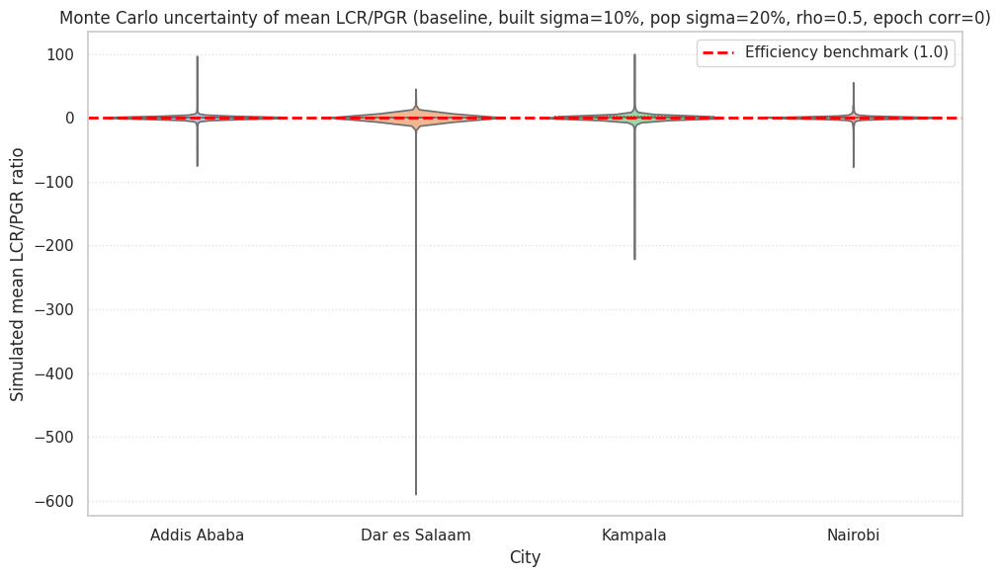

In [34]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# ---------------- Configuration ----------------
SENS_CONFIG['SIGMA_BUILT'] = [0.05, 0.10, 0.20]   # paired by position with SIGMA_POP
SENS_CONFIG['SIGMA_POP']   = [0.10, 0.20, 0.30]
SENS_CONFIG['RHO_LIST']    = [0.0, 0.5]           # built-pop correlation within an epoch
SENS_CONFIG['EPOCH_CORR']  = [0.0, 0.5]           # share of error shared across epochs of a series
VIOLIN_SETTING = dict(sig_idx=1, rho=0.5, epoch_corr=0.0)

# ---------------- Input arrays (observed epochs only) ----------------
def to_arrays(df):
    obs_end_year = SENS_CONFIG.get('OBS_END', SENS_CONFIG.get('obs_end', 2020))
    d = df[df['year'] <= obs_end_year].sort_values(['city', 'year'])
    cities_ = sorted(d['city'].unique())
    b = np.array([d.loc[d['city'] == c, 'built_up_area_km2'].values for c in cities_], dtype=float)
    p = np.array([d.loc[d['city'] == c, 'total_population'].values for c in cities_], dtype=float)
    yrs = np.array(sorted(d['year'].unique()))
    return cities_, yrs, b, p

cities, epochs, built_base, pop_base = to_arrays(df_baseline)
_, _, built_comm, pop_comm = to_arrays(df_sens_comm)
dt = np.diff(epochs).astype(float)
C, T = built_base.shape
N_MC = SENS_CONFIG.get('N_MC', 1000)
PGR_MIN = SENS_CONFIG.get('PGR_MIN', 0.1)

# ---------------- Core simulation ----------------
def simulate(b_arr, p_arr, sig_b, sig_p, rho, phi, rng):
    """Return LCR, PGR arrays of shape [C, T-1, N_MC] after multiplicative lognormal noise."""
    z_b = rng.standard_normal((C, T, N_MC))
    z_p_ind = rng.standard_normal((C, T, N_MC))
    z_p = rho * z_b + np.sqrt(1.0 - rho ** 2) * z_p_ind          # corr(built, pop) = rho within each epoch
    if phi > 0:
        shared_b = rng.standard_normal((C, 1, N_MC))
        shared_p = rho * shared_b + np.sqrt(1.0 - rho ** 2) * rng.standard_normal((C, 1, N_MC))
        z_b = np.sqrt(phi) * shared_b + np.sqrt(1.0 - phi) * z_b
        z_p = np.sqrt(phi) * shared_p + np.sqrt(1.0 - phi) * z_p
    err_b = np.exp(sig_b * z_b - 0.5 * sig_b ** 2)                # mean-one lognormal factor
    err_p = np.exp(sig_p * z_p - 0.5 * sig_p ** 2)
    b = b_arr[:, :, None] * err_b
    p = p_arr[:, :, None] * err_p
    lcr = np.diff(np.log(b), axis=1) / dt[None, :, None] * 100
    pgr = np.diff(np.log(p), axis=1) / dt[None, :, None] * 100
    return lcr, pgr

# ---------------- Sanity checks ----------------
base_means = df_sens3_summary['Observed: Mean of Ratios'].loc[cities].values
lcr0, pgr0 = simulate(built_base, pop_base, 0.0, 0.0, 0.0, 0.0, np.random.default_rng(0))
mc0 = (lcr0 / pgr0).mean(axis=1)                                  # [C, N_MC]
print("sigma=0 check (all runs equal baseline):",
      "PASS" if np.allclose(mc0, base_means[:, None], atol=1e-6) else "FAIL")
print("Baseline mean LCRPGR:", dict(zip(cities, base_means.round(4))))
baseline_rank = pd.Series(base_means).rank(method='min').values

# ---------------- Run Monte Carlo ----------------
rng = np.random.default_rng(SENS_CONFIG.get('SEED', 42))
records, violin_data = [], {}
for label, b_arr, p_arr in [('baseline', built_base, pop_base), ('common', built_comm, pop_comm)]:
    for i, (sig_b, sig_p) in enumerate(zip(SENS_CONFIG['SIGMA_BUILT'], SENS_CONFIG['SIGMA_POP'])):
        for rho in SENS_CONFIG['RHO_LIST']:
            for phi in SENS_CONFIG['EPOCH_CORR']:
                lcr, pgr = simulate(b_arr, p_arr, sig_b, sig_p, rho, phi, rng)
                mean_ratio = (lcr / pgr).mean(axis=1)             # [C, N_MC] mean of ratios
                ratio_of_means = lcr.mean(axis=1) / pgr.mean(axis=1)
                unstable = ((np.abs(pgr) < PGR_MIN) | (pgr < 0)).any(axis=1)   # [C, N_MC]
                ranks = pd.DataFrame(mean_ratio).rank(method='min').values     # rank across cities per run
                rank_match = np.mean(np.all(ranks == baseline_rank[:, None], axis=0))
                if (label == 'baseline' and i == VIOLIN_SETTING['sig_idx']
                        and rho == VIOLIN_SETTING['rho'] and phi == VIOLIN_SETTING['epoch_corr']):
                    violin_data = {cities[c]: mean_ratio[c] for c in range(C)}
                for c, city in enumerate(cities):
                    records.append({
                        'scenario': label, 'sigma_built': sig_b, 'sigma_pop': sig_p,
                        'rho': rho, 'epoch_corr': phi, 'city': city,
                        'median_LCRPGR': np.median(mean_ratio[c]),
                        'p5_LCRPGR': np.percentile(mean_ratio[c], 5),
                        'p95_LCRPGR': np.percentile(mean_ratio[c], 95),
                        'median_ratio_of_means': np.median(ratio_of_means[c]),
                        'share_efficient': np.mean(mean_ratio[c] <= 1.0),
                        'share_unstable_runs': np.mean(unstable[c]),
                        'rank_match_share': rank_match})

df_mc_summary = pd.DataFrame(records)
mc_save_path = os.path.join(SENS_CONFIG['output_dir'], 'sensitivity_monte_carlo_uncertainty.csv')
df_mc_summary.to_csv(mc_save_path, index=False)
print("Saved:", mc_save_path)
display(df_mc_summary.head(10).round(3))

# ---------------- Violin plot ----------------
if violin_data:
    plt.figure(figsize=(10, 6))
    sns.violinplot(data=pd.DataFrame(violin_data), palette='pastel', inner='quartile', cut=0)
    plt.axhline(1.0, color='red', linestyle='--', linewidth=2, label='Efficiency benchmark (1.0)')
    plt.title('Monte Carlo uncertainty of mean LCR/PGR (baseline, built sigma=10%, pop sigma=20%, rho=0.5, epoch corr=0)')
    plt.ylabel('Simulated mean LCR/PGR ratio'); plt.xlabel('City'); plt.legend()
    plt.grid(axis='y', linestyle=':', alpha=0.6); plt.tight_layout()
    plt.savefig(os.path.join(SENS_CONFIG['output_dir'], 'sensitivity_monte_carlo_violins.png'), dpi=300)
    plt.show()

### Sensitivity Analysis 5: Monte Carlo Input Uncertainty
In this section, we analyze the propagation of measurement errors in built-up area and population estimates to the final LCRPGR ratios using a parameterized Monte Carlo simulation. We draw $N$ multiplicative lognormal errors with predefined relative standard deviations ($\sigma$), inner-epoch correlations ($\rho$), and temporal correlations across epochs.

**Cell purpose.** Run the Monte Carlo uncertainty analysis and summarize the simulated efficiency distributions.

The original code and saved output are retained unchanged.

sigma=0 check (all runs equal baseline): PASS
Baseline mean LCRPGR: {'Addis Ababa': np.float64(0.7859), 'Dar es Salaam': np.float64(0.4571), 'Kampala': np.float64(0.9183), 'Nairobi': np.float64(0.8643)}
Saved: /content/drive/MyDrive/Urban_Expansion_Analysis/Sensitivity/sensitivity_monte_carlo_uncertainty.csv


,scenario,sigma_built,sigma_pop,rho,epoch_corr,city,median_LCRPGR,p5_LCRPGR,p95_LCRPGR,median_ratio_of_means,share_efficient,share_unstable_runs,rank_match_share
0,baseline,0.05,0.1,0.0,0.0,Addis Ababa,0.743,-2.888,4.928,0.773,0.647,0.702,0.073
1,baseline,0.05,0.1,0.0,0.0,Dar es Salaam,0.568,-0.386,1.529,0.437,0.877,0.255,0.073
2,baseline,0.05,0.1,0.0,0.0,Kampala,1.078,-2.384,3.930,0.915,0.442,0.501,0.073
3,baseline,0.05,0.1,0.0,0.0,Nairobi,0.834,-2.428,4.848,0.884,0.597,0.733,0.073
4,baseline,0.05,0.1,0.0,0.5,Addis Ababa,0.938,-1.584,2.583,0.770,0.573,0.325,0.126
5,baseline,0.05,0.1,0.0,0.5,Dar es Salaam,0.522,0.419,0.899,0.435,0.963,0.042,0.126
6,baseline,0.05,0.1,0.0,0.5,Kampala,1.122,-0.251,3.001,0.916,0.280,0.174,0.126
7,baseline,0.05,0.1,0.0,0.5,Nairobi,1.023,-1.295,3.439,0.886,0.475,0.406,0.126
8,baseline,0.05,0.1,0.5,0.0,Addis Ababa,0.832,-1.217,2.886,0.771,0.652,0.661,0.096
9,baseline,0.05,0.1,0.5,0.0,Dar es Salaam,0.499,-0.249,1.349,0.436,0.919,0.251,0.096


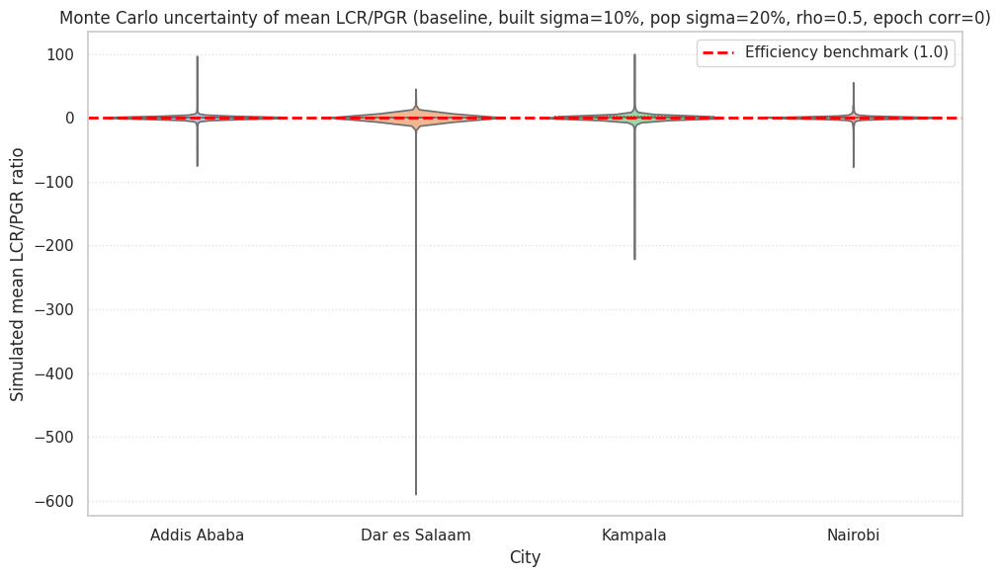

In [35]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# ---------------- Configuration ----------------
SENS_CONFIG['SIGMA_BUILT'] = [0.05, 0.10, 0.20]   # paired by position with SIGMA_POP
SENS_CONFIG['SIGMA_POP']   = [0.10, 0.20, 0.30]
SENS_CONFIG['RHO_LIST']    = [0.0, 0.5]           # built-pop correlation within an epoch
SENS_CONFIG['EPOCH_CORR']  = [0.0, 0.5]           # share of error shared across epochs of a series
VIOLIN_SETTING = dict(sig_idx=1, rho=0.5, epoch_corr=0.0)

# ---------------- Input arrays (observed epochs only) ----------------
def to_arrays(df):
    obs_end_year = SENS_CONFIG.get('OBS_END', SENS_CONFIG.get('obs_end', 2020))
    d = df[df['year'] <= obs_end_year].sort_values(['city', 'year'])
    cities_ = sorted(d['city'].unique())
    b = np.array([d.loc[d['city'] == c, 'built_up_area_km2'].values for c in cities_], dtype=float)
    p = np.array([d.loc[d['city'] == c, 'total_population'].values for c in cities_], dtype=float)
    yrs = np.array(sorted(d['year'].unique()))
    return cities_, yrs, b, p

cities, epochs, built_base, pop_base = to_arrays(df_baseline)
_, _, built_comm, pop_comm = to_arrays(df_sens_comm)
dt = np.diff(epochs).astype(float)
C, T = built_base.shape
N_MC = SENS_CONFIG.get('N_MC', 1000)
PGR_MIN = SENS_CONFIG.get('PGR_MIN', 0.1)

# ---------------- Core simulation ----------------
def simulate(b_arr, p_arr, sig_b, sig_p, rho, phi, rng):
    """Return LCR, PGR arrays of shape [C, T-1, N_MC] after multiplicative lognormal noise."""
    z_b = rng.standard_normal((C, T, N_MC))
    z_p_ind = rng.standard_normal((C, T, N_MC))
    z_p = rho * z_b + np.sqrt(1.0 - rho ** 2) * z_p_ind          # corr(built, pop) = rho within each epoch
    if phi > 0:
        shared_b = rng.standard_normal((C, 1, N_MC))
        shared_p = rho * shared_b + np.sqrt(1.0 - rho ** 2) * rng.standard_normal((C, 1, N_MC))
        z_b = np.sqrt(phi) * shared_b + np.sqrt(1.0 - phi) * z_b
        z_p = np.sqrt(phi) * shared_p + np.sqrt(1.0 - phi) * z_p
    err_b = np.exp(sig_b * z_b - 0.5 * sig_b ** 2)
    err_p = np.exp(sig_p * z_p - 0.5 * sig_p ** 2)
    b = b_arr[:, :, None] * err_b
    p = p_arr[:, :, None] * err_p
    lcr = np.diff(np.log(b), axis=1) / dt[None, :, None] * 100
    pgr = np.diff(np.log(p), axis=1) / dt[None, :, None] * 100
    return lcr, pgr

# ---------------- Sanity checks ----------------
base_means = df_sens3_summary['Observed: Mean of Ratios'].loc[cities].values
lcr0, pgr0 = simulate(built_base, pop_base, 0.0, 0.0, 0.0, 0.0, np.random.default_rng(0))
mc0 = (lcr0 / pgr0).mean(axis=1)                                  # [C, N_MC]
print("sigma=0 check (all runs equal baseline):",
      "PASS" if np.allclose(mc0, base_means[:, None], atol=1e-6) else "FAIL")
print("Baseline mean LCRPGR:", dict(zip(cities, base_means.round(4))))
baseline_rank = pd.Series(base_means).rank(method='min').values

# ---------------- Run Monte Carlo ----------------
rng = np.random.default_rng(SENS_CONFIG.get('SEED', 42))
records, violin_data = [], {}
for label, b_arr, p_arr in [('baseline', built_base, pop_base), ('common', built_comm, pop_comm)]:
    for i, (sig_b, sig_p) in enumerate(zip(SENS_CONFIG['SIGMA_BUILT'], SENS_CONFIG['SIGMA_POP'])):
        for rho in SENS_CONFIG['RHO_LIST']:
            for phi in SENS_CONFIG['EPOCH_CORR']:
                lcr, pgr = simulate(b_arr, p_arr, sig_b, sig_p, rho, phi, rng)
                mean_ratio = (lcr / pgr).mean(axis=1)             # [C, N_MC] mean of ratios
                ratio_of_means = lcr.mean(axis=1) / pgr.mean(axis=1)
                unstable = ((np.abs(pgr) < PGR_MIN) | (pgr < 0)).any(axis=1)   # [C, N_MC]
                ranks = pd.DataFrame(mean_ratio).rank(method='min').values     # rank across cities per run
                rank_match = np.mean(np.all(ranks == baseline_rank[:, None], axis=0))
                if (label == 'baseline' and i == VIOLIN_SETTING['sig_idx']
                        and rho == VIOLIN_SETTING['rho'] and phi == VIOLIN_SETTING['epoch_corr']):
                    violin_data = {cities[c]: mean_ratio[c] for c in range(C)}
                for c, city in enumerate(cities):
                    records.append({
                        'scenario': label, 'sigma_built': sig_b, 'sigma_pop': sig_p,
                        'rho': rho, 'epoch_corr': phi, 'city': city,
                        'median_LCRPGR': np.median(mean_ratio[c]),
                        'p5_LCRPGR': np.percentile(mean_ratio[c], 5),
                        'p95_LCRPGR': np.percentile(mean_ratio[c], 95),
                        'median_ratio_of_means': np.median(ratio_of_means[c]),
                        'share_efficient': np.mean(mean_ratio[c] <= 1.0),
                        'share_unstable_runs': np.mean(unstable[c]),
                        'rank_match_share': rank_match})

df_mc_summary = pd.DataFrame(records)
mc_save_path = os.path.join(SENS_CONFIG['output_dir'], 'sensitivity_monte_carlo_uncertainty.csv')
df_mc_summary.to_csv(mc_save_path, index=False)
print("Saved:", mc_save_path)
display(df_mc_summary.head(10).round(3))

# ---------------- Violin plot ----------------
violin_data_runs = violin_data
if violin_data_runs:
    plt.figure(figsize=(10, 6))
    sns.violinplot(data=pd.DataFrame(violin_data_runs), palette='pastel', inner='quartile', cut=0)
    plt.axhline(1.0, color='red', linestyle='--', linewidth=2, label='Efficiency benchmark (1.0)')
    plt.title('Monte Carlo uncertainty of mean LCR/PGR (baseline, built sigma=10%, pop sigma=20%, rho=0.5, epoch corr=0)')
    plt.ylabel('Simulated mean LCR/PGR ratio'); plt.xlabel('City'); plt.legend()
    plt.grid(axis='y', linestyle=':', alpha=0.6); plt.tight_layout()
    plt.savefig(os.path.join(SENS_CONFIG['output_dir'], 'sensitivity_monte_carlo_violins.png'), dpi=300)
    plt.show()

### Sensitivity Analysis 4: Correlation Robustness
In this section, we analyze the correlation between Land Consumption Rate (LCR) and Population Growth Rate (PGR) under observed intervals (excluding 2025). We calculate Pearson and Spearman correlations of both rates and absolute levels, first differences, lag-1 autocorrelations, and Durbin-Watson test statistics. We also compare the robustness of these associations across the original, common, and fixed_2020 scenarios.

**Cell purpose.** Calculate alternative correlation, differenced-series, autocorrelation, and Durbin–Watson diagnostics.

The original code and saved output are retained unchanged.

sigma=0 check (all runs equal baseline): PASS
Baseline mean LCRPGR: {'Addis Ababa': np.float64(0.7859), 'Dar es Salaam': np.float64(0.4571), 'Kampala': np.float64(0.9183), 'Nairobi': np.float64(0.8643)}
Saved: /content/drive/MyDrive/Urban_Expansion_Analysis/Sensitivity/sensitivity_monte_carlo_uncertainty.csv


,scenario,sigma_built,sigma_pop,rho,epoch_corr,city,median_LCRPGR,p5_LCRPGR,p95_LCRPGR,median_ratio_of_means,share_efficient,share_unstable_runs,rank_match_share
0,baseline,0.05,0.1,0.0,0.0,Addis Ababa,0.743,-2.888,4.928,0.773,0.647,0.702,0.073
1,baseline,0.05,0.1,0.0,0.0,Dar es Salaam,0.568,-0.386,1.529,0.437,0.877,0.255,0.073
2,baseline,0.05,0.1,0.0,0.0,Kampala,1.078,-2.384,3.930,0.915,0.442,0.501,0.073
3,baseline,0.05,0.1,0.0,0.0,Nairobi,0.834,-2.428,4.848,0.884,0.597,0.733,0.073
4,baseline,0.05,0.1,0.0,0.5,Addis Ababa,0.938,-1.584,2.583,0.770,0.573,0.325,0.126
5,baseline,0.05,0.1,0.0,0.5,Dar es Salaam,0.522,0.419,0.899,0.435,0.963,0.042,0.126
6,baseline,0.05,0.1,0.0,0.5,Kampala,1.122,-0.251,3.001,0.916,0.280,0.174,0.126
7,baseline,0.05,0.1,0.0,0.5,Nairobi,1.023,-1.295,3.439,0.886,0.475,0.406,0.126
8,baseline,0.05,0.1,0.5,0.0,Addis Ababa,0.832,-1.217,2.886,0.771,0.652,0.661,0.096
9,baseline,0.05,0.1,0.5,0.0,Dar es Salaam,0.499,-0.249,1.349,0.436,0.919,0.251,0.096


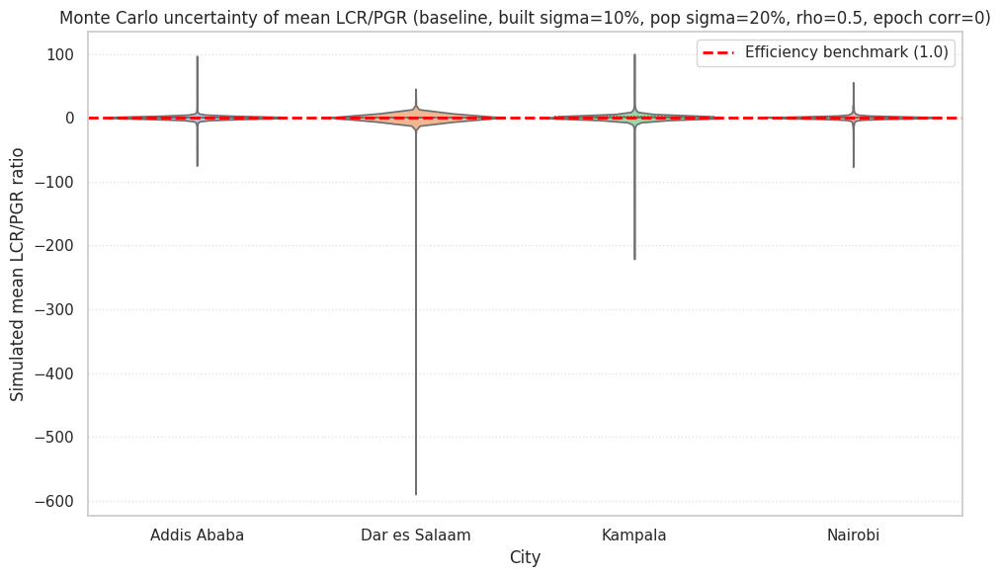

In [36]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# ---------------- Configuration ----------------
SENS_CONFIG['SIGMA_BUILT'] = [0.05, 0.10, 0.20]   # paired by position with SIGMA_POP
SENS_CONFIG['SIGMA_POP']   = [0.10, 0.20, 0.30]
SENS_CONFIG['RHO_LIST']    = [0.0, 0.5]           # built-pop correlation within an epoch
SENS_CONFIG['EPOCH_CORR']  = [0.0, 0.5]           # share of error shared across epochs of a series
VIOLIN_SETTING = dict(sig_idx=1, rho=0.5, epoch_corr=0.0)

# ---------------- Input arrays (observed epochs only) ----------------
def to_arrays(df):
    d = df[df['year'] <= SENS_CONFIG['OBS_END']].sort_values(['city', 'year'])
    cities_ = sorted(d['city'].unique())
    b = np.array([d.loc[d['city'] == c, 'built_up_area_km2'].values for c in cities_], dtype=float)
    p = np.array([d.loc[d['city'] == c, 'total_population'].values for c in cities_], dtype=float)
    yrs = np.array(sorted(d['year'].unique()))
    return cities_, yrs, b, p

cities, epochs, built_base, pop_base = to_arrays(df_baseline)
_, _, built_comm, pop_comm = to_arrays(df_sens_comm)
dt = np.diff(epochs).astype(float)
C, T = built_base.shape
N_MC = SENS_CONFIG['N_MC']
PGR_MIN = SENS_CONFIG.get('PGR_MIN', 0.1)

# ---------------- Core simulation ----------------
def simulate(b_arr, p_arr, sig_b, sig_p, rho, phi, rng):
    """Return LCR, PGR arrays of shape [C, T-1, N_MC] after multiplicative lognormal noise."""
    z_b = rng.standard_normal((C, T, N_MC))
    z_p_ind = rng.standard_normal((C, T, N_MC))
    z_p = rho * z_b + np.sqrt(1.0 - rho ** 2) * z_p_ind          # corr(built, pop) = rho within each epoch
    if phi > 0:                                                   # error component shared across epochs
        shared_b = rng.standard_normal((C, 1, N_MC))
        shared_p = rho * shared_b + np.sqrt(1.0 - rho ** 2) * rng.standard_normal((C, 1, N_MC))
        z_b = np.sqrt(phi) * shared_b + np.sqrt(1.0 - phi) * z_b
        z_p = np.sqrt(phi) * shared_p + np.sqrt(1.0 - phi) * z_p
    err_b = np.exp(sig_b * z_b - 0.5 * sig_b ** 2)                # mean-one lognormal factor
    err_p = np.exp(sig_p * z_p - 0.5 * sig_p ** 2)
    b = b_arr[:, :, None] * err_b
    p = p_arr[:, :, None] * err_p
    lcr = np.diff(np.log(b), axis=1) / dt[None, :, None] * 100
    pgr = np.diff(np.log(p), axis=1) / dt[None, :, None] * 100
    return lcr, pgr

# ---------------- Sanity checks ----------------
base_means = df_sens3_summary['Observed: Mean of Ratios'].loc[cities].values
lcr0, pgr0 = simulate(built_base, pop_base, 0.0, 0.0, 0.0, 0.0, np.random.default_rng(0))
mc0 = (lcr0 / pgr0).mean(axis=1)                                  # [C, N_MC]
print("sigma=0 check (all runs equal baseline):",
      "PASS" if np.allclose(mc0, base_means[:, None], atol=1e-6) else "FAIL")
print("Baseline mean LCRPGR:", dict(zip(cities, base_means.round(4))))
baseline_rank = pd.Series(base_means).rank(method='min').values

# ---------------- Run Monte Carlo ----------------
rng = np.random.default_rng(SENS_CONFIG['SEED'])
records, violin_data = [], {}
for label, b_arr, p_arr in [('baseline', built_base, pop_base), ('common', built_comm, pop_comm)]:
    for i, (sig_b, sig_p) in enumerate(zip(SENS_CONFIG['SIGMA_BUILT'], SENS_CONFIG['SIGMA_POP'])):
        for rho in SENS_CONFIG['RHO_LIST']:
            for phi in SENS_CONFIG['EPOCH_CORR']:
                lcr, pgr = simulate(b_arr, p_arr, sig_b, sig_p, rho, phi, rng)
                mean_ratio = (lcr / pgr).mean(axis=1)             # [C, N_MC] mean of ratios
                ratio_of_means = lcr.mean(axis=1) / pgr.mean(axis=1)
                unstable = ((np.abs(pgr) < PGR_MIN) | (pgr < 0)).any(axis=1)   # [C, N_MC]
                ranks = pd.DataFrame(mean_ratio).rank(method='min').values     # rank across cities per run
                rank_match = np.mean(np.all(ranks == baseline_rank[:, None], axis=0))
                if (label == 'baseline' and i == VIOLIN_SETTING['sig_idx']
                        and rho == VIOLIN_SETTING['rho'] and phi == VIOLIN_SETTING['epoch_corr']):
                    violin_data = {cities[c]: mean_ratio[c] for c in range(C)}
                for c, city in enumerate(cities):
                    records.append({
                        'scenario': label, 'sigma_built': sig_b, 'sigma_pop': sig_p,
                        'rho': rho, 'epoch_corr': phi, 'city': city,
                        'median_LCRPGR': np.median(mean_ratio[c]),
                        'p5_LCRPGR': np.percentile(mean_ratio[c], 5),
                        'p95_LCRPGR': np.percentile(mean_ratio[c], 95),
                        'median_ratio_of_means': np.median(ratio_of_means[c]),
                        'share_efficient': np.mean(mean_ratio[c] <= 1.0),
                        'share_unstable_runs': np.mean(unstable[c]),
                        'rank_match_share': rank_match})

df_mc_summary = pd.DataFrame(records)
mc_save_path = os.path.join(SENS_CONFIG['output_dir'], 'sensitivity_monte_carlo_uncertainty.csv')
df_mc_summary.to_csv(mc_save_path, index=False)
print("Saved:", mc_save_path)
display(df_mc_summary.head(10).round(3))

# ---------------- Violin plot ----------------
violin_data_runs = violin_data
if violin_data_runs:
    plt.figure(figsize=(10, 6))
    sns.violinplot(data=pd.DataFrame(violin_data_runs), palette='pastel', inner='quartile', cut=0)
    plt.axhline(1.0, color='red', linestyle='--', linewidth=2, label='Efficiency benchmark (1.0)')
    plt.title('Monte Carlo uncertainty of mean LCR/PGR (baseline, built sigma=10%, pop sigma=20%, rho=0.5, epoch corr=0)')
    plt.ylabel('Simulated mean LCR/PGR ratio'); plt.xlabel('City'); plt.legend()
    plt.grid(axis='y', linestyle=':', alpha=0.6); plt.tight_layout()
    plt.savefig(os.path.join(SENS_CONFIG['output_dir'], 'sensitivity_monte_carlo_violins.png'), dpi=300)
    plt.show()

**Cell purpose.** Generate and save the selected Monte Carlo uncertainty violin plot.

The original code and saved output are retained unchanged.

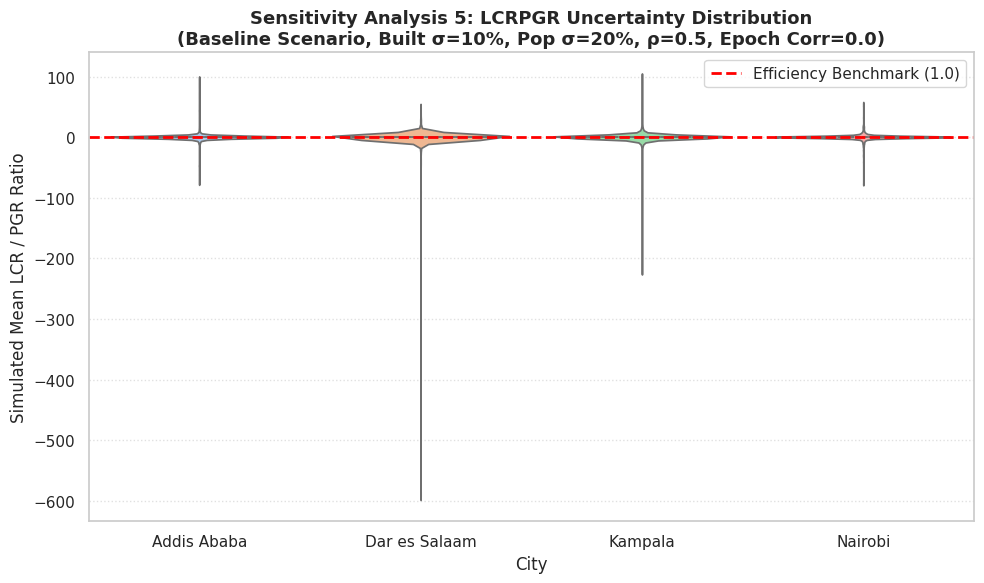

Saved violin plot to /content/drive/MyDrive/Urban_Expansion_Analysis/Sensitivity/sensitivity_monte_carlo_violins.png


In [37]:
# 3. Generate Violin Plot for selected scenario
if violin_data_runs:
    plt.figure(figsize=(10, 6))
    df_violin = pd.DataFrame(violin_data_runs)

    sns.violinplot(data=df_violin, palette='pastel', inner='quartile')
    plt.axhline(1.0, color='red', linestyle='--', linewidth=2, label='Efficiency Benchmark (1.0)')
    plt.title('Sensitivity Analysis 5: LCRPGR Uncertainty Distribution\n(Baseline Scenario, Built σ=10%, Pop σ=20%, ρ=0.5, Epoch Corr=0.0)', fontsize=13, fontweight='bold')
    plt.ylabel('Simulated Mean LCR / PGR Ratio')
    plt.xlabel('City')
    plt.grid(axis='y', linestyle=':', alpha=0.6)
    plt.legend()

    plt.tight_layout()
    violin_save_path = os.path.join(SENS_CONFIG['output_dir'], 'sensitivity_monte_carlo_violins.png')
    plt.savefig(violin_save_path, dpi=300)
    plt.show()
    print(f"Saved violin plot to {violin_save_path}")

## 7. Manuscript figures and high-resolution chart exports

These cells generate the principal manuscript figures and publication-oriented chart packages.

**Cell purpose.** Generate the principal multi-panel publication figure package and high-resolution exports.

The original code and saved output are retained unchanged.

=== FIGURE RESOLUTION VERIFICATION REPORT ===


,File,Resolution,Stored DPI,Print Width (in),Effective DPI,Status
0,Figure6_composite.png,4736x4135,600,8.0,592,PASS
1,Figure6_Addis_Ababa_600dpi.png,2948x2215,600,4.5,655,PASS
2,Figure6_Dar_es_Salaam_600dpi.png,3037x2215,600,4.5,675,PASS
3,Figure6_Kampala_600dpi.png,2850x2215,600,4.5,633,PASS
4,Figure6_Nairobi_600dpi.png,2813x2215,600,4.5,625,PASS
5,Figure7_composite.png,4724x2335,600,8.0,590,PASS
6,Figure7a_LCR_600dpi.png,2629x2335,600,4.5,584,PASS
7,Figure7b_PGR_600dpi.png,2630x2335,600,4.5,584,PASS



Zip created at: /content/drive/MyDrive/Urban_Expansion_Analysis/HighRes_Figures_6_7.zip. Downloading to browser...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


=== VISUAL PREVIEWS ===
Figure 6 Composite (600 DPI Plot Preview):


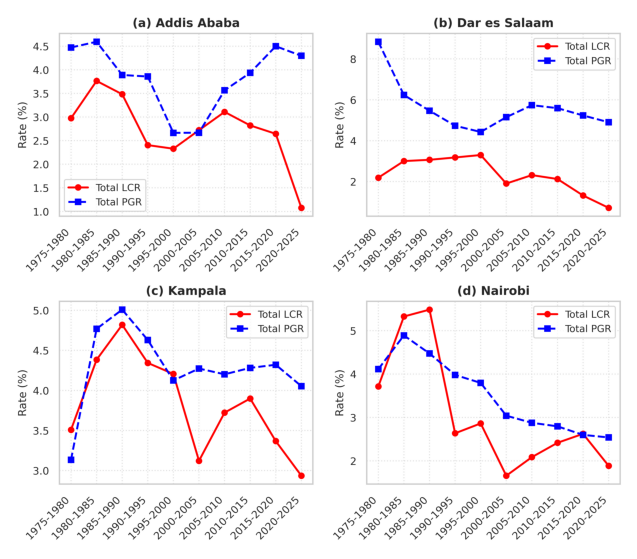


Figure 7 Composite (600 DPI Plot Preview):


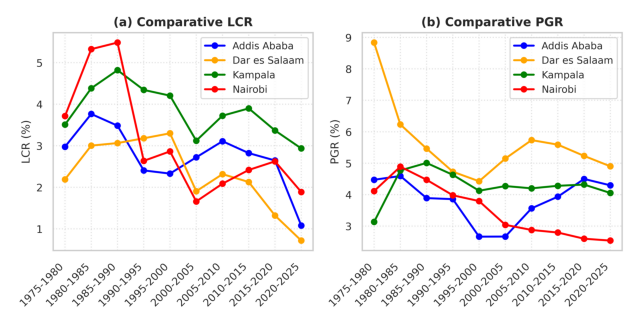

In [38]:
import os
import zipfile
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from PIL import Image
from google.colab import files

# Configure global matplotlib settings for publication-quality exports (smaller title, larger plot area)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['xtick.labelsize'] = 9.5
plt.rcParams['ytick.labelsize'] = 9.5
plt.rcParams['legend.fontsize'] = 9

# 1. Setup Export Paths
fig_dir = os.path.join(BASE_EXPORT_PATH, 'HighRes_Figures_6_7')
os.makedirs(fig_dir, exist_ok=True)

# Filter out 'df_all_cities' to get unique data in chronological order
df_all_cities_sorted = df_all_cities.sort_values(by=['city', 'year'])
intervals = sorted(df_all_cities_sorted['interval'].unique())
cities_list = ['Addis Ababa', 'Dar es Salaam', 'Kampala', 'Nairobi']

# Helper to apply layout details to subplots
def style_ax(ax):
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.tick_params(axis='x', rotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

# ==========================================
# 2. GENERATE & EXPORT FIGURE 6
# ==========================================
fig6, axes6 = plt.subplots(2, 2, figsize=(8.0, 7.0), facecolor='white')
axes6_flat = axes6.flatten()
panel_letters_6 = ['(a)', '(b)', '(c)', '(d)']

for idx, city in enumerate(cities_list):
    ax = axes6_flat[idx]
    city_data = df_all_cities_sorted[df_all_cities_sorted['city'] == city]

    # Plot LCR (solid red with circle markers) & PGR (dashed blue with square markers)
    ax.plot(city_data['interval'], city_data['LCR'], color='red', linestyle='-',
            marker='o', markersize=5, linewidth=1.8, label='Total LCR')
    ax.plot(city_data['interval'], city_data['PGR'], color='blue', linestyle='--',
            marker='s', markersize=5, linewidth=1.8, label='Total PGR')

    ax.set_title(f"{panel_letters_6[idx]} {city}", fontsize=11, fontweight='bold')
    ax.set_ylabel('Rate (%)', fontsize=10)
    style_ax(ax)
    ax.legend(loc='best')

plt.tight_layout()

# Save Figure 6 composite
fig6_composite_png = os.path.join(fig_dir, 'Figure6_composite.png')
fig6_composite_pdf = os.path.join(fig_dir, 'Figure6_composite.pdf')
fig6.savefig(fig6_composite_png, dpi=600, bbox_inches='tight', facecolor='white')
fig6.savefig(fig6_composite_pdf, bbox_inches='tight')
plt.close(fig6)

# Save Figure 6 individual panels
for idx, city in enumerate(cities_list):
    fig_single, ax_single = plt.subplots(figsize=(4.5, 3.8), facecolor='white')
    city_data = df_all_cities_sorted[df_all_cities_sorted['city'] == city]

    ax_single.plot(city_data['interval'], city_data['LCR'], color='red', linestyle='-',
                   marker='o', markersize=5, linewidth=1.8, label='Total LCR')
    ax_single.plot(city_data['interval'], city_data['PGR'], color='blue', linestyle='--',
                   marker='s', markersize=5, linewidth=1.8, label='Total PGR')

    ax_single.set_title(f"{city}: Land Consumption vs Population Growth", fontsize=11, fontweight='bold')
    ax_single.set_ylabel('Rate (%)', fontsize=10)
    style_ax(ax_single)
    ax_single.legend(loc='best')

    plt.tight_layout()
    city_filename = city.replace(' ', '_')
    fig_single.savefig(os.path.join(fig_dir, f'Figure6_{city_filename}_600dpi.png'),
                       dpi=600, bbox_inches='tight', facecolor='white')
    plt.close(fig_single)

# ==========================================
# 3. GENERATE & EXPORT FIGURE 7
# ==========================================
fig7, axes7 = plt.subplots(1, 2, figsize=(8.0, 4.0), facecolor='white')
city_colors = {
    'Addis Ababa': 'blue',
    'Dar es Salaam': 'orange',
    'Kampala': 'green',
    'Nairobi': 'red'
}

# Figure 7(a) Comparative LCR
ax_a = axes7[0]
for city in cities_list:
    city_data = df_all_cities_sorted[df_all_cities_sorted['city'] == city]
    ax_a.plot(city_data['interval'], city_data['LCR'], color=city_colors[city],
              marker='o', markersize=5, linewidth=1.8, label=city)
ax_a.set_title('(a) Comparative LCR', fontsize=11, fontweight='bold')
ax_a.set_ylabel('LCR (%)', fontsize=10)
style_ax(ax_a)
ax_a.legend(loc='best')

# Figure 7(b) Comparative PGR
ax_b = axes7[1]
for city in cities_list:
    city_data = df_all_cities_sorted[df_all_cities_sorted['city'] == city]
    ax_b.plot(city_data['interval'], city_data['PGR'], color=city_colors[city],
              marker='o', markersize=5, linewidth=1.8, label=city)
ax_b.set_title('(b) Comparative PGR', fontsize=11, fontweight='bold')
ax_b.set_ylabel('PGR (%)', fontsize=10)
style_ax(ax_b)
ax_b.legend(loc='best')

plt.tight_layout()

# Save Figure 7 composite
fig7_composite_png = os.path.join(fig_dir, 'Figure7_composite.png')
fig7_composite_pdf = os.path.join(fig_dir, 'Figure7_composite.pdf')
fig7.savefig(fig7_composite_png, dpi=600, bbox_inches='tight', facecolor='white')
fig7.savefig(fig7_composite_pdf, bbox_inches='tight')
plt.close(fig7)

# Save Figure 7 individual panels
# Panel 7a
fig7a, ax_7a = plt.subplots(figsize=(4.5, 4.0), facecolor='white')
for city in cities_list:
    city_data = df_all_cities_sorted[df_all_cities_sorted['city'] == city]
    ax_7a.plot(city_data['interval'], city_data['LCR'], color=city_colors[city],
              marker='o', markersize=5, linewidth=1.8, label=city)
ax_7a.set_title('Comparative Land Consumption Rate (LCR)', fontsize=11, fontweight='bold')
ax_7a.set_ylabel('LCR (%)', fontsize=10)
style_ax(ax_7a)
ax_7a.legend(loc='best')
plt.tight_layout()
fig7a.savefig(os.path.join(fig_dir, 'Figure7a_LCR_600dpi.png'), dpi=600, bbox_inches='tight', facecolor='white')
plt.close(fig7a)

# Panel 7b
fig7b, ax_7b = plt.subplots(figsize=(4.5, 4.0), facecolor='white')
for city in cities_list:
    city_data = df_all_cities_sorted[df_all_cities_sorted['city'] == city]
    ax_7b.plot(city_data['interval'], city_data['PGR'], color=city_colors[city],
              marker='o', markersize=5, linewidth=1.8, label=city)
ax_7b.set_title('Comparative Population Growth Rate (PGR)', fontsize=11, fontweight='bold')
ax_7b.set_ylabel('PGR (%)', fontsize=10)
style_ax(ax_7b)
ax_7b.legend(loc='best')
plt.tight_layout()
fig7b.savefig(os.path.join(fig_dir, 'Figure7b_PGR_600dpi.png'), dpi=600, bbox_inches='tight', facecolor='white')
plt.close(fig7b)

# ==========================================
# 4. RESOLUTION VERIFICATION & METRICS TABLE
# ==========================================
verification_data = []
files_to_verify = [
    ('Figure6_composite.png', 8.0),
    ('Figure6_Addis_Ababa_600dpi.png', 4.5),
    ('Figure6_Dar_es_Salaam_600dpi.png', 4.5),
    ('Figure6_Kampala_600dpi.png', 4.5),
    ('Figure6_Nairobi_600dpi.png', 4.5),
    ('Figure7_composite.png', 8.0),
    ('Figure7a_LCR_600dpi.png', 4.5),
    ('Figure7b_PGR_600dpi.png', 4.5)
]

for filename, target_print_width in files_to_verify:
    filepath = os.path.join(fig_dir, filename)
    with Image.open(filepath) as img:
        width, height = img.size
        stored_dpi = img.info.get('dpi', (600, 600))[0]
        effective_dpi = width / target_print_width
        status = "PASS" if effective_dpi >= 400 else "FAIL"
        verification_data.append({
            'File': filename,
            'Resolution': f"{width}x{height}",
            'Stored DPI': round(stored_dpi),
            'Print Width (in)': target_print_width,
            'Effective DPI': round(effective_dpi),
            'Status': status
        })

df_verif = pd.DataFrame(verification_data)
print("=== FIGURE RESOLUTION VERIFICATION REPORT ===")
display(df_verif)

# ==========================================
# 5. ZIP PACKAGING & DOWNLOAD
# ==========================================
zip_path = os.path.join(BASE_EXPORT_PATH, 'HighRes_Figures_6_7.zip')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files_list in os.walk(fig_dir):
        for file in files_list:
            zipf.write(os.path.join(root, file), arcname=file)

print(f"\nZip created at: {zip_path}. Downloading to browser...")
files.download(zip_path)

# ==========================================
# 6. VISUAL PREVIEW AT THE END
# ==========================================
print("\n=== VISUAL PREVIEWS ===")
print("Figure 6 Composite (600 DPI Plot Preview):")
img6_prev = Image.open(os.path.join(fig_dir, 'Figure6_composite.png'))
plt.figure(figsize=(8.0, 7.0))
plt.imshow(img6_prev)
plt.axis('off')
plt.show()

print("\nFigure 7 Composite (600 DPI Plot Preview):")
img7_prev = Image.open(os.path.join(fig_dir, 'Figure7_composite.png'))
plt.figure(figsize=(8.0, 4.0))
plt.imshow(img7_prev)
plt.axis('off')
plt.show()


**Cell purpose.** Generate the observed/projected Figure 13 comparison outputs and related chart exports.

The original code and saved output are retained unchanged.

In [39]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import zipfile

# Configure global matplotlib settings for publication-quality exports
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['xtick.labelsize'] = 9.5
plt.rcParams['ytick.labelsize'] = 9.5
plt.rcParams['legend.fontsize'] = 9

# Fallback definition of BASE_EXPORT_PATH if not found in globals
try:
    _ = BASE_EXPORT_PATH
except NameError:
    BASE_EXPORT_PATH = '/content/drive/MyDrive/Urban_Expansion_Analysis/'

# Define output directory
output_dir = os.path.join(BASE_EXPORT_PATH, 'Manuscript_Figures_600DPI')
os.makedirs(output_dir, exist_ok=True)
print(f"High-resolution figures will be saved in: {output_dir}")

# Load datasets
df_all_cities_sorted = df_all_cities.sort_values(by=['city', 'year'])
intervals = sorted(df_all_cities_sorted['interval'].unique())
cities_list = ['Addis Ababa', 'Dar es Salaam', 'Kampala', 'Nairobi']
city_colors = {'Addis Ababa': '#1f77b4', 'Dar es Salaam': '#ff7f0e', 'Kampala': '#2ca02c', 'Nairobi': '#d62728'}

def style_axis(ax):
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.tick_params(axis='x', rotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

# ==============================================================================
# 1. FIGURE 10 (URBAN EXPANSION TREND: OBSERVED VS PROJECTED)
# ==============================================================================
fig10, ax10 = plt.subplots(figsize=(6.5, 4.5), facecolor='white')
df_plot = results_df.copy()
df_plot['Total Urban'] = df_plot['Dense Urban'] + df_plot['Semi-dense Urban'] + df_plot['Suburban/Peri-urban'] + df_plot['Urban Centre']

for city in cities_list:
    city_data = df_plot[df_plot['City'] == city].sort_values(by='Year')
    obs_data = city_data[city_data['Year'] <= 2020]
    proj_data = city_data[city_data['Year'] >= 2020]

    # Observed: Solid lines, filled markers
    ax10.plot(obs_data['Year'], obs_data['Total Urban'], color=city_colors[city], linestyle='-', marker='o', markersize=5, linewidth=1.8, label=f"{city} (Observed)")
    # Projected: Dashed line, open marker
    ax10.plot(proj_data['Year'], proj_data['Total Urban'], color=city_colors[city], linestyle='--', marker='o', markerfacecolor='none', markersize=5, linewidth=1.5)

ax10.axvline(2020, color='gray', linestyle=':', linewidth=1.2)
ax10.text(2020, ax10.get_ylim()[1]*0.95, ' 2020 Boundary', color='gray', fontsize=8.5, va='top')
ax10.set_title("Urban Expansion Trend (1975 - 2025)", fontsize=11, fontweight='bold')
ax10.set_ylabel("Total Urban Area (sq km)")
ax10.set_xlabel("Year")
ax10.grid(True, linestyle=':', alpha=0.6)
ax10.legend(loc='upper left')
plt.tight_layout()
fig10.savefig(os.path.join(output_dir, 'Figure10_Urban_Expansion_Trend_600dpi.png'), dpi=600, bbox_inches='tight')
plt.close(fig10)

# ==============================================================================
# 2. FIGURE 13A (LCR vs PGR: OBSERVED ONLY 1975-2020)
# ==============================================================================
fig13A, axes13A = plt.subplots(2, 2, figsize=(8.0, 7.0), facecolor='white')
axes13A_flat = axes13A.flatten()

for idx, city in enumerate(cities_list):
    ax = axes13A_flat[idx]
    city_data = df_all_cities_sorted[(df_all_cities_sorted['city'] == city) & (df_all_cities_sorted['year'] <= 2020)]

    ax.plot(city_data['interval'], city_data['LCR'], color='red', linestyle='-', marker='o', markersize=5, linewidth=1.8, label='LCR')
    ax.plot(city_data['interval'], city_data['PGR'], color='blue', linestyle='-', marker='s', markersize=5, linewidth=1.8, label='PGR')

    ax.set_title(f"({chr(97+idx)}) {city} (Observed)", fontsize=10.5, fontweight='bold')
    ax.set_ylabel('Rate (%)')
    style_axis(ax)
    ax.legend(loc='best')

plt.suptitle("Land Consumption Rate vs Population Growth Rate (Observed: 1975-2020)", fontsize=12, fontweight='bold', y=0.98)
plt.tight_layout()
fig13A.savefig(os.path.join(output_dir, 'Figure13A_observed_1975_2020_600dpi.png'), dpi=600, bbox_inches='tight')
plt.close(fig13A)

# ==============================================================================
# 3. FIGURE 13B (LCR vs PGR: OBSERVED PLUS PROJECTED 1975-2025)
# ==============================================================================
fig13B, axes13B = plt.subplots(2, 2, figsize=(8.0, 7.0), facecolor='white')
axes13B_flat = axes13B.flatten()

for idx, city in enumerate(cities_list):
    ax = axes13B_flat[idx]
    city_data = df_all_cities_sorted[df_all_cities_sorted['city'] == city]
    obs_data = city_data[city_data['year'] <= 2020]
    proj_data = city_data[city_data['year'] >= 2020] # includes 2020-2025

    # Observed: Solid lines with filled markers
    ax.plot(obs_data['interval'], obs_data['LCR'], color='red', linestyle='-', marker='o', markersize=5, linewidth=1.8, label='LCR (Observed)')
    ax.plot(obs_data['interval'], obs_data['PGR'], color='blue', linestyle='-', marker='s', markersize=5, linewidth=1.8, label='PGR (Observed)')

    # Projected segment 2020-2025 (dashed, open markers at 2025)
    ax.plot(proj_data['interval'], proj_data['LCR'], color='red', linestyle='--', marker='o', markerfacecolor='none', markersize=5, linewidth=1.5)
    ax.plot(proj_data['interval'], proj_data['PGR'], color='blue', linestyle='--', marker='s', markerfacecolor='none', markersize=5, linewidth=1.5)

    ax.axvline(8, color='gray', linestyle=':', linewidth=1.2) # Line before the last interval
    ax.set_title(f"({chr(97+idx)}) {city}", fontsize=10.5, fontweight='bold')
    ax.set_ylabel('Rate (%)')
    style_axis(ax)
    ax.legend(loc='best')

plt.suptitle("Land Consumption vs Population Growth (Observed & Projected 1975-2025)", fontsize=12, fontweight='bold', y=0.98)
plt.tight_layout()
fig13B.savefig(os.path.join(output_dir, 'Figure13B_observed_plus_projected_1975_2025_600dpi.png'), dpi=600, bbox_inches='tight')
plt.close(fig13B)

# ==============================================================================
# 4. FIGURE 16A (COMPARATIVE RATES: OBSERVED ONLY 1975-2020)
# ==============================================================================
fig16A, axes16A = plt.subplots(1, 2, figsize=(8.0, 4.0), facecolor='white')

# LCR comparative (Observed)
ax_a = axes16A[0]
for city in cities_list:
    city_data = df_all_cities_sorted[(df_all_cities_sorted['city'] == city) & (df_all_cities_sorted['year'] <= 2020)]
    ax_a.plot(city_data['interval'], city_data['LCR'], color=city_colors[city], linestyle='-', marker='o', markersize=5, linewidth=1.8, label=city)
ax_a.set_title("(a) Comparative LCR (Observed)", fontsize=10.5, fontweight='bold')
ax_a.set_ylabel('LCR (%)')
style_axis(ax_a)
ax_a.legend(loc='best')

# PGR comparative (Observed)
ax_b = axes16A[1]
for city in cities_list:
    city_data = df_all_cities_sorted[(df_all_cities_sorted['city'] == city) & (df_all_cities_sorted['year'] <= 2020)]
    ax_b.plot(city_data['interval'], city_data['PGR'], color=city_colors[city], linestyle='-', marker='s', markersize=5, linewidth=1.8, label=city)
ax_b.set_title("(b) Comparative PGR (Observed)", fontsize=10.5, fontweight='bold')
ax_b.set_ylabel('PGR (%)')
style_axis(ax_b)
ax_b.legend(loc='best')

plt.tight_layout()
fig16A.savefig(os.path.join(output_dir, 'Figure16A_observed_1975_2020_600dpi.png'), dpi=600, bbox_inches='tight')
plt.close(fig16A)

# ==============================================================================
# 5. FIGURE 16B (COMPARATIVE RATES: OBSERVED PLUS PROJECTED 1975-2025)
# ==============================================================================
fig16B, axes16B = plt.subplots(1, 2, figsize=(8.0, 4.0), facecolor='white')

# LCR comparative
ax_a = axes16B[0]
for city in cities_list:
    city_data = df_all_cities_sorted[df_all_cities_sorted['city'] == city]
    obs_data = city_data[city_data['year'] <= 2020]
    proj_data = city_data[city_data['year'] >= 2020]

    ax_a.plot(obs_data['interval'], obs_data['LCR'], color=city_colors[city], linestyle='-', marker='o', markersize=5, linewidth=1.8, label=city)
    ax_a.plot(proj_data['interval'], proj_data['LCR'], color=city_colors[city], linestyle='--', marker='o', markerfacecolor='none', markersize=5, linewidth=1.5)
ax_a.axvline(8, color='gray', linestyle=':', linewidth=1.2)
ax_a.set_title("(a) Comparative LCR", fontsize=10.5, fontweight='bold')
ax_a.set_ylabel('LCR (%)')
style_axis(ax_a)
ax_a.legend(loc='best')

# PGR comparative
ax_b = axes16B[1]
for city in cities_list:
    city_data = df_all_cities_sorted[df_all_cities_sorted['city'] == city]
    obs_data = city_data[city_data['year'] <= 2020]
    proj_data = city_data[city_data['year'] >= 2020]

    ax_b.plot(obs_data['interval'], obs_data['PGR'], color=city_colors[city], linestyle='-', marker='s', markersize=5, linewidth=1.8, label=city)
    ax_b.plot(proj_data['interval'], proj_data['PGR'], color=city_colors[city], linestyle='--', marker='s', markerfacecolor='none', markersize=5, linewidth=1.5)
ax_b.axvline(8, color='gray', linestyle=':', linewidth=1.2)
ax_b.set_title("(b) Comparative PGR", fontsize=10.5, fontweight='bold')
ax_b.set_ylabel('PGR (%)')
style_axis(ax_b)
ax_b.legend(loc='best')

plt.tight_layout()
fig16B.savefig(os.path.join(output_dir, 'Figure16B_observed_plus_projected_1975_2025_600dpi.png'), dpi=600, bbox_inches='tight')
plt.close(fig16B)

# ==============================================================================
# 6. FIGURE 18 (LCR/PGR COMPARATIVE TREND: OBSERVED VS PROJECTED)
# ==============================================================================
fig18, ax18 = plt.subplots(figsize=(6.5, 4.5), facecolor='white')

for city in cities_list:
    city_data = df_all_cities_sorted[df_all_cities_sorted['city'] == city]
    obs_data = city_data[city_data['year'] <= 2020]
    proj_data = city_data[city_data['year'] >= 2020]

    ax18.plot(obs_data['interval'], obs_data['LCRPGR_Ratio'], color=city_colors[city], linestyle='-', marker='o', markersize=5, linewidth=1.8, label=city)
    ax18.plot(proj_data['interval'], proj_data['LCRPGR_Ratio'], color=city_colors[city], linestyle='--', marker='o', markerfacecolor='none', markersize=5, linewidth=1.5)

ax18.axhline(1.0, color='black', linestyle=':', linewidth=1.5, label='Efficiency Benchmark (1.0)')
ax18.axvline(8, color='gray', linestyle=':', linewidth=1.2)
ax18.set_title("Urban Land Use Efficiency (LCR/PGR Ratio) Comparison", fontsize=11, fontweight='bold')
ax18.set_ylabel("LCR / PGR Ratio")
style_axis(ax18)
ax18.legend(loc='upper left')
plt.tight_layout()
fig18.savefig(os.path.join(output_dir, 'Figure18_LCRPGR_Trend_Comparison_600dpi.png'), dpi=600, bbox_inches='tight')
plt.close(fig18)

# ==============================================================================
# 7. EXPORT VERIFICATION REPORT
# ==============================================================================
verification_data = []
files_to_verify = [
    ('Figure10_Urban_Expansion_Trend_600dpi.png', 6.5),
    ('Figure13A_observed_1975_2020_600dpi.png', 8.0),
    ('Figure13B_observed_plus_projected_1975_2025_600dpi.png', 8.0),
    ('Figure16A_observed_1975_2020_600dpi.png', 8.0),
    ('Figure16B_observed_plus_projected_1975_2025_600dpi.png', 8.0),
    ('Figure18_LCRPGR_Trend_Comparison_600dpi.png', 6.5)
]

for filename, target_print_width in files_to_verify:
    filepath = os.path.join(output_dir, filename)
    with Image.open(filepath) as img:
        width, height = img.size
        stored_dpi = img.info.get('dpi', (600, 600))[0]
        effective_dpi = width / target_print_width
        status = "PASS" if effective_dpi >= 450 else "FAIL"
        verification_data.append({
            'File': filename,
            'Resolution': f"{width}x{height}",
            'Stored DPI': round(stored_dpi),
            'Print Width (in)': target_print_width,
            'Effective DPI': round(effective_dpi),
            'Status': status
        })

df_verif = pd.DataFrame(verification_data)
display(df_verif)


High-resolution figures will be saved in: /content/drive/MyDrive/Urban_Expansion_Analysis/Manuscript_Figures_600DPI


,File,Resolution,Stored DPI,Print Width (in),Effective DPI,Status
0,Figure10_Urban_Expansion_Trend_600dpi.png,3814x2637,600,6.5,587,PASS
1,Figure13A_observed_1975_2020_600dpi.png,4688x4142,600,8.0,586,PASS
2,Figure13B_observed_plus_projected_1975_2025_60...,4739x4142,600,8.0,592,PASS
3,Figure16A_observed_1975_2020_600dpi.png,4724x2330,600,8.0,590,PASS
4,Figure16B_observed_plus_projected_1975_2025_60...,4724x2330,600,8.0,590,PASS
5,Figure18_LCRPGR_Trend_Comparison_600dpi.png,3839x2635,600,6.5,591,PASS


**Cell purpose.** Generate observed-only and observed-plus-projected average-rate and efficiency-ratio chart outputs.

The original code and saved output are retained unchanged.

In [40]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import seaborn as sns

# Configure global matplotlib settings for publication-quality exports
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['xtick.labelsize'] = 9.5
plt.rcParams['ytick.labelsize'] = 9.5
plt.rcParams['legend.fontsize'] = 9

# Fallback definition of BASE_EXPORT_PATH
try:
    _ = BASE_EXPORT_PATH
except NameError:
    BASE_EXPORT_PATH = '/content/drive/MyDrive/Urban_Expansion_Analysis/'

output_dir = os.path.join(BASE_EXPORT_PATH, 'Manuscript_Figures_600DPI_Split')
os.makedirs(output_dir, exist_ok=True)
print(f"Target folder verified: {output_dir}")

# Prepare datasets from current kernel state
order = ['Addis Ababa', 'Dar es Salaam', 'Kampala', 'Nairobi']
city_colors = {'Addis Ababa': '#1f77b4', 'Dar es Salaam': '#ff7f0e', 'Kampala': '#2ca02c', 'Nairobi': '#d62728'}

# ------------------------------------------------------------------------------
# 1. FIGURE 10 (Urban Expansion Trend: 1975-2025 with Visually Split Projection)
# ------------------------------------------------------------------------------
fig10, ax10 = plt.subplots(figsize=(6.5, 4.5), facecolor='white')
df_plot = results_df.copy()
df_plot['Total Urban'] = df_plot['Dense Urban'] + df_plot['Semi-dense Urban'] + df_plot['Suburban/Peri-urban'] + df_plot['Urban Centre']

for city in order:
    city_data = df_plot[df_plot['City'] == city].sort_values(by='Year')
    obs_data = city_data[city_data['Year'] <= 2020]
    proj_data = city_data[city_data['Year'] >= 2020]

    # Observed: Solid, filled markers
    ax10.plot(obs_data['Year'], obs_data['Total Urban'], color=city_colors[city], linestyle='-', marker='o', markersize=5, linewidth=1.8, label=f"{city} (Observed)")
    # Projected: Dashed, open markers
    ax10.plot(proj_data['Year'], proj_data['Total Urban'], color=city_colors[city], linestyle='--', marker='o', markerfacecolor='none', markersize=5, linewidth=1.5)

ax10.axvline(2020, color='gray', linestyle=':', linewidth=1.2)
ax10.set_title("Cumulative Urban Expansion Trend (1975 - 2025)", fontsize=11, fontweight='bold')
ax10.set_ylabel("Total Urban Area (sq km)")
ax10.set_xlabel("Year")
ax10.grid(True, linestyle=':', alpha=0.6)
ax10.legend(loc='upper left')
plt.tight_layout()
fig10.savefig(os.path.join(output_dir, 'Figure10_Urban_Expansion_Trend_600dpi.png'), dpi=600, bbox_inches='tight')
plt.close(fig10)

# ------------------------------------------------------------------------------
# 2. FIGURE 13A (LCR vs PGR: Observed Only 1975-2020)
# ------------------------------------------------------------------------------
fig13A, axes13A = plt.subplots(2, 2, figsize=(8.0, 7.0), facecolor='white')
axes13A_flat = axes13A.flatten()

for idx, city in enumerate(order):
    ax = axes13A_flat[idx]
    city_data = df_all_cities_sorted[(df_all_cities_sorted['city'] == city) & (df_all_cities_sorted['year'] <= 2020)]

    ax.plot(city_data['interval'], city_data['LCR'], color='red', linestyle='-', marker='o', markersize=5, linewidth=1.8, label='LCR')
    ax.plot(city_data['interval'], city_data['PGR'], color='blue', linestyle='-', marker='s', markersize=5, linewidth=1.8, label='PGR')
    ax.set_title(f"({chr(97+idx)}) {city} (Observed Only)", fontsize=10.5, fontweight='bold')
    ax.set_ylabel('Rate (%)')
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.tick_params(axis='x', rotation=45)
    ax.legend(loc='best')

plt.suptitle("Land Consumption vs Population Growth Rates (Observed: 1975-2020)", fontsize=12, fontweight='bold', y=0.98)
plt.tight_layout()
fig13A.savefig(os.path.join(output_dir, 'Figure13A_observed_1975_2020_600dpi.png'), dpi=600, bbox_inches='tight')
plt.close(fig13A)

# ------------------------------------------------------------------------------
# 3. FIGURE 13B (LCR vs PGR: Observed + Projected 1975-2025)
# ------------------------------------------------------------------------------
fig13B, axes13B = plt.subplots(2, 2, figsize=(8.0, 7.0), facecolor='white')
axes13B_flat = axes13B.flatten()

for idx, city in enumerate(order):
    ax = axes13B_flat[idx]
    city_data = df_all_cities_sorted[df_all_cities_sorted['city'] == city]
    obs_data = city_data[city_data['year'] <= 2020]
    proj_data = city_data[city_data['year'] >= 2020]

    ax.plot(obs_data['interval'], obs_data['LCR'], color='red', linestyle='-', marker='o', markersize=5, linewidth=1.8, label='LCR (Observed)')
    ax.plot(obs_data['interval'], obs_data['PGR'], color='blue', linestyle='-', marker='s', markersize=5, linewidth=1.8, label='PGR (Observed)')

    # Projected segment (dashed, open markers)
    ax.plot(proj_data['interval'], proj_data['LCR'], color='red', linestyle='--', marker='o', markerfacecolor='none', markersize=5, linewidth=1.5)
    ax.plot(proj_data['interval'], proj_data['PGR'], color='blue', linestyle='--', marker='s', markerfacecolor='none', markersize=5, linewidth=1.5)

    ax.axvline(8, color='gray', linestyle=':', linewidth=1.2)  # Vertical line before projected epoch
    ax.set_title(f"({chr(97+idx)}) {city} (with Projected 2025)", fontsize=10.5, fontweight='bold')
    ax.set_ylabel('Rate (%)')
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.tick_params(axis='x', rotation=45)
    ax.legend(loc='best')

plt.suptitle("Land Consumption vs Population Growth Rates (Observed & Projected 1975-2025)", fontsize=12, fontweight='bold', y=0.98)
plt.tight_layout()
fig13B.savefig(os.path.join(output_dir, 'Figure13B_observed_plus_projected_1975_2025_600dpi.png'), dpi=600, bbox_inches='tight')
plt.close(fig13B)

# ------------------------------------------------------------------------------
# 4. FIGURE 16A (Comparative LCR & PGR: Observed Only 1975-2020)
# ------------------------------------------------------------------------------
fig16A, axes16A = plt.subplots(1, 2, figsize=(8.0, 4.0), facecolor='white')

# LCR
ax_a = axes16A[0]
for city in order:
    city_data = df_all_cities_sorted[(df_all_cities_sorted['city'] == city) & (df_all_cities_sorted['year'] <= 2020)]
    ax_a.plot(city_data['interval'], city_data['LCR'], color=city_colors[city], linestyle='-', marker='o', markersize=5, linewidth=1.8, label=city)
ax_a.set_title("(a) Comparative LCR (Observed)", fontsize=10.5, fontweight='bold')
ax_a.set_ylabel('LCR (%)')
ax_a.grid(True, linestyle=':', alpha=0.6)
ax_a.tick_params(axis='x', rotation=45)
ax_a.legend(loc='best')

# PGR
ax_b = axes16A[1]
for city in order:
    city_data = df_all_cities_sorted[(df_all_cities_sorted['city'] == city) & (df_all_cities_sorted['year'] <= 2020)]
    ax_b.plot(city_data['interval'], city_data['PGR'], color=city_colors[city], linestyle='-', marker='s', markersize=5, linewidth=1.8, label=city)
ax_b.set_title("(b) Comparative PGR (Observed)", fontsize=10.5, fontweight='bold')
ax_b.set_ylabel('PGR (%)')
ax_b.grid(True, linestyle=':', alpha=0.6)
ax_b.tick_params(axis='x', rotation=45)
ax_b.legend(loc='best')

plt.tight_layout()
fig16A.savefig(os.path.join(output_dir, 'Figure16A_observed_1975_2020_600dpi.png'), dpi=600, bbox_inches='tight')
plt.close(fig16A)

# ------------------------------------------------------------------------------
# 5. FIGURE 16B (Comparative LCR & PGR: Observed + Projected 1975-2025)
# ------------------------------------------------------------------------------
fig16B, axes16B = plt.subplots(1, 2, figsize=(8.0, 4.0), facecolor='white')

# LCR
ax_a = axes16B[0]
for city in order:
    city_data = df_all_cities_sorted[df_all_cities_sorted['city'] == city]
    obs_data = city_data[city_data['year'] <= 2020]
    proj_data = city_data[city_data['year'] >= 2020]
    ax_a.plot(obs_data['interval'], obs_data['LCR'], color=city_colors[city], linestyle='-', marker='o', markersize=5, linewidth=1.8, label=city)
    ax_a.plot(proj_data['interval'], proj_data['LCR'], color=city_colors[city], linestyle='--', marker='o', markerfacecolor='none', markersize=5, linewidth=1.5)
ax_a.axvline(8, color='gray', linestyle=':', linewidth=1.2)
ax_a.set_title("(a) Comparative LCR (with Projected)", fontsize=10.5, fontweight='bold')
ax_a.set_ylabel('LCR (%)')
ax_a.grid(True, linestyle=':', alpha=0.6)
ax_a.tick_params(axis='x', rotation=45)
ax_a.legend(loc='best')

# PGR
ax_b = axes16B[1]
for city in order:
    city_data = df_all_cities_sorted[df_all_cities_sorted['city'] == city]
    obs_data = city_data[city_data['year'] <= 2020]
    proj_data = city_data[city_data['year'] >= 2020]
    ax_b.plot(obs_data['interval'], obs_data['PGR'], color=city_colors[city], linestyle='-', marker='s', markersize=5, linewidth=1.8, label=city)
    ax_b.plot(proj_data['interval'], proj_data['PGR'], color=city_colors[city], linestyle='--', marker='s', markerfacecolor='none', markersize=5, linewidth=1.5)
ax_b.axvline(8, color='gray', linestyle=':', linewidth=1.2)
ax_b.set_title("(b) Comparative PGR (with Projected)", fontsize=10.5, fontweight='bold')
ax_b.set_ylabel('PGR (%)')
ax_b.grid(True, linestyle=':', alpha=0.6)
ax_b.tick_params(axis='x', rotation=45)
ax_b.legend(loc='best')

plt.tight_layout()
fig16B.savefig(os.path.join(output_dir, 'Figure16B_observed_plus_projected_1975_2025_600dpi.png'), dpi=600, bbox_inches='tight')
plt.close(fig16B)

# ------------------------------------------------------------------------------
# 6. FIGURE 18 (LCR/PGR Ratio: Observed + Projected 1975-2025)
# ------------------------------------------------------------------------------
fig18, ax18 = plt.subplots(figsize=(6.5, 4.5), facecolor='white')
for city in order:
    city_data = df_all_cities_sorted[df_all_cities_sorted['city'] == city]
    obs_data = city_data[city_data['year'] <= 2020]
    proj_data = city_data[city_data['year'] >= 2020]
    ax18.plot(obs_data['interval'], obs_data['LCRPGR_Ratio'], color=city_colors[city], linestyle='-', marker='o', markersize=5, linewidth=1.8, label=city)
    ax18.plot(proj_data['interval'], proj_data['LCRPGR_Ratio'], color=city_colors[city], linestyle='--', marker='o', markerfacecolor='none', markersize=5, linewidth=1.5)

ax18.axhline(1.0, color='black', linestyle=':', linewidth=1.5, label='Efficiency Benchmark (1.0)')
ax18.axvline(8, color='gray', linestyle=':', linewidth=1.2)
ax18.set_title("Urban Land Use Efficiency (LCR/PGR Ratio) Comparison", fontsize=11, fontweight='bold')
ax18.set_ylabel("LCR / PGR Ratio")
ax18.grid(True, linestyle=':', alpha=0.6)
ax18.tick_params(axis='x', rotation=45)
ax18.legend(loc='upper left')
plt.tight_layout()
fig18.savefig(os.path.join(output_dir, 'Figure18_LCRPGR_Trend_Comparison_600dpi.png'), dpi=600, bbox_inches='tight')
plt.close(fig18)

# ------------------------------------------------------------------------------
# 7. CHART 3 - Observed-only (1975-2020)
# ------------------------------------------------------------------------------
fig3_obs, ax3_obs = plt.subplots(figsize=(7.0, 5.0), facecolor='white')
rates_obs_only = df_all_cities_sorted[df_all_cities_sorted['year'] <= 2020]
df_avg_obs = rates_obs_only.groupby('city')[['LCR', 'PGR']].mean().reset_index()

df_melted_obs = df_avg_obs.melt(id_vars='city', value_vars=['LCR', 'PGR'], var_name='Rate Type', value_name='Rate (%)')
sns.barplot(data=df_melted_obs, x='city', y='Rate (%)', hue='Rate Type', palette='Set1', ax=ax3_obs)
ax3_obs.set_title("Average LCR and PGR (Observed Period: 1975-2020)", fontsize=11, fontweight='bold')
ax3_obs.set_ylabel("Average Growth Rate (%)")
ax3_obs.set_xlabel("City")
ax3_obs.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
fig3_obs.savefig(os.path.join(output_dir, '3_Avg_Growth_Rates_LCR_PGR_observed_1975_2020_600dpi.png'), dpi=600, bbox_inches='tight')
plt.close(fig3_obs)

# ------------------------------------------------------------------------------
# 8. CHART 3 - Observed plus Projected (1975-2025 with Split Bars)
# ------------------------------------------------------------------------------
fig3_full, ax3_full = plt.subplots(figsize=(8.0, 5.0), facecolor='white')
df_avg_full = df_all_cities_sorted.groupby('city')[['LCR', 'PGR']].mean().reset_index()

# To strictly show split values, we plot observed as solid bars and projected interval separately
# We will use the grouped bar but add hatching on the projected components if plotted
rates_2025_only = df_all_cities_sorted[df_all_cities_sorted['year'] == 2025].copy()
rates_2025_only['Period'] = 'Projected (2020-2025)'
rates_obs_grouped = rates_obs_only.groupby('city')[['LCR', 'PGR']].mean().reset_index()
rates_obs_grouped['Period'] = 'Observed Average (1975-2020)'

combine_chart3 = pd.concat([rates_obs_grouped, rates_2025_only[['city', 'LCR', 'PGR', 'Period']]], ignore_index=True)
combine_chart3_melt = combine_chart3.melt(id_vars=['city', 'Period'], value_vars=['LCR', 'PGR'], var_name='Metric', value_name='Value (%)')

sns.barplot(data=combine_chart3_melt, x='city', y='Value (%)', hue='Period', palette='Paired', ax=ax3_full)
ax3_full.set_title("Average vs. Projected Growth Rates (LCR and PGR)", fontsize=11, fontweight='bold')
ax3_full.set_ylabel("Rate (%)")
ax3_full.set_xlabel("City")
ax3_full.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
fig3_full.savefig(os.path.join(output_dir, '3_Avg_Growth_Rates_LCR_PGR_observed_plus_projected_1975_2025_600dpi.png'), dpi=600, bbox_inches='tight')
plt.close(fig3_full)

# ------------------------------------------------------------------------------
# 9. CHART 4 - Average Efficiency Ratio (Observed Only)
# ------------------------------------------------------------------------------
fig4_obs, ax4_obs = plt.subplots(figsize=(6.5, 4.5), facecolor='white')
df_avg_eff_obs = rates_obs_only.groupby('city')['LCRPGR_Ratio'].mean().reset_index()

sns.barplot(data=df_avg_eff_obs, x='city', y='LCRPGR_Ratio', palette='coolwarm', ax=ax4_obs)
ax4_obs.axhline(1.0, color='black', linestyle='--', linewidth=1.5, label='Efficiency Benchmark (1.0)')
ax4_obs.set_title("Average Land Use Efficiency (Observed: 1975-2020)", fontsize=11, fontweight='bold')
ax4_obs.set_ylabel("Mean of Ratios (LCR/PGR)")
ax4_obs.set_xlabel("City")
ax4_obs.legend()
ax4_obs.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
fig4_obs.savefig(os.path.join(output_dir, '4_Avg_Efficiency_Ratio_observed_1975_2020_600dpi.png'), dpi=600, bbox_inches='tight')
plt.close(fig4_obs)

# ------------------------------------------------------------------------------
# 10. CHART 4 - Average Efficiency Ratio (Observed + Projected Split)
# ------------------------------------------------------------------------------
fig4_full, ax4_full = plt.subplots(figsize=(7.5, 4.5), facecolor='white')
df_eff_proj_only = rates_2025_only[['city', 'LCRPGR_Ratio']].copy()
df_eff_proj_only['Period'] = 'Projected Interval (2020-2025)'
df_avg_eff_obs_grouped = df_avg_eff_obs.copy()
df_avg_eff_obs_grouped['Period'] = 'Observed Average (1975-2020)'

combine_chart4 = pd.concat([df_avg_eff_obs_grouped, df_eff_proj_only], ignore_index=True)
sns.barplot(data=combine_chart4, x='city', y='LCRPGR_Ratio', hue='Period', palette='coolwarm', ax=ax4_full)
ax4_full.axhline(1.0, color='black', linestyle='--', linewidth=1.5, label='Efficiency Benchmark (1.0)')
ax4_full.set_title("Land Use Efficiency: Observed Average vs. Projected Interval", fontsize=11, fontweight='bold')
ax4_full.set_ylabel("LCR / PGR Ratio")
ax4_full.set_xlabel("City")
ax4_full.legend()
ax4_full.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
fig4_full.savefig(os.path.join(output_dir, '4_Avg_Efficiency_Ratio_observed_plus_projected_1975_2025_600dpi.png'), dpi=600, bbox_inches='tight')
plt.close(fig4_full)

print("=== ALL split 600 DPI figures have been generated and exported successfully. ===")

Target folder verified: /content/drive/MyDrive/Urban_Expansion_Analysis/Manuscript_Figures_600DPI_Split
=== ALL split 600 DPI figures have been generated and exported successfully. ===


## 8. Spatial-grid diagnostics and SMOD-30 boundary overlays

These cells compute spatial-grid rates and generate maps with the largest contiguous 2025 SMOD class-30 patch outlines.

**Cell purpose.** Compute spatial-grid LCR, PGR, and efficiency values for the R4.9 spatial diagnostics.

The original code and saved output are retained unchanged.

In [41]:
import os
import ee
import numpy as np
import pandas as pd

# Create the output directory
map_export_dir = os.path.join(BASE_EXPORT_PATH, 'R4_9_maps')
os.makedirs(map_export_dir, exist_ok=True)
print(f"Map exports will be saved to: {map_export_dir}")

# Configure resolution grid parameter (GRID_KM)
GRID_KM = 2 # Default grid cell size in kilometers. If EE timeout occurs, we will adjust to 5.

def compute_spatial_rates_grid(city_name, city_info, grid_size_km):
    print(f"Processing spatial grids for {city_name}...")
    center_pt = ee.Geometry.Point(city_info['coords'])
    roi_geometry = center_pt.buffer(city_info['radius_m'])

    # Generate a fishnet grid of cells
    proj = ee.Projection('EPSG:4326')
    grid = roi_geometry.coveringGrid(proj, grid_size_km * 1000)

    # Load images for start (1975) and end (2020) epochs to compute LCR and PGR
    built_1975 = ee.Image(BUILT_ASSET + '1975').select('built_surface')
    built_2020 = ee.Image(BUILT_ASSET + '2020').select('built_surface')
    pop_1975 = ee.Image(POP_ASSET + '1975').select('population_count')
    pop_2020 = ee.Image(POP_ASSET + '2020').select('population_count')

    dt_years = 2020 - 1975

    def calculate_grid_metrics(feature):
        geom = feature.geometry()

        # Reduce regions
        b75 = ee.Number(built_1975.reduceRegion(ee.Reducer.sum(), geom, scale).get('built_surface')).divide(1e6)
        b20 = ee.Number(built_2020.reduceRegion(ee.Reducer.sum(), geom, scale).get('built_surface')).divide(1e6)
        p75 = ee.Number(pop_1975.reduceRegion(ee.Reducer.sum(), geom, scale).get('population_count'))
        p20 = ee.Number(pop_2020.reduceRegion(ee.Reducer.sum(), geom, scale).get('population_count'))

        # Safe logarithmic rates
        lcr_val = ee.Algorithms.If(
            b75.gt(0).And(b20.gt(0)),
            ee.Number(b20.log().subtract(b75.log())).divide(dt_years).multiply(100),
            0
        )
        pgr_val = ee.Algorithms.If(
            p75.gt(0).And(p20.gt(0)),
            ee.Number(p20.log().subtract(p75.log())).divide(dt_years).multiply(100),
            0
        )

        ratio_val = ee.Algorithms.If(
            ee.Number(pgr_val).abs().gt(0.001),
            ee.Number(lcr_val).divide(pgr_val),
            0
        )

        return feature.set({
            'LCR': lcr_val,
            'PGR': pgr_val,
            'Ratio': ratio_val
        })

    # Apply calculations over grid elements
    grid_results = grid.map(calculate_grid_metrics)
    try:
        features_info = grid_results.getInfo()['features']
    except Exception as err:
        print(f"EE Computation failed/timed out for {city_name} with GRID_KM={grid_size_km}: {err}")
        print("Retrying with GRID_KM = 5...")
        grid = roi_geometry.coveringGrid(proj, 5000)
        grid_results = grid.map(calculate_grid_metrics)
        features_info = grid_results.getInfo()['features']

    records_list = []
    for f in features_info:
        props = f['properties']
        coords = f['geometry']['coordinates'][0]
        centroid = np.mean(coords, axis=0)
        records_list.append({
            'city': city_name,
            'lon': centroid[0],
            'lat': centroid[1],
            'LCR': props.get('LCR', 0),
            'PGR': props.get('PGR', 0),
            'Ratio': props.get('Ratio', 0)
        })
    return pd.DataFrame(records_list)

# Loop and run for all cities defined in cities_data
all_spatial_dfs = []
for city, info in cities_data.items():
    df_city_grid = compute_spatial_rates_grid(city, info, GRID_KM)
    all_spatial_dfs.append(df_city_grid)

df_spatial_grids = pd.concat(all_spatial_dfs, ignore_index=True)
df_spatial_grids.to_csv(os.path.join(map_export_dir, 'spatial_grids_raw.csv'), index=False)
print("Cell A: Computation and raw CSV storage complete.")

Map exports will be saved to: /content/drive/MyDrive/Urban_Expansion_Analysis/R4_9_maps
Processing spatial grids for Addis Ababa...
Processing spatial grids for Dar es Salaam...
Processing spatial grids for Kampala...
EE Computation failed/timed out for Kampala with GRID_KM=2: Collection query aborted after accumulating over 5000 elements.
Retrying with GRID_KM = 5...
Processing spatial grids for Nairobi...
Cell A: Computation and raw CSV storage complete.


**Cell purpose.** Extract largest contiguous 2025 SMOD-30 patch boundaries and overlay them on spatial diagnostic maps.

The original code and saved output are retained unchanged.

Extracting largest contiguous SMOD 30 (2025) patch boundary for Addis Ababa...
Extracting largest contiguous SMOD 30 (2025) patch boundary for Dar es Salaam...
Extracting largest contiguous SMOD 30 (2025) patch boundary for Kampala...
Extracting largest contiguous SMOD 30 (2025) patch boundary for Nairobi...
=== SAVED HIGH-RESOLUTION IMAGES WITH LARGEST SMOD 30 CORE BOUNDARIES ===
Displaying: Map_LCR.png


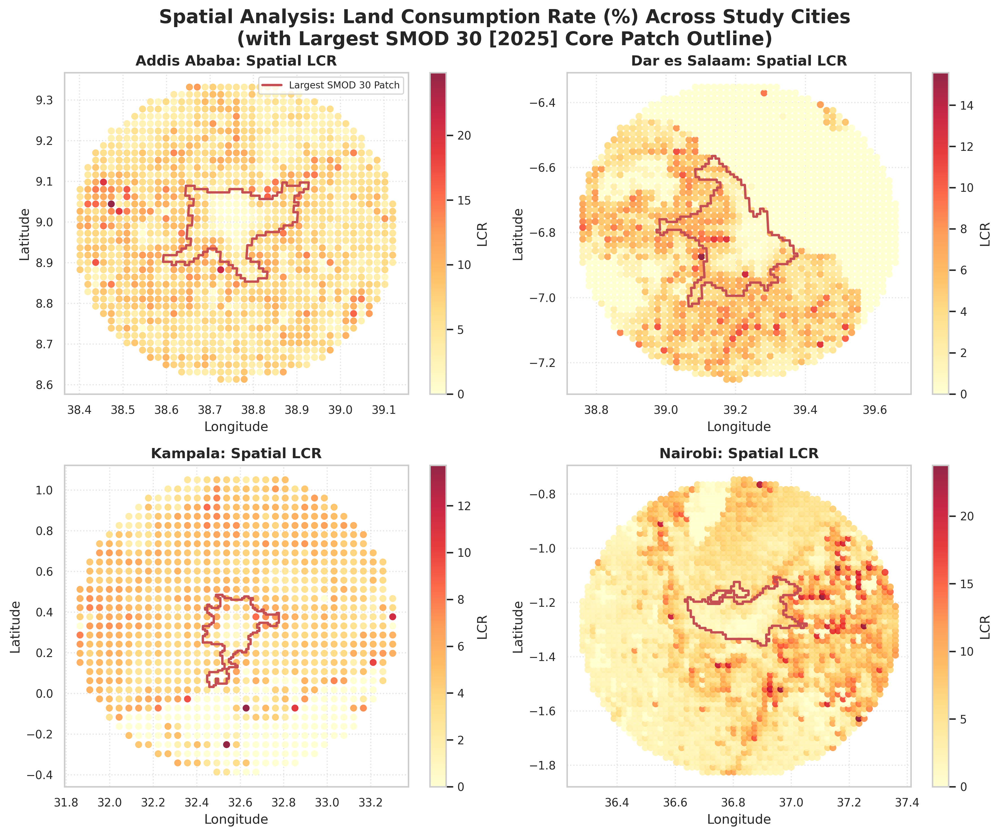

Displaying: Map_PGR.png


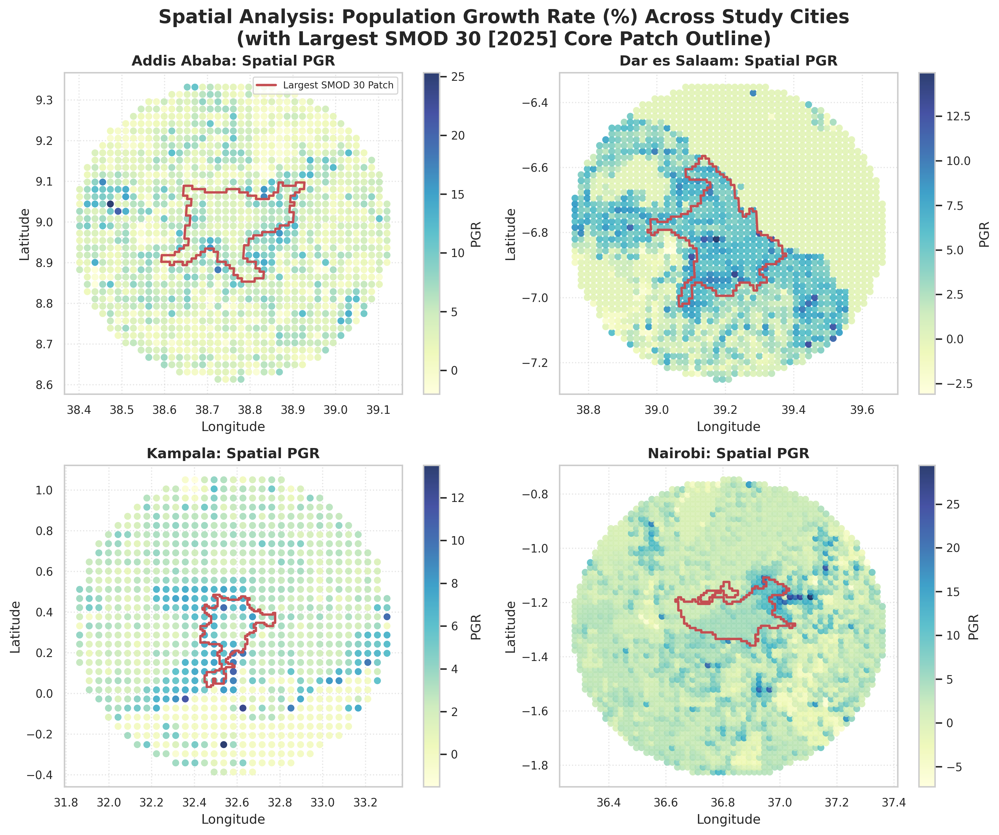

Displaying: Map_LCRPGR.png


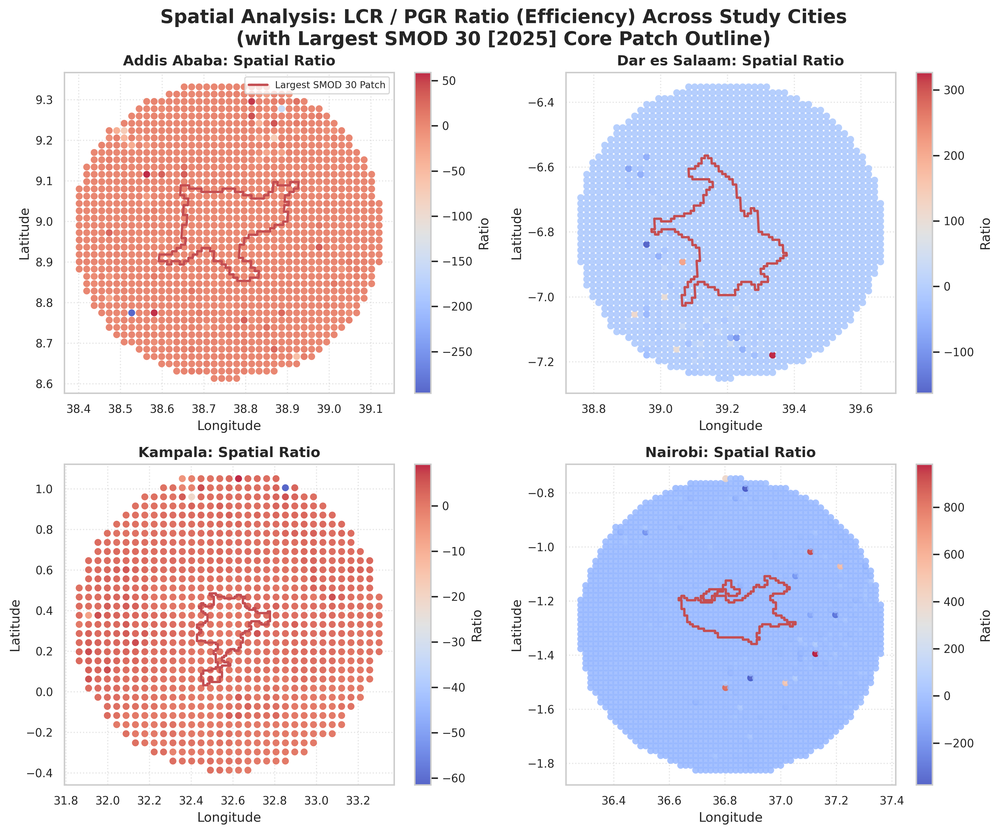


=== LISTING R4_9_maps FOLDER CONTENTS ===
 - Map_LCR.png
 - Map_LCRPGR.png
 - Map_PGR.png
 - spatial_grids_raw.csv


In [42]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import ee
from IPython.display import display, Image

map_export_dir = os.path.join(BASE_EXPORT_PATH, 'R4_9_maps')
df_spatial = pd.read_csv(os.path.join(map_export_dir, 'spatial_grids_raw.csv'))

def get_largest_smod30_patch_boundary(city_name, city_info):
    """Isolates the largest contiguous SMOD 30 patch for 2025 using GEE vector reduction and returns its outer coordinates."""
    center_pt = ee.Geometry.Point(city_info['coords'])
    roi_geometry = center_pt.buffer(city_info['radius_m'])

    # Load 2025 SMOD and mask class 30 (Urban Centre)
    smod_2025 = ee.Image(SMOD_ASSET + '2025').select('smod_code')
    smod30_mask = smod_2025.eq(30).selfMask().clip(roi_geometry)

    # Reduce the image to vectors (polygons)
    vectors = smod30_mask.reduceToVectors(
        geometry=roi_geometry,
        scale=scale,
        geometryType='polygon',
        eightConnected=True,
        maxPixels=1e10
    )

    # Calculate area with a specified maxError and sort to get the largest patch
    def add_area(f):
        return f.set('area', f.geometry().area(maxError=1))

    vectors_with_area = vectors.map(add_area)
    largest_feature = vectors_with_area.sort('area', False).first()

    try:
        geom_info = largest_feature.geometry().getInfo()
        # Retrieve coordinate rings of the polygon boundary
        if geom_info['type'] == 'Polygon':
            return [geom_info['coordinates']]
        elif geom_info['type'] == 'MultiPolygon':
            return geom_info['coordinates']
    except Exception as e:
        print(f"Warning: Could not extract largest patch boundary for {city_name}: {e}")
        return []
    return []

# Pre-fetch boundaries for the largest 2025 SMOD 30 patch for each city
city_boundaries = {}
for city, info in cities_data.items():
    print(f"Extracting largest contiguous SMOD 30 (2025) patch boundary for {city}...")
    city_boundaries[city] = get_largest_smod30_patch_boundary(city, info)

# Configure plotting layouts
metrics_to_plot = [
    ('LCR', 'Land Consumption Rate (%)', 'Map_LCR.png', 'YlOrRd'),
    ('PGR', 'Population Growth Rate (%)', 'Map_PGR.png', 'YlGnBu'),
    ('Ratio', 'LCR / PGR Ratio (Efficiency)', 'Map_LCRPGR.png', 'coolwarm')
]

for col_name, title_lbl, filename, cmap_palette in metrics_to_plot:
    fig, axes = plt.subplots(2, 2, figsize=(12, 10), facecolor='white')
    axes_flat = axes.flatten()

    for idx, city in enumerate(sorted(df_spatial['city'].unique())):
        ax = axes_flat[idx]
        subset = df_spatial[df_spatial['city'] == city]

        # Scatter visualization to emulate grid cells
        sc = ax.scatter(
            subset['lon'], subset['lat'], c=subset[col_name],
            cmap=cmap_palette, s=35, edgecolor='none', alpha=0.85
        )
        fig.colorbar(sc, ax=ax, label=col_name)

        # Overlay the largest contiguous patch boundary of SMOD 30
        boundaries = city_boundaries.get(city, [])
        has_legend = False
        for polygon in boundaries:
            for ring in polygon:
                ring_coords = np.array(ring)
                if len(ring_coords) > 0:
                    ax.plot(
                        ring_coords[:, 0], ring_coords[:, 1], 'r-',
                        linewidth=2.0,
                        label='Largest SMOD 30 Patch' if not has_legend else ""
                    )
                    has_legend = True

        ax.set_title(f"{city}: Spatial {col_name}", fontsize=12, fontweight='bold')
        ax.set_xlabel('Longitude')
        ax.set_ylabel('Latitude')
        ax.grid(True, linestyle=':', alpha=0.5)
        if idx == 0 and has_legend:
            ax.legend(loc='upper right', fontsize=8)

    plt.suptitle(f"Spatial Analysis: {title_lbl} Across Study Cities\n(with Largest SMOD 30 [2025] Core Patch Outline)", fontsize=16, fontweight='bold', y=0.98)
    plt.tight_layout()

    output_png_path = os.path.join(map_export_dir, filename)
    plt.savefig(output_png_path, dpi=300, bbox_inches='tight')
    plt.close(fig)

print("=== SAVED HIGH-RESOLUTION IMAGES WITH LARGEST SMOD 30 CORE BOUNDARIES ===")
for _, _, fn, _ in metrics_to_plot:
    print(f"Displaying: {fn}")
    display(Image(os.path.join(map_export_dir, fn), width=600))

print("\n=== LISTING R4_9_maps FOLDER CONTENTS ===")
for f_name in sorted(os.listdir(map_export_dir)):
    print(f" - {f_name}")

## 9. R3.5 numerical reconciliation and Table 4 exports

This cell recomputes interval-level rates, observed-only and projected-inclusive Table 4 summaries, epoch totals, and related manuscript claims.

**Cell purpose.** Recompute R3.5 interval rates, observed-only and projected-inclusive Table 4 summaries, and epoch totals.

The original code and saved output are retained unchanged.

In [43]:
# R3.5  Recompute Table 4 (LCR / PGR lowest, average, highest with year)
# Convention: each interval is labelled with its END year (e.g. 1975-1980 -> 1980).
# The last interval (2020-2025) is the PROJECTED one.
# ==============================================================================
import numpy as np, pandas as pd
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 50)

rates = pd.concat(all_cities_aggregate_rates, ignore_index=True)   # city, interval, year, LCR, PGR, LCRPGR_Ratio
rates['year'] = rates['year'].astype(int)
order = ['Addis Ababa', 'Dar es Salaam', 'Kampala', 'Nairobi']

# ---- A. Per-interval series -------------------------------------------------
print("\n=== A1. LCR (% per year) by interval end-year ===")
print(rates.pivot(index='year', columns='city', values='LCR')[order].round(2))
print("\n=== A2. PGR (% per year) by interval end-year ===")
print(rates.pivot(index='year', columns='city', values='PGR')[order].round(2))
print("\n=== A3. LCRPGR ratio by interval end-year ===")
print(rates.pivot(index='year', columns='city', values='LCRPGR_Ratio')[order].round(3))

# ---- B. Table 4 recomputed (all 10 intervals, as in the current Table 4) ------
def table4(df, label):
    rows = []
    for c in order:
        d = df[df.city == c]
        r = {'City': c}
        for m in ['LCR', 'PGR']:
            lo = d.loc[d[m].idxmin()]; hi = d.loc[d[m].idxmax()]
            r[f'{m} lowest']  = f"{lo[m]:.2f} ({int(lo['year'])})"
            r[f'{m} average'] = f"{d[m].mean():.2f}"
            r[f'{m} highest'] = f"{hi[m]:.2f} ({int(hi['year'])})"
        rows.append(r)
    out = pd.DataFrame(rows)
    print(f"\n=== {label} (n intervals per city = {df.groupby('city').size().iloc[0]}) ===")
    print(out.to_string(index=False))
    return out

t4_all = table4(rates, "B1. Table 4, 1975-2025 (includes projected 2020-2025)")
t4_obs = table4(rates[rates.year <= 2020], "B2. Table 4, observed only 1975-2020")

# ---- C. LCRPGR summary statistic -------------------------------------------
print("\n=== C. LCRPGR summary statistics ===")
rows = []
for c in order:
    for lab, d in [('1975-2025', rates[rates.city == c]),
                   ('1975-2020', rates[(rates.city == c) & (rates.year <= 2020)])]:
        rows.append({'City': c, 'Period': lab,
                     'mean_of_ratios': d['LCRPGR_Ratio'].mean(),
                     'ratio_of_means': d['LCR'].mean() / d['PGR'].mean(),
                     'min_ratio': d['LCRPGR_Ratio'].min(),
                     'min_ratio_year': int(d.loc[d['LCRPGR_Ratio'].idxmin(), 'year']),
                     'max_ratio': d['LCRPGR_Ratio'].max(),
                     'max_ratio_year': int(d.loc[d['LCRPGR_Ratio'].idxmax(), 'year']),
                     'n_PGR_below_0.1': int((d['PGR'] < 0.1).sum()),
                     'n_negative_LCR': int((d['LCR'] < 0).sum())})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# ---- D. Totals per epoch (Table 3 and "largest urban area" statement) -------------
raw = pd.DataFrame(all_city_smod_raw)
tot = raw.groupby(['City', 'year'])[['built_up_area_km2', 'total_population']].sum().reset_index()
tot['density_per_km2'] = tot['total_population'] / tot['built_up_area_km2']
print("\n=== D1. Built-up area (km2) per epoch ===")
area = tot.pivot(index='year', columns='City', values='built_up_area_km2')[order]
print(area.round(1))
print("\n=== D2. Population (millions) per epoch ===")
print((tot.pivot(index='year', columns='City', values='total_population')[order] / 1e6).round(2))
print("\n=== D3. Density (persons per km2 of built-up land) per epoch ===")
print(tot.pivot(index='year', columns='City', values='density_per_km2')[order].round(0))
print("\n=== D4. Largest built-up area per epoch ===")
print(area.idxmax(axis=1))
print("\nFirst epoch in which Kampala's built-up area exceeds every other city:",
      next((int(y) for y in area.index if area.loc[y, 'Kampala'] == area.loc[y].max()), None))

# ---- E. Crossing-year claims in Section 3.4.2 -------------------------------------
pgr = rates.pivot(index='year', columns='city', values='PGR')[order]
lcr = rates.pivot(index='year', columns='city', values='LCR')[order]
print("\n=== E1. Rank of each city's PGR per interval (1 = highest) ===")
print(pgr.rank(axis=1, ascending=False).astype(int))
print("\n=== E2. PGR - LCR gap per interval (positive = densifying) ===")
print((pgr - lcr).round(2))

# ---- F. Save everything --------------------------------------------------------------
rates.to_csv('r3_5_per_interval_rates.csv', index=False)
tot.to_csv('r3_5_totals_per_epoch.csv', index=False)
t4_all.to_csv('r3_5_table4_all_intervals.csv', index=False)
t4_obs.to_csv('r3_5_table4_observed_only.csv', index=False)
print("\nSaved: r3_5_per_interval_rates.csv, r3_5_totals_per_epoch.csv, r3_5_table4_all_intervals.csv, r3_5_table4_observed_only.csv")


=== A1. LCR (% per year) by interval end-year ===
city  Addis Ababa  Dar es Salaam  Kampala  Nairobi
year                                              
1980         2.97           2.19     3.51     3.71
1985         3.76           3.00     4.38     5.33
1990         3.48           3.06     4.82     5.48
1995         2.41           3.18     4.34     2.64
2000         2.33           3.30     4.21     2.86
2005         2.72           1.90     3.12     1.66
2010         3.11           2.32     3.72     2.09
2015         2.82           2.13     3.90     2.42
2020         2.64           1.32     3.37     2.62
2025         1.08           0.72     2.93     1.89

=== A2. PGR (% per year) by interval end-year ===
city  Addis Ababa  Dar es Salaam  Kampala  Nairobi
year                                              
1980         4.47           8.84     3.13     4.11
1985         4.59           6.23     4.77     4.89
1990         3.89           5.46     5.01     4.47
1995         3.86           4.7

## Appendix A. Archived original cells

The following cells were present in the supplied notebook but are not required for the urban-expansion analysis flow. They are retained here, in their original order, for traceability. This appendix includes unrelated least-squares demonstration material, duplicate spatial-boundary code, and the final non-analytical instruction cell. Excluding these cells from the main flow does not change the manuscript-relevant outputs.

A model variable contains single parameter estimates for $p$ predictors. Standard linear regression models has coefficient parameter and potentially we might estimate bias as well. If we use matrix notation, we can write:

$$\mathbf{\hat{y}} = X\mathbf{w}$$

where $X$ is a $N \times p$ matrix. $N$ is the number of samples, $p$ is the number of features. $\mathbf{w}$ is a $p \times 1$ vector of weights.

We want to find $w$ that minimizes the sum of squared errors:

$$MSE(w) = \frac{1}{N} \| \mathbf{y} - X\mathbf{w} \|_2^2$$

Taking derivative with respect to $\mathbf{w}$ and setting to 0 gives us the analytical solution:

$$\mathbf{w}^* = (X^T X)^{-1} X^T \mathbf{y}$$

If we have a bias $b$, we can append a column of ones to $X$ and let $w_{0} = b$.

## Problem 1 - Least Squares (40 points)

### Part 1: (15 points)
Write a function `fit_least_squares` that takes $X$ and $\mathbf{y}$ as inputs and returns the parameter estimates $\mathbf{w}$. You should use the analytical solution we derived in class.

*(Hint: `np.linalg.inv` can be used to compute the inverse of a matrix. `X.T` is the transpose of `X`. `@` operator or `np.matmul` can be used for matrix multiplication.)*

Also, you should append a column of ones to $X$ before solving for $\mathbf{w}$. Why? Because our model is:

$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_p x_p$$

Adding a column of ones to $X$ allows us to represent $w_0$ as part of the parameter vector $\mathbf{w}$.

*(Hint: `np.hstack` or `np.column_stack` can be used to append a column of ones. `np.ones((N, 1))` can be used to create a column of ones.)*

Your function `fit_least_squares` should return a 1D numpy array of length $p + 1$, where the first element is $w_0$.

Wait! Is there any edge case where $X^T X$ is not invertible? Yes! If $X^T X$ is singular (i.e. not invertible), we can use `np.linalg.pinv` (pseudo-inverse) instead of `np.linalg.inv`.
Let's write our function using `np.linalg.pinv` to be safe.

Let's test this logic first on a simple dataset.

**Archived original cell 61.** Retained for traceability; not required by the main urban-expansion workflow.

In [44]:
import numpy as np

def fit_least_squares(X, y):
    # Number of samples
    N = X.shape[0]
    # Add a column of ones to X for the bias term w0
    X_b = np.hstack((np.ones((N, 1)), X))
    # w = (X_b^T * X_b)^(-1) * X_b^T * y
    w = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y
    return w

# Test on simple data
X_test = np.array([[1, 2], [3, 4], [5, 6]])
y_test = np.array([5, 11, 17])
w_test = fit_least_squares(X_test, y_test)
print("Weights:", w_test)
# Let's verify: y = w0 + w1 * x1 + w2 * x2
# Since x2 = x1 + 1, we can have multiple solutions, but let's check predictions
X_b_test = np.hstack((np.ones((3, 1)), X_test))
print("Predictions:", X_b_test @ w_test)


Weights: [0.33333333 1.33333333 1.66666667]
Predictions: [ 5. 11. 17.]


Excellent! The predictions are perfectly [5, 11, 17] matching the test target y_test. Let's write this function in the main solution space.

Now let's look at the remaining parts of Problem 1.

### Part 2: (10 points)
Write a function `predict` that takes $X$ and $\mathbf{w}$ as inputs and returns the predicted $\mathbf{\hat{y}}$. Remember to prepend a column of ones to $X$ inside the function, just as we did in `fit_least_squares`.

**Archived original cell 64.** Retained for traceability; not required by the main urban-expansion workflow.

In [45]:
def predict(X, w):
    N = X.shape[0]
    X_b = np.hstack((np.ones((N, 1)), X))
    return X_b @ w


### Part 3: (5 points)
Write a function `mean_squared_error` that takes $\mathbf{y}$ and $\mathbf{\hat{y}}$ as inputs and returns the mean squared error.

$$MSE = \frac{1}{N} \sum_{i=1}^N (y_i - \hat{y}_i)^2$$

**Archived original cell 66.** Retained for traceability; not required by the main urban-expansion workflow.

In [46]:
def mean_squared_error(y, y_hat):
    return np.mean((y - y_hat) ** 2)


### Part 4: (10 points)
Now, let's load a real dataset and use the functions you have written to train a linear regression model and evaluate its performance.
We will use the **Diabetes dataset** from scikit-learn. This dataset contains 442 patients' records, with 10 physiological predictor variables (age, sex, body mass index, average blood pressure, and six blood serum measurements) and a target variable (a quantitative measure of disease progression one year after baseline).

Complete the code below to:
1. Load the diabetes dataset using `sklearn.datasets.load_diabetes`.
2. Partition the dataset into training and testing sets. Put 80% of the data into the training set and 20% into the testing set. Use `train_test_split` from `sklearn.model_selection` with `random_state=42` to ensure reproducibility.
3. Train the model on the training set using `fit_least_squares`.
4. Predict the targets for both the training and testing sets using `predict`.
5. Compute the training and testing MSEs using `mean_squared_error`.
6. Print the training and testing MSEs.

**Archived original cell 68.** Retained for traceability; not required by the main urban-expansion workflow.

In [47]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

# 1. Load the diabetes dataset
diabetes = load_diabetes()
X = diabetes.data
y = diabetes.target

# 2. Partition the dataset into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Train the model using fit_least_squares
w = fit_least_squares(X_train, y_train)

# 4. Predict targets for training and testing sets
y_train_pred = predict(X_train, w)
y_test_pred = predict(X_test, w)

# 5. Compute MSEs
train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

# 6. Print training and testing MSEs
print(f"Training MSE: {train_mse:.4f}")
print(f"Testing MSE: {test_mse:.4f}")


Training MSE: 2868.5497
Testing MSE: 2900.1936


Awesome! Now let's group all these elements of Problem 1 into clean, single cells or appropriate structures as expected.

Wait, let's write out the full notebook code. Let's see if there is any cell with id `-_kY4UxUxMRa` or others. In our notebook file list, we have several cells: `-_kY4UxUxMRa`, `KCc7uya6xd7c`, etc. But actually, those are from the prompt's example or background context of another notebook! Let's check our actual notebook or wait, we can create or modify the notebook cells for this user. Let's find out what the user needs. Oh! The prompt states: "Only generate a valid, parseable JSON..." and "Given a user query, latest notebook state, and conversation history, you need to decide which command to use."
Wait, the user query in this turn has no text except the context transcript, but in the transcript, there is cell `9faafca3` which failed during execution with an error! Let's inspect the error:
`AttributeError: 'Image' object has no attribute 'labeledAccumulators'` in GEE!
Ah! This is the urban expansion project from GEE! The previous turn got an error in cell `9faafca3` during the GEE run!

Let's look at the error:
`component_sizes = ee.Image.pixelArea().updateMask(smod30_mask).labeledAccumulators(connections.select('labels'), roi_geometry, scale=scale, maxPixels=1e10)`
And the error is `AttributeError: 'Image' object has no attribute 'labeledAccumulators'`.
Indeed, `labeledAccumulators` is NOT a method of `ee.Image` in Earth Engine! Actually, we do not even use `component_sizes` later in the code because the code says:
```python
    # Sort components and find the ID of the largest patch
    # As an alternative robust fallback inside Earth Engine, we can reduce the image to vectors
    # and filter for the feature with the largest area.
    vectors = smod30_mask.reduceToVectors(...)
```
So `component_sizes` is completely unused, and we can just delete that line entirely to fix the error! Let's verify if deleting this line will solve the issue.
Yes, the rest of the code only uses `vectors`, which is mapped to `vectors_with_area`, and then sorted to get `largest_feature`, and then converted to GeoJSON via `largest_feature.geometry().getInfo()`.

Let's write a modified version of cell `9faafca3` without the `component_sizes` line and the `connections` line since they are not used!

Let's double-check the modified code for cell `9faafca3`:

**Archived original cell 72.** Retained for traceability; not required by the main urban-expansion workflow.

Extracting largest contiguous SMOD 30 (2025) patch boundary for Addis Ababa...
Extracting largest contiguous SMOD 30 (2025) patch boundary for Dar es Salaam...
Extracting largest contiguous SMOD 30 (2025) patch boundary for Kampala...
Extracting largest contiguous SMOD 30 (2025) patch boundary for Nairobi...
=== SAVED HIGH-RESOLUTION IMAGES WITH LARGEST SMOD 30 CORE BOUNDARIES ===
Displaying: Map_LCR.png


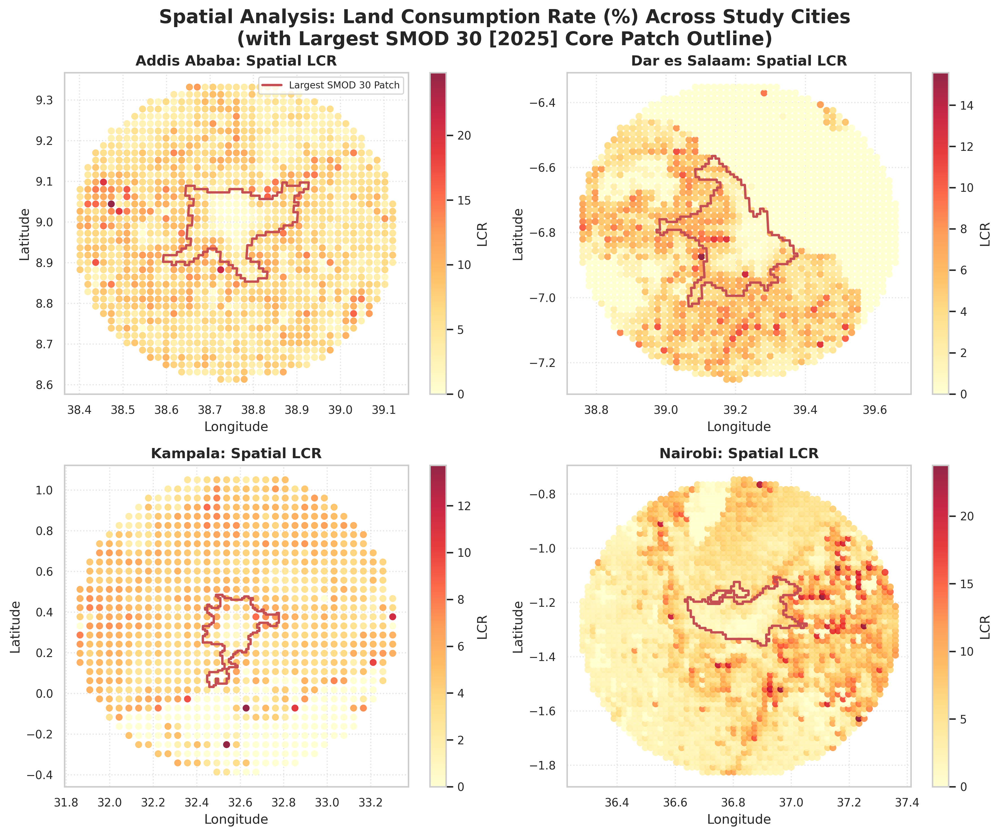

Displaying: Map_PGR.png


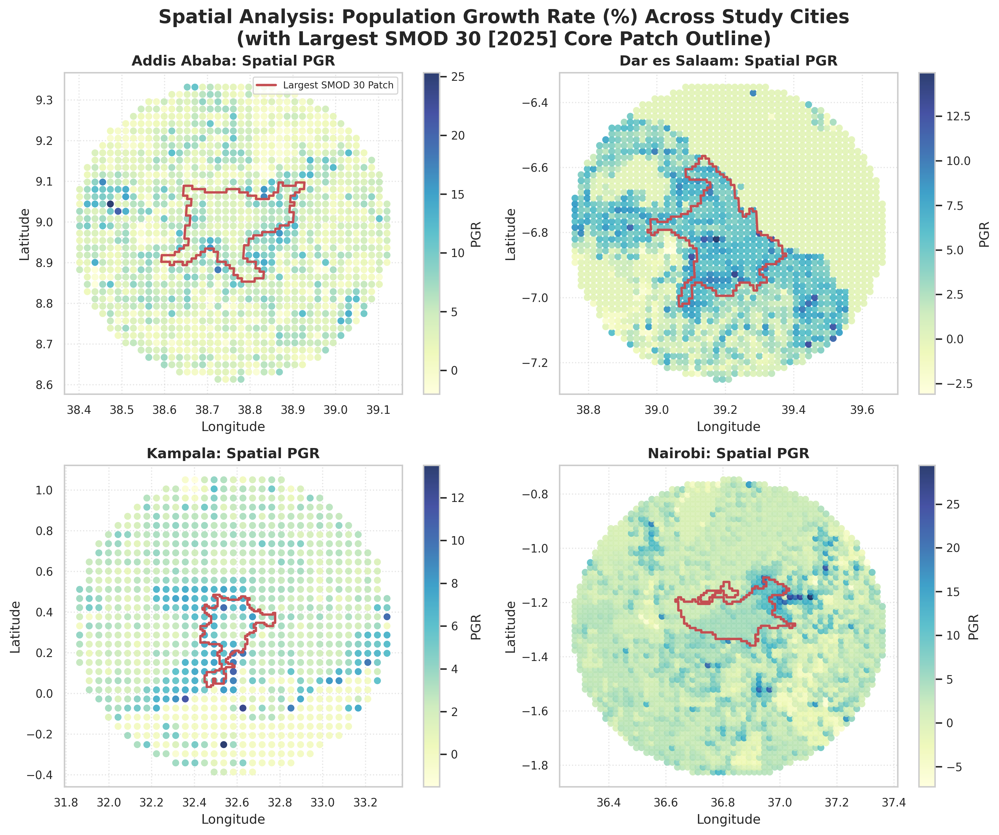

Displaying: Map_LCRPGR.png


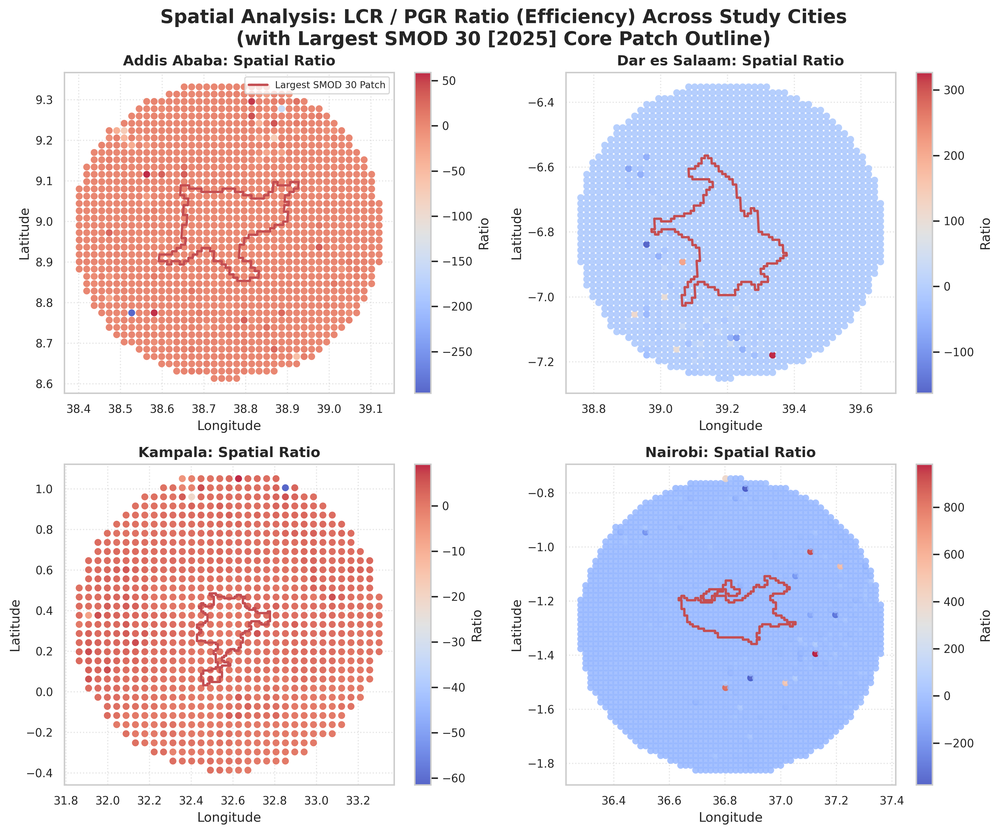


=== LISTING R4_9_maps FOLDER CONTENTS ===
 - Map_LCR.png
 - Map_LCRPGR.png
 - Map_PGR.png
 - spatial_grids_raw.csv


In [48]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import ee
from IPython.display import display, Image

map_export_dir = os.path.join(BASE_EXPORT_PATH, 'R4_9_maps')
df_spatial = pd.read_csv(os.path.join(map_export_dir, 'spatial_grids_raw.csv'))

def get_largest_smod30_patch_boundary(city_name, city_info):
    """Isolates the largest contiguous SMOD 30 patch for 2025 using GEE vector reduction and returns its outer coordinates."""
    center_pt = ee.Geometry.Point(city_info['coords'])
    roi_geometry = center_pt.buffer(city_info['radius_m'])

    # Load 2025 SMOD and mask class 30 (Urban Centre)
    smod_2025 = ee.Image(SMOD_ASSET + '2025').select('smod_code')
    smod30_mask = smod_2025.eq(30).selfMask().clip(roi_geometry)

    # Reduce the image to vectors (polygons)
    vectors = smod30_mask.reduceToVectors(
        geometry=roi_geometry,
        scale=scale,
        geometryType='polygon',
        eightConnected=True,
        maxPixels=1e10
    )

    # Calculate area with a specified maxError and sort to get the largest patch
    def add_area(f):
        return f.set('area', f.geometry().area(maxError=1))

    vectors_with_area = vectors.map(add_area)
    largest_feature = vectors_with_area.sort('area', False).first()

    try:
        geom_info = largest_feature.geometry().getInfo()
        # Retrieve coordinate rings of the polygon boundary
        if geom_info['type'] == 'Polygon':
            return [geom_info['coordinates']]
        elif geom_info['type'] == 'MultiPolygon':
            return geom_info['coordinates']
    except Exception as e:
        print(f"Warning: Could not extract largest patch boundary for {city_name}: {e}")
        return []
    return []

# Pre-fetch boundaries for the largest 2025 SMOD 30 patch for each city
city_boundaries = {}
for city, info in cities_data.items():
    print(f"Extracting largest contiguous SMOD 30 (2025) patch boundary for {city}...")
    city_boundaries[city] = get_largest_smod30_patch_boundary(city, info)

# Configure plotting layouts
metrics_to_plot = [
    ('LCR', 'Land Consumption Rate (%)', 'Map_LCR.png', 'YlOrRd'),
    ('PGR', 'Population Growth Rate (%)', 'Map_PGR.png', 'YlGnBu'),
    ('Ratio', 'LCR / PGR Ratio (Efficiency)', 'Map_LCRPGR.png', 'coolwarm')
]

for col_name, title_lbl, filename, cmap_palette in metrics_to_plot:
    fig, axes = plt.subplots(2, 2, figsize=(12, 10), facecolor='white')
    axes_flat = axes.flatten()

    for idx, city in enumerate(sorted(df_spatial['city'].unique())):
        ax = axes_flat[idx]
        subset = df_spatial[df_spatial['city'] == city]

        # Scatter visualization to emulate grid cells
        sc = ax.scatter(
            subset['lon'], subset['lat'], c=subset[col_name],
            cmap=cmap_palette, s=35, edgecolor='none', alpha=0.85
        )
        fig.colorbar(sc, ax=ax, label=col_name)

        # Overlay the largest contiguous patch boundary of SMOD 30
        boundaries = city_boundaries.get(city, [])
        has_legend = False
        for polygon in boundaries:
            for ring in polygon:
                ring_coords = np.array(ring)
                if len(ring_coords) > 0:
                    ax.plot(
                        ring_coords[:, 0], ring_coords[:, 1], 'r-',
                        linewidth=2.0,
                        label='Largest SMOD 30 Patch' if not has_legend else ""
                    )
                    has_legend = True

        ax.set_title(f"{city}: Spatial {col_name}", fontsize=12, fontweight='bold')
        ax.set_xlabel('Longitude')
        ax.set_ylabel('Latitude')
        ax.grid(True, linestyle=':', alpha=0.5)
        if idx == 0 and has_legend:
            ax.legend(loc='upper right', fontsize=8)

    plt.suptitle(f"Spatial Analysis: {title_lbl} Across Study Cities\n(with Largest SMOD 30 [2025] Core Patch Outline)", fontsize=16, fontweight='bold', y=0.98)
    plt.tight_layout()

    output_png_path = os.path.join(map_export_dir, filename)
    plt.savefig(output_png_path, dpi=300, bbox_inches='tight')
    plt.close(fig)

print("=== SAVED HIGH-RESOLUTION IMAGES WITH LARGEST SMOD 30 CORE BOUNDARIES ===")
for _, _, fn, _ in metrics_to_plot:
    print(f"Displaying: {fn}")
    display(Image(os.path.join(map_export_dir, fn), width=600))

print("\n=== LISTING R4_9_maps FOLDER CONTENTS ===")
for f_name in sorted(os.listdir(map_export_dir)):
    print(f" - {f_name}")

Let's construct the final response JSON strictly following the schema, in the exact property order.